# Аналитика Маркета ВКонтакте
### Полный разбор датасета отборочного этапа CaseChamp 2026

**Период данных:** 1–30 сентября 2026 года.
**Объект анализа:** Маркет ВКонтакте и Партнёр 1 — два сегмента товарной витрины внутри ВКонтакте.
**Единица наблюдения в таблице «Бизнесы»:** сообщество (бизнес), а не пользователь.

---

## Что внутри ноутбука

| № | Раздел | Что показывает |
|---|--------|----------------|
| 0 | Методология и паспорт данных | структура файла, качество данных, ограничения |
| 1 | Таблица 1 «Бизнесы» | 9 754 сообщества: тематики, инструменты торговли, контент, заказы, реклама |
| 2 | Таблица 2 «Итоги» | воронка Маркета и Партнёра, конверсии, юнит-экономика |
| 3 | Таблица 3 «По дням» | ежедневная динамика 30 дней, устойчивость, будни/выходные |
| 4 | Таблица 4 «Источники» | откуда приходят открытия карточки |
| 5 | Таблица 5 «Категории» | спрос и заказы по товарным категориям |
| 6 | Таблица 6 «Покупатели» | пол и возраст, структура спроса |
| 7 | Таблица 7 «Регионы» | география покупателей и концентрация |
| 8 | Синтез и роль Маркета | двухмодельная структура, роль ВКонтакте, выводы, рекомендации |

**Как читать ноутбук.** Каждый аналитический блок состоит из двух ячеек: сначала код и график (или таблица), затем — **легенда**: что изображено, как читать оси, какие выводы следуют. Все графики построены на данных файла; никакие внешние источники для расчётов не используются.

## 0. Методология и паспорт данных

### 0.1. Источник и способ загрузки

Файл `VK_CaseChamp_2026_Отборочный_этап_Датасет (1).xlsx` содержит 7 листов. Ноутбук читает его напрямую из рабочей папки, поэтому все расчёты воспроизводимы: достаточно запустить ячейки сверху вниз.

### 0.2. Паспорт листов

| Лист | Строк | Колонок | Содержание |
|------|------:|--------:|------------|
| Бизнесы | 9 754 | 28 | сообщества: тематика, тип, подписчики, контент, инструменты, заказы, GMV, реклама |
| Маркет Вконтакте — итоги | 26 | 4 | сводные метрики Маркета и Партнёра за месяц + общие метрики |
| Маркет Вконтакте — по дням | 30 | 19 | ежедневная динамика за сентябрь 2026 |
| Маркет Вконтакте — источники | 7 | 5 | открытия карточки по источникам трафика |
| Маркет Вконтакте — категории | 18 | 5 | открытия и заказы по категориям |
| Покупатели | 15 | 6 | покупатели и заказы по полу и возрасту |
| Покупатели по регионам | 89 | 5 | покупатели и заказы по регионам РФ |

### 0.3. Принципы анализа

1. **Разделяем уровни.** Таблица 1 — выборка сообществ (микроуровень). Таблицы 2–5 — агрегаты всего Маркета (макроуровень). Их нельзя складывать напрямую: 9 754 сообщества не равны всей базе Маркета.
2. **Считаем производные метрики сами.** Конверсии, доли, юнит-экономика пересчитаны из абсолютных значений, а не взяты на веру из округлённых ячеек.
3. **Фиксируем аномалии.** В данных есть несогласованности между листами — они вынесены в отдельный блок 0.4 и учитываются в выводах.
4. **Не подменяем причинность корреляцией.** Все выводы о «драйверах» сформулированы как гипотезы, если нет прямого эксперимента.

In [1]:
# --- Импорты и единый визуальный стиль -------------------------------------
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import FancyBboxPatch
import seaborn as sns
from IPython.display import display

warnings.filterwarnings('ignore')

# Цветовая схема: ВКонтакте — синий, Партнёр 1 — оранжевый
C_VK   = '#0077FF'
C_PT   = '#FF7A00'
C_ACC  = '#6C4CF1'
C_TEAL = '#00B3A4'
C_GRAY = '#8A94A6'
C_RED  = '#EB5757'
PALETTE = [C_VK, C_PT, C_ACC, C_TEAL, '#F2C94C', C_RED, '#2D9CDB', '#27AE60', '#9B51E0', '#BDBDBD']

plt.rcParams.update({
    'figure.dpi': 150,
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelsize': 10,
    'axes.edgecolor': '#D0D5DD',
    'axes.linewidth': 0.9,
    'axes.grid': True,
    'grid.color': '#E4E7EC',
    'grid.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'legend.frameon': False,
    'xtick.color': '#344054',
    'ytick.color': '#344054',
    'text.color': '#101828',
})

def fnum(x, d=1):
    # Число в человекочитаемом виде: 1,23 млрд
    x = float(x); a = abs(x)
    for div, suf in ((1e9, 'млрд'), (1e6, 'млн'), (1e3, 'тыс.')):
        if a >= div:
            return f"{x/div:.{d}f}".replace('.', ',') + ' ' + suf
    if a >= 100:
        return f"{x:,.0f}".replace(',', ' ')
    return f"{x:.{d}f}".replace('.', ',')

def fmoney(x, d=1):
    return fnum(x, d) + ' ₽'

def fpct(x, d=1):
    return f"{x:.{d}f}".replace('.', ',') + '%'

def rfmt(v, p=None):
    return fnum(v, 1)

def subtitle(ax, text):
    ax.text(0, 1.015, text, transform=ax.transAxes, fontsize=9,
            color='#667085', va='bottom', ha='left')

def note(fig, text):
    fig.text(0.005, -0.02, text, fontsize=8, color='#667085', ha='left')

print('Стиль и помощники загружены. Matplotlib', matplotlib.__version__, '| pandas', pd.__version__)

Стиль и помощники загружены. Matplotlib 3.11.2 | pandas 3.0.6


In [2]:
# --- Загрузка данных --------------------------------------------------------
BASE = os.getcwd()
cands = sorted(glob.glob(os.path.join(BASE, '*.xlsx')))
if not cands:
    cands = sorted(glob.glob(os.path.join(BASE, '**', '*.xlsx'), recursive=True))
assert cands, 'Excel-файл не найден в рабочей папке'
XLSX = cands[0]
print('Файл:', os.path.basename(XLSX))

S = pd.read_excel(XLSX, sheet_name=None)

biz = S['Бизнесы'].copy()
tot = S['Маркет Вконтакте — итоги'].copy()
day = S['Маркет Вконтакте — по дням'].copy()
src = S['Маркет Вконтакте — источники'].copy()
cat = S['Маркет Вконтакте — категории'].copy()
dem = S['Покупатели'].copy()
reg = S['Покупатели по регионам'].copy()

day['Дата'] = pd.to_datetime(day['Дата'])

for name, df in [('Бизнесы', biz), ('Итоги', tot), ('По дням', day),
                 ('Источники', src), ('Категории', cat),
                 ('Покупатели', dem), ('Регионы', reg)]:
    print(f'{name:<12} {df.shape[0]:>5} строк × {df.shape[1]:>2} колонок')

Файл: VK_CaseChamp_2026_Отборочныи__этап_Датасет (1).xlsx


Бизнесы       9754 строк × 28 колонок
Итоги           26 строк ×  4 колонок
По дням         30 строк × 19 колонок
Источники        7 строк ×  5 колонок
Категории       18 строк ×  5 колонок
Покупатели      15 строк ×  6 колонок
Регионы         89 строк ×  5 колонок


**Легенда к загрузке.** Ноутбук сам находит Excel-файл в рабочей папке и читает все семь листов в отдельные таблицы. Дата на листе «По дням» переведена в формат `datetime`, чтобы можно было строить временные ряды и считать будни/выходные. Имена переменных: `biz` — сообщества, `tot` — сводные итоги, `day` — дневная динамика, `src` — источники, `cat` — категории, `dem` — пол/возраст, `reg` — регионы.

In [3]:
# --- Аудит: размеры, типы, пропуски ---------------------------------------
audit = pd.DataFrame({
    'Лист': list(S.keys()),
    'Строк': [S[k].shape[0] for k in S.keys()],
    'Колонок': [S[k].shape[1] for k in S.keys()],
    'Числовых колонок': [S[k].select_dtypes('number').shape[1] for k in S.keys()],
    'Текстовых колонок': [S[k].select_dtypes('object').shape[1] for k in S.keys()],
    'Пропусков, %': [round(S[k].isna().mean().mean()*100, 1) for k in S.keys()],
})
audit['Доля пропусков, %'] = audit.pop('Пропусков, %')
display(audit.style.hide(axis='index').format({'Доля пропусков, %': '{:.1f}'}))

miss = (biz.isna().sum().sort_values(ascending=False))
miss = miss[miss > 0].to_frame('Пропусков')
miss['Доля, %'] = (miss['Пропусков'] / len(biz) * 100).round(1)
print('\nПропуски в таблице «Бизнесы»:')
display(miss)

Лист,Строк,Колонок,Числовых колонок,Текстовых колонок,"Доля пропусков, %"
Бизнесы,9754,28,26,2,6.4
Маркет Вконтакте — итоги,26,4,0,4,35.6
Маркет Вконтакте — по дням,30,19,18,0,0.0
Маркет Вконтакте — источники,7,5,4,1,5.7
Маркет Вконтакте — категории,18,5,4,1,0.0
Покупатели,15,6,4,2,4.4
Покупатели по регионам,89,5,4,1,1.8



Пропуски в таблице «Бизнесы»:


,Пропусков,"Доля, %"
"Средний чек, ₽",9463,97.0
"Медианная цена товара, ₽",5412,55.5
Автор оригинального контента (оценка модели),2570,26.3


**Легенда к аудиту.** Таблица показывает размер и «разреженность» каждого листа. Ключевой вывод: почти все листы заполнены полностью, кроме таблицы «Бизнесы». Там пропуски не случайны, а содержательны:

- `Средний чек, ₽` отсутствует у **9 463 из 9 754** сообществ (97%) — потому что чек есть только у тех, кто реально получал заказы;
- `Медианная цена товара, ₽` отсутствует у 5 412 (55%) — у части сообществ нет каталога товаров;
- `Автор оригинального контента` отсутствует у 2 570 (26%) — это оценка модели, а не факт из анкеты.

Такие пропуски нельзя заполнять нулём: ноль означал бы «бесплатный товар», а не «нет данных». Поэтому в расчётах среднего чека и цены используются только непустые значения, а численность таких наблюдений указывается отдельно.

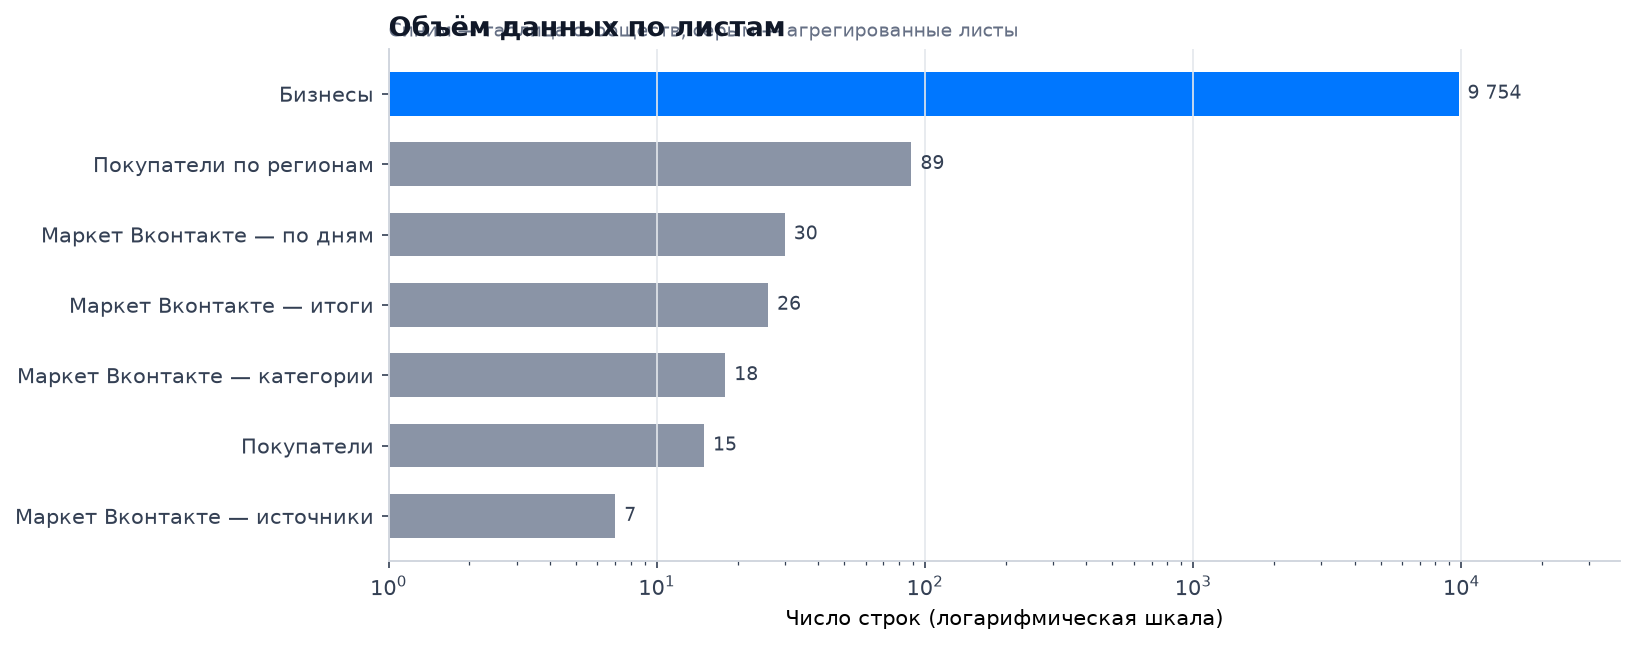

In [4]:
# --- Объём данных по листам -------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 4.4))
order = audit.sort_values('Строк')
bars = ax.barh(order['Лист'], order['Строк'], color=[C_VK if v > 1000 else C_GRAY for v in order['Строк']], height=0.62)
ax.set_xscale('log')
ax.set_xlabel('Число строк (логарифмическая шкала)')
ax.set_title('Объём данных по листам')
subtitle(ax, 'Синим — таблица сообществ, серым — агрегированные листы')
for b, v in zip(bars, order['Строк']):
    ax.text(v*1.08, b.get_y()+b.get_height()/2, f'{v:,}'.replace(',', ' '),
            va='center', fontsize=9, color='#344054')
ax.set_xlim(1, order['Строк'].max()*4)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к графику объёма.** По горизонтали — число строк, шкала логарифмическая, потому что разброс огромен: от 7 строк на листе «Источники» до 9 754 на листе «Бизнесы». Логарифм позволяет увидеть все листы одновременно. Вывод: основной массив данных — микроуровень сообществ; остальные листы компактные, но именно они дают макро-картину всего Маркета.

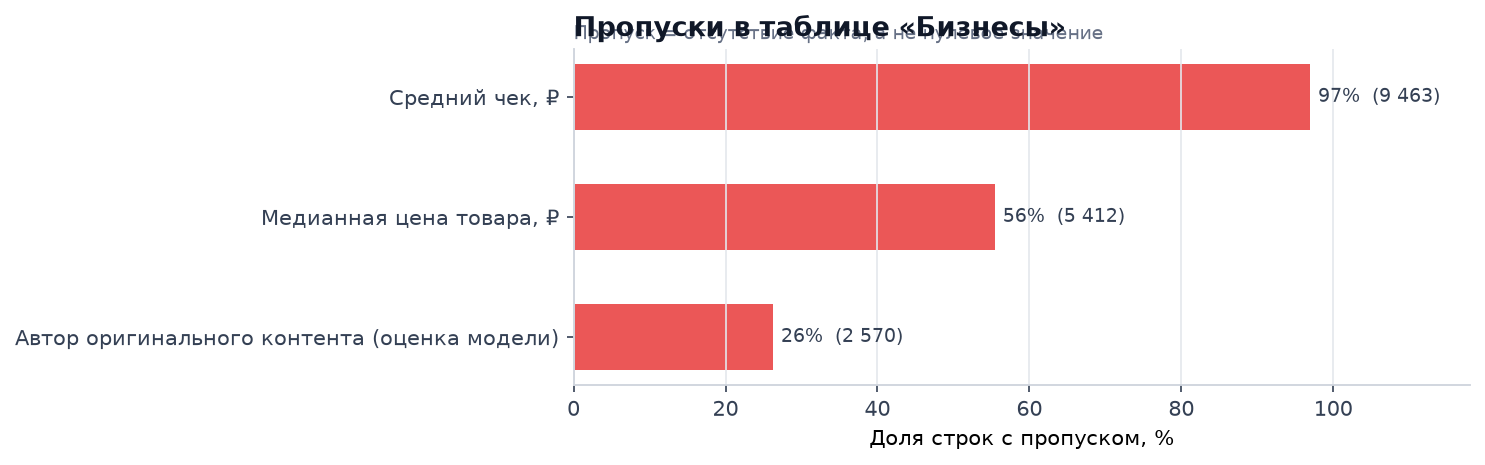

In [5]:
# --- Карта пропусков в «Бизнесах» -------------------------------------------
fig, ax = plt.subplots(figsize=(10, 3.2))
m = miss.sort_values('Пропусков')
bars = ax.barh(m.index, m['Доля, %'], color=C_RED, height=0.55)
ax.set_xlabel('Доля строк с пропуском, %')
ax.set_title('Пропуски в таблице «Бизнесы»')
subtitle(ax, 'Пропуск = отсутствие факта, а не нулевое значение')
for b, v, n in zip(bars, m['Доля, %'], m['Пропусков']):
    ax.text(v+1, b.get_y()+b.get_height()/2, f'{v:.0f}%  ({n:,})'.replace(',', ' '),
            va='center', fontsize=9, color='#344054')
ax.set_xlim(0, 118)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к карте пропусков.** Длина столбца — доля сообществ, у которых поле не заполнено; в скобках — абсолютное число. Читать так: «Средний чек» отсутствует у 97% сообществ, то есть заказы через чекаут в выборке — редкое событие. Это не дефект данных, а свойство генеральной совокупности: большинство сообществ не торгуют через чекаут вообще.

### 0.4. Ключевые оговорки о качестве данных

Перед содержательным анализом нужно зафиксировать шесть особенностей, которые влияют на интерпретацию:

1. **Дневные уникальные пользователи не суммируются.** На листе «По дням» `Видели товары (уник.)` в сумме даёт 717 млн, а в «Итогах» за 30 дней — 66,6 млн. Это нормально: один человек учитывается каждый день. Складывать дневные уникальные нельзя, сравнивать их между днями — можно.
2. **Таблица источников сходится с открытиями карточки — если не считать вложенную строку.** Сумма по шести каналам у Маркета — 193,5 млн, ровно как в «Итогах»; у Партнёра — 86,9 млн, тоже совпадает. Строка «в т.ч. из реферальных постов и клипов» (82,3 млн) — не отдельный канал, а детализация внутри источников: если прибавить её к остальным, получится 169,2 млн и задвоение. Поэтому доли считаем по шести каналам, а реферальную строку разбираем отдельно.
3. **Заказы по категориям больше итога.** Сумма заказов Маркета по категориям — 435 285 против 413 740 в «Итогах» (+5,2%). Причина — округление и служебные категории. Для долей это допустимо, для абсолютного итога — берём «Итоги».
4. **Служебные категории искажают конверсию.** «Другое» у Маркета: 29,1 млн открытий и 41 заказ. «Не определена» у Партнёра: 0 открытий и 117 818 заказов. Это технические корзины, их нельзя ставить в один ряд с товарными категориями.
5. **Регион «Не указан» — 36,7% покупателей Партнёра.** 1 065 094 из 2 901 162. Географические выводы по Партнёру поэтому условны; по Маркету доля неизвестных всего 1,8%.
6. **Оплаченные заказы есть только у Маркета.** 4 903 из 413 740 оформленных (1,19%). У Партнёра значение «—», поэтому сквозную оплату сравнивать нельзя.

Эти оговорки не отменяют анализ, но задают границы выводов: абсолютные уровни надёжны на уровне «Итогов», структура и доли — на уровне остальных листов.

## 1. Таблица 1 «Бизнесы»: микроуровень экосистемы

9 754 сообщества — это выборка бизнесов, которые ВКонтакте рассматривает как продавцов или потенциальных продавцов. Здесь видно, кто они, что публикуют, какие инструменты торговли подключили и кто реально доходит до заказа.

### 1.1. Описательные статистики

Ниже — сводка по ключевым количественным полям. Она задаёт масштаб: типичное сообщество небольшое, контент активный, но транзакции — редкость.

In [6]:
cols_desc = ['Число подписчиков', 'Посты за 30 дней', 'Клипы за 30 дней',
             'Посты с товаром за 30 дней', 'Клипы с товаром за 30 дней',
             'Просмотры обычного контента', 'Просмотры товарного контента',
             'Открытия карточки товара из контента', 'Число активных товаров в каталоге',
             'Заказы через чекаут', 'GMV через чекаут, ₽',
             'Средний чек, ₽', 'Траты на рекламу всего, ₽', 'Медианная цена товара, ₽']

desc = biz[cols_desc].describe(percentiles=[.25, .5, .75, .9, .99]).T
desc = desc[['count', 'mean', '50%', '75%', '90%', '99%', 'max']]
desc.columns = ['Наблюдений', 'Среднее', 'Медиана', '75-й пц', '90-й пц', '99-й пц', 'Максимум']
desc['Наблюдений'] = desc['Наблюдений'].astype(int)
display(desc.round(1).style.format('{:,.1f}'))

,Наблюдений,Среднее,Медиана,75-й пц,90-й пц,99-й пц,Максимум
Число подписчиков,"9,754.0","2,481.6",490.0,"1,700.0","4,900.0","36,000.0","300,000.0"
Посты за 30 дней,"9,754.0",18.1,2.0,9.0,22.0,209.9,"6,349.0"
Клипы за 30 дней,"9,754.0",2.3,0.0,1.0,6.0,30.0,792.0
Посты с товаром за 30 дней,"9,754.0",1.7,0.0,0.0,0.0,3.0,"4,400.0"
Клипы с товаром за 30 дней,"9,754.0",0.1,0.0,0.0,0.0,1.0,551.0
Просмотры обычного контента,"9,754.0","32,416.2","1,300.0","5,600.0","24,000.0","500,000.0","29,000,000.0"
Просмотры товарного контента,"9,754.0","1,883.0",0.0,0.0,25.0,"8,300.0","3,800,000.0"
Открытия карточки товара из контента,"9,754.0",5.4,0.0,0.0,0.0,13.0,"10,859.0"
Число активных товаров в каталоге,"9,754.0",41.3,0.0,8.0,43.0,674.5,"16,766.0"
Заказы через чекаут,"9,754.0",0.4,0.0,0.0,0.0,4.0,543.0


**Легенда к описательным статистикам.** Строки — метрики, столбцы — квантили распределения. Сравнение среднего и медианы показывает асимметрию: у подписчиков среднее сильно выше медианы (490), значит есть небольшое число очень крупных сообществ, которые тянут среднее вверх. Процентили 90 и 99 показывают «хвост»: 1% сообществ концентрирует основную аудиторию и выручку. Для транзакционных полей медиана равна нулю — типичный бизнес в выборке не получал заказов.

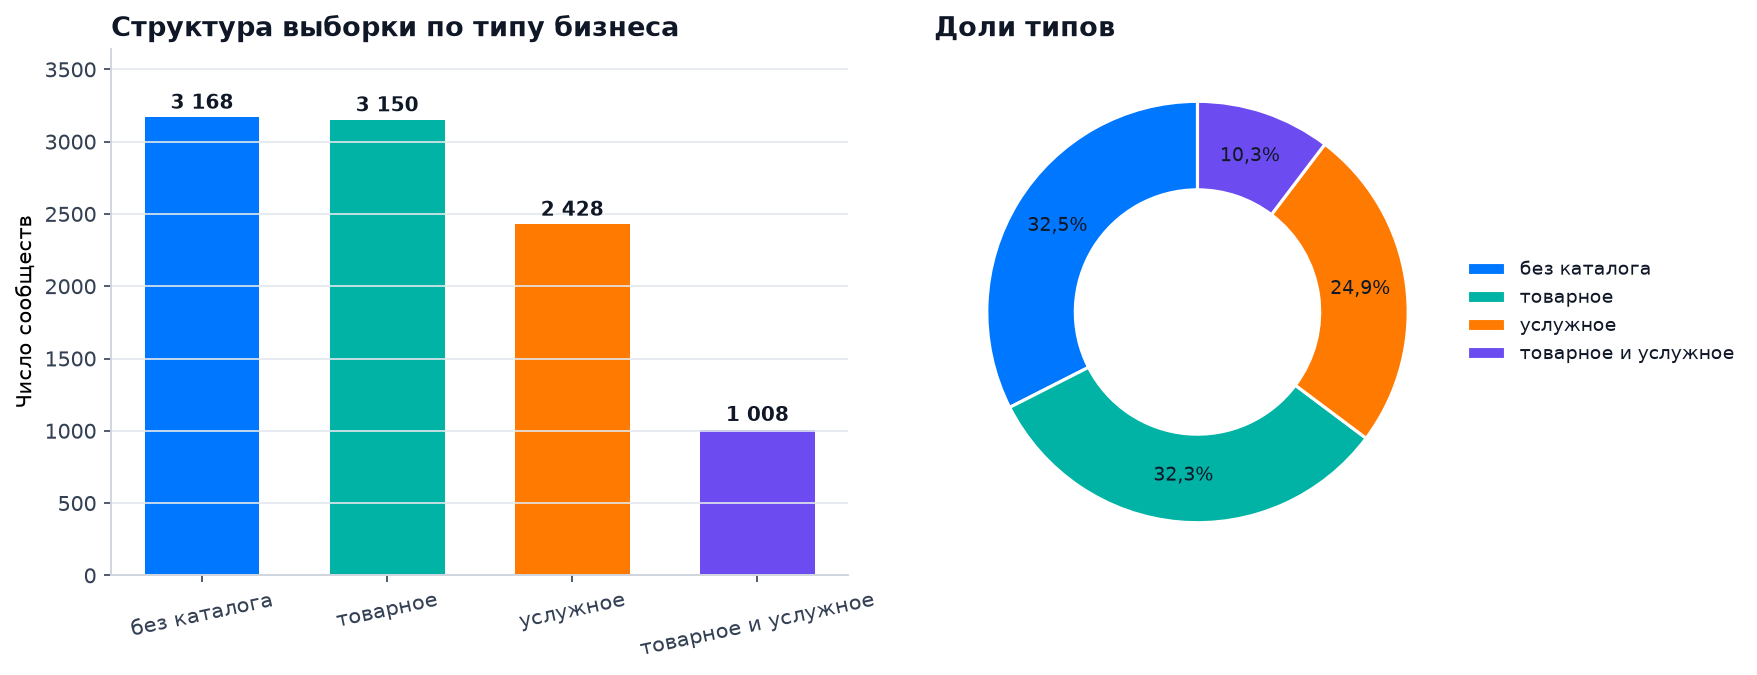

In [7]:
# --- Типы бизнеса: структура выборки ---------------------------------------
type_col = 'Тип бизнеса (товары / услуги)'
tc = biz[type_col].value_counts()
colors = [C_VK, C_TEAL, C_PT, C_ACC]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})
bars = axes[0].bar(tc.index, tc.values, color=colors, width=0.62)
axes[0].set_title('Структура выборки по типу бизнеса')
axes[0].set_ylabel('Число сообществ')
axes[0].tick_params(axis='x', rotation=12)
for b, v in zip(bars, tc.values):
    axes[0].text(b.get_x()+b.get_width()/2, v+60, f'{v:,}'.replace(',', ' '),
                 ha='center', fontsize=9.5, fontweight='bold')
axes[0].set_ylim(0, tc.max()*1.15)
axes[0].grid(axis='x', visible=False)

axes[1].pie(tc.values, labels=None, colors=colors, startangle=90,
            wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.5),
            autopct=lambda p: f'{p:.1f}%'.replace('.', ',') if p > 4 else '', pctdistance=0.78,
            textprops=dict(fontsize=9))
axes[1].legend(tc.index, loc='center left', bbox_to_anchor=(0.98, 0.5), fontsize=9)
axes[1].set_title('Доли типов')
plt.tight_layout()
plt.show()

**Легенда к структуре типов.** Слева — абсолютное число сообществ, справа — кольцевая диаграмма долей. Четыре типа: «без каталога» (3 168; 32,5%), «товарное» (3 150; 32,3%), «услужное» (2 428; 24,9%), «товарное и услужное» (1 008; 10,3%). Главное: **треть выборки вообще не имеет каталога**, то есть это потенциальные, а не действующие продавцы. Ещё треть — чистые товарные бизнесы, ядро торговли.

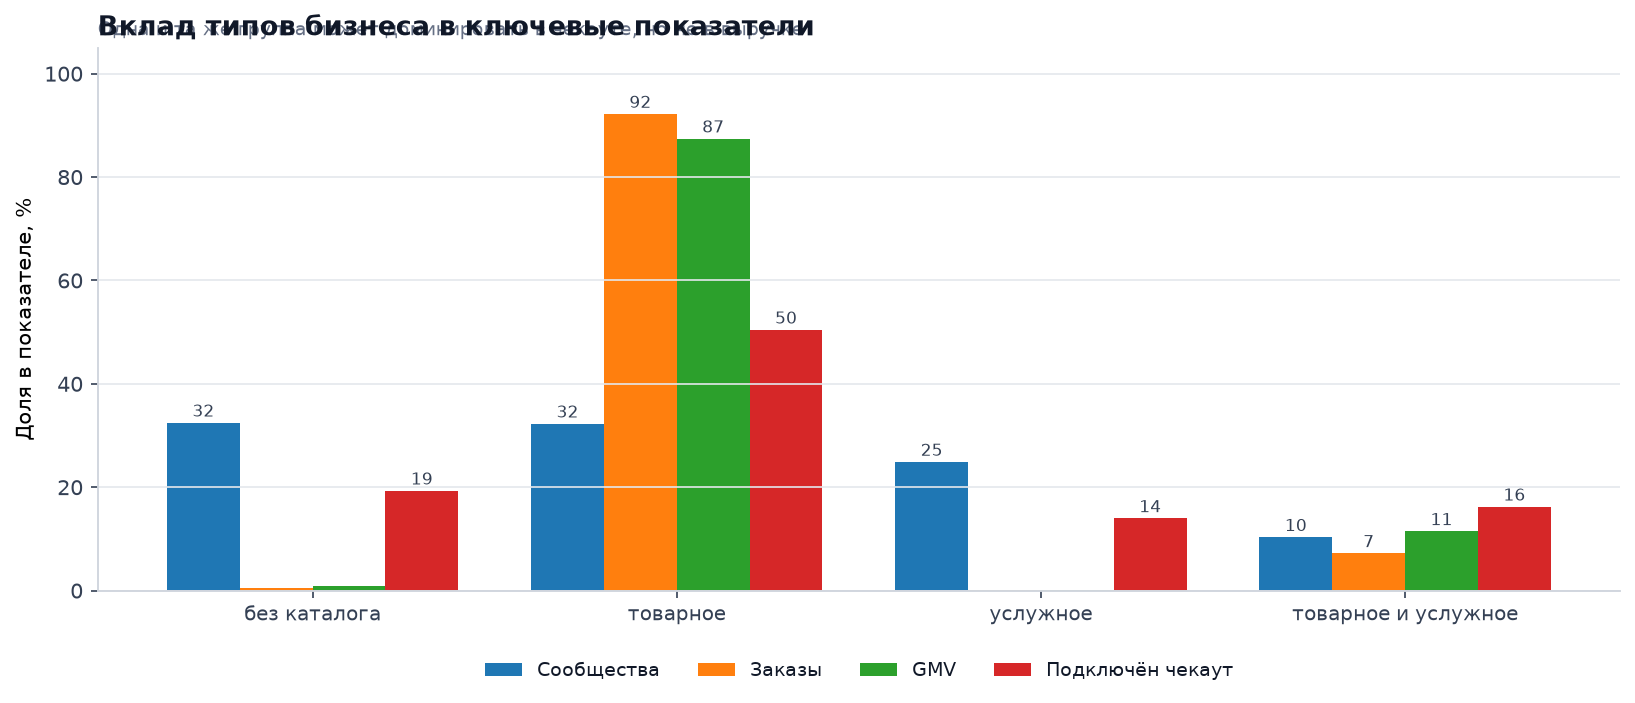

,Сообществ,Заказы,GMV_млн,Чекаут,Активные_товары
Тип бизнеса (товары / услуги),,,,,
без каталога,3168,16,0.09,1109,31
товарное,3150,3207,8.72,2895,354032
услужное,2428,4,0.01,802,0
товарное и услужное,1008,251,1.14,931,49184


In [8]:
# --- Вклад типов в заказы, GMV и подключение чекаута ------------------------
g = biz.groupby(type_col).agg(
    Сообществ=('ID бизнеса', 'size'),
    Заказы=('Заказы через чекаут', 'sum'),
    GMV=('GMV через чекаут, ₽', 'sum'),
    Чекаут=('Подключён чекаут', 'sum'),
    Активные_товары=('Число активных товаров в каталоге', 'sum'),
).reindex(tc.index)

share = pd.DataFrame({
    'Сообщества': g['Сообществ']/g['Сообществ'].sum()*100,
    'Заказы': g['Заказы']/g['Заказы'].sum()*100,
    'GMV': g['GMV']/g['GMV'].sum()*100,
    'Подключён чекаут': g['Чекаут']/g['Чекаут'].sum()*100,
})

fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(share))
w = 0.2
for i, col in enumerate(share.columns):
    bars = ax.bar(x + (i-1.5)*w, share[col], width=w, label=col)
    for b, v in zip(bars, share[col]):
        if v > 3:
            ax.text(b.get_x()+b.get_width()/2, v+1.2, f'{v:.0f}', ha='center', fontsize=8, color='#344054')
ax.set_xticks(x)
ax.set_xticklabels(share.index, fontsize=9.5)
ax.set_ylabel('Доля в показателе, %')
ax.set_title('Вклад типов бизнеса в ключевые показатели')
subtitle(ax, 'Одна и та же группа может доминировать в чекауте, но не в выручке')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.1), fontsize=9)
ax.set_ylim(0, 105)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

display(g.assign(GMV_млн=(g['GMV']/1e6).round(2))[['Сообществ','Заказы','GMV_млн','Чекаут','Активные_товары']])

**Легенда к вкладу типов.** Столбцы — четыре типа бизнеса, серии — их доля в общем числе сообществ, заказах, GMV и подключённом чекауте. Ключевое расхождение: «товарное» — это 32% сообществ, но **92% заказов и 87% GMV**, тогда как «без каталога» — 32% сообществ и лишь 0,5% заказов. «Услужное» почти не торгует через чекаут: 4 заказа на 2 428 сообществ. Вывод: наличие каталога — водораздел между «аудиторией» и «магазином». Чекаут при этом подключён у 1 109 сообществ без каталога — это «спящий» инструмент без товара.

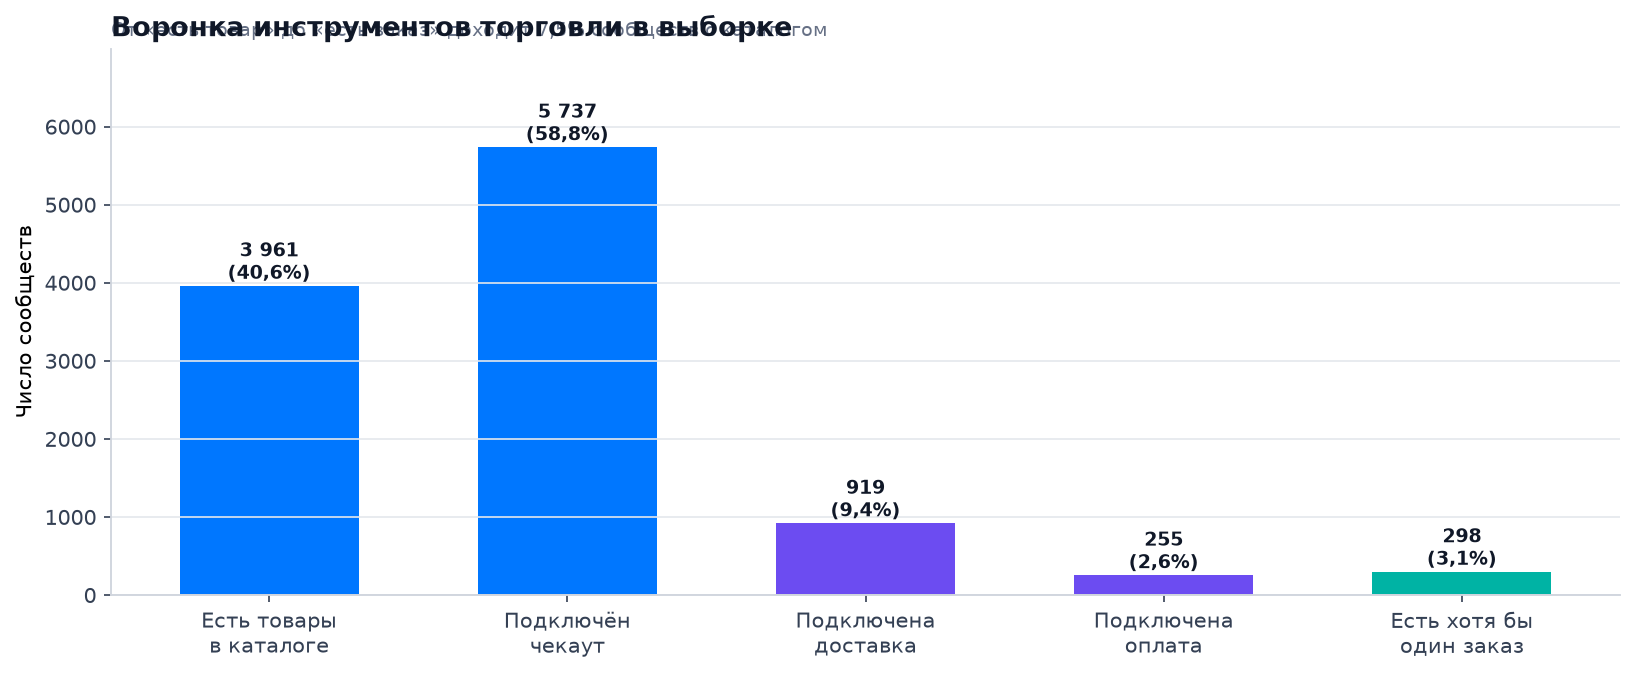

Загрузили товары: 4779 | с активными товарами: 3961 | чекаут: 5737 | доставка: 919 | оплата: 255
Конверсия каталог → заказ: 7,5% | чекаут → заказ: 5,2%


In [9]:
# --- Воронка инструментов торговли ------------------------------------------
active = int((biz['Число активных товаров в каталоге'] > 0).sum())
uploaded = int((biz['Товары загружены'] > 0).sum())
checkout = int((biz['Подключён чекаут'] == 1).sum())
delivery = int((biz['Подключена доставка'] == 1).sum())
payment = int((biz['Подключена оплата'] == 1).sum())
ordered = int((biz['Заказы через чекаут'] > 0).sum())

steps = ['Есть товары\nв каталоге', 'Подключён\nчекаут', 'Подключена\nдоставка', 'Подключена\nоплата', 'Есть хотя бы\nодин заказ']
vals = [active, checkout, delivery, payment, ordered]
cols = [C_VK, C_VK, C_ACC, C_ACC, C_TEAL]

fig, ax = plt.subplots(figsize=(11, 4.6))
bars = ax.bar(steps, vals, color=cols, width=0.6)
ax.set_ylabel('Число сообществ')
ax.set_title('Воронка инструментов торговли в выборке')
subtitle(ax, 'От «есть товар» до «есть заказ» доходит 7,5% сообществ с каталогом')
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+90, f'{v:,}\n({v/len(biz)*100:.1f}%)'.replace(',', ' ').replace('.', ','),
            ha='center', fontsize=9, fontweight='bold')
ax.set_ylim(0, max(vals)*1.22)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print('Загрузили товары:', uploaded, '| с активными товарами:', active,
      '| чекаут:', checkout, '| доставка:', delivery, '| оплата:', payment)
print('Конверсия каталог → заказ:',
      fpct(ordered/active*100), '| чекаут → заказ:', fpct(ordered/checkout*100))

**Легенда к воронке инструментов.** Высота столбца — число сообществ, подписи — абсолют и доля от всех 9 754. Логика воронки: товар → чекаут → доставка → оплата → заказ. Видно резкое сужение на каждом шаге: каталог с активными товарами есть у 3 961 (40,6%), чекаут — у 5 737 (58,8%, причём часть без товара), доставка — у 919 (9,4%), оплата — у 255 (2,6%), заказы — у 298 (3,1%). Только **7,5% сообществ с каталогом** дошли до заказа. Узкое место — не подключение чекаута, а наличие товара, трафика и спроса.

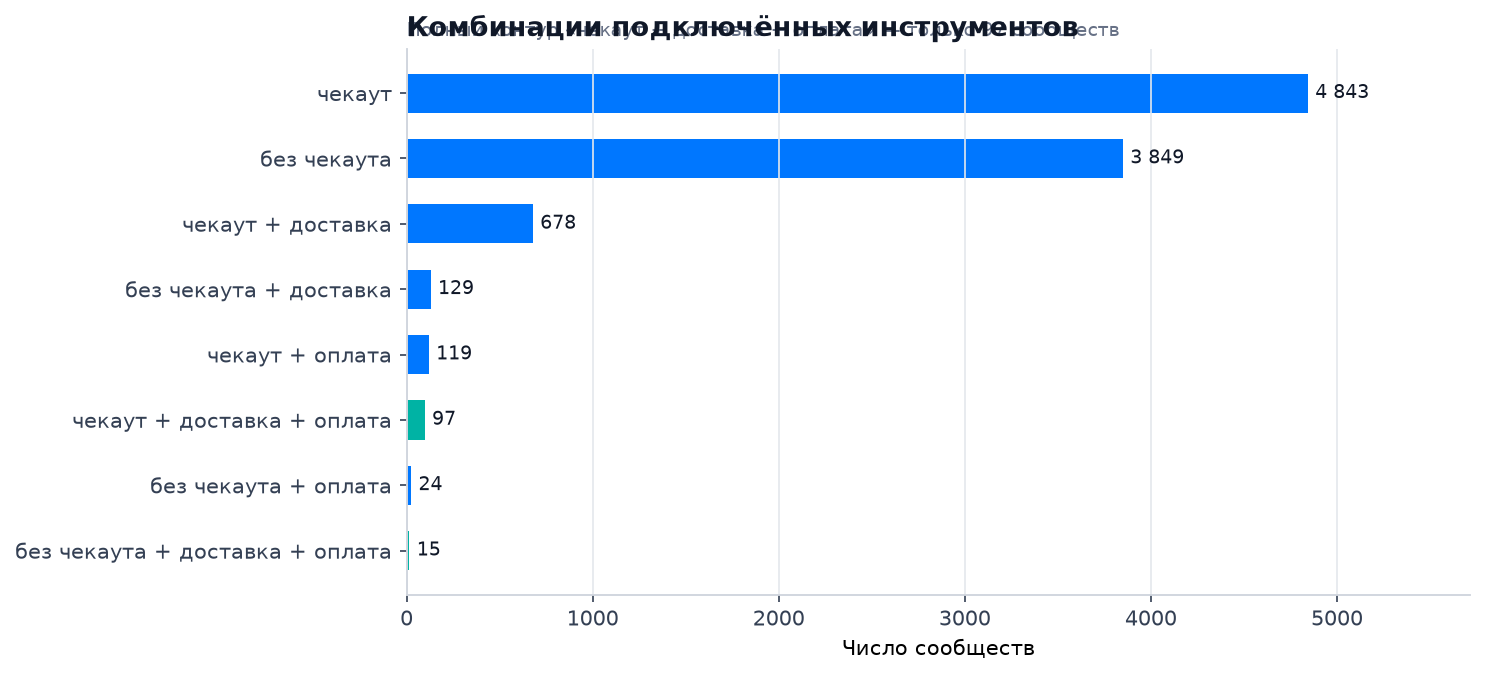

In [10]:
# --- Комбинации инструментов ------------------------------------------------
combo = (biz.groupby(['Подключён чекаут','Подключена доставка','Подключена оплата'])
            .size().reset_index(name='n'))
def combo_label(r):
    parts = []
    parts.append('чекаут' if r['Подключён чекаут'] else 'без чекаута')
    if r['Подключена доставка']: parts.append('доставка')
    if r['Подключена оплата']: parts.append('оплата')
    return ' + '.join(parts)
combo['Комбинация'] = combo.apply(combo_label, axis=1)
combo = combo.sort_values('n')

fig, ax = plt.subplots(figsize=(10, 4.6))
bars = ax.barh(combo['Комбинация'], combo['n'],
               color=[C_TEAL if 'чекаут' in c and 'доставка' in c and 'оплата' in c
                      else (C_VK if 'чекаут' in c else C_GRAY) for c in combo['Комбинация']], height=0.6)
ax.set_xlabel('Число сообществ')
ax.set_title('Комбинации подключённых инструментов')
subtitle(ax, 'Полный контур «чекаут + доставка + оплата» — только 97 сообществ')
for b, v in zip(bars, combo['n']):
    ax.text(v+40, b.get_y()+b.get_height()/2, f'{v:,}'.replace(',', ' '), va='center', fontsize=9)
ax.set_xlim(0, combo['n'].max()*1.18)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к комбинациям инструментов.** Каждая строка — уникальный набор подключённых опций, длина — число сообществ. Серые — без чекаута, синие — только чекаут, бирюзовый — полный контур. Читается так: 3 849 сообществ не подключили ничего, 4 843 — только чекаут без доставки и оплаты. Полный контур «чекаут + доставка + оплата» есть у **97 сообществ (1%)**. Значит, инфраструктура торговли в выборке фрагментарна: чаще всего продавец берёт на себя логистику и приём оплаты вне платформы.

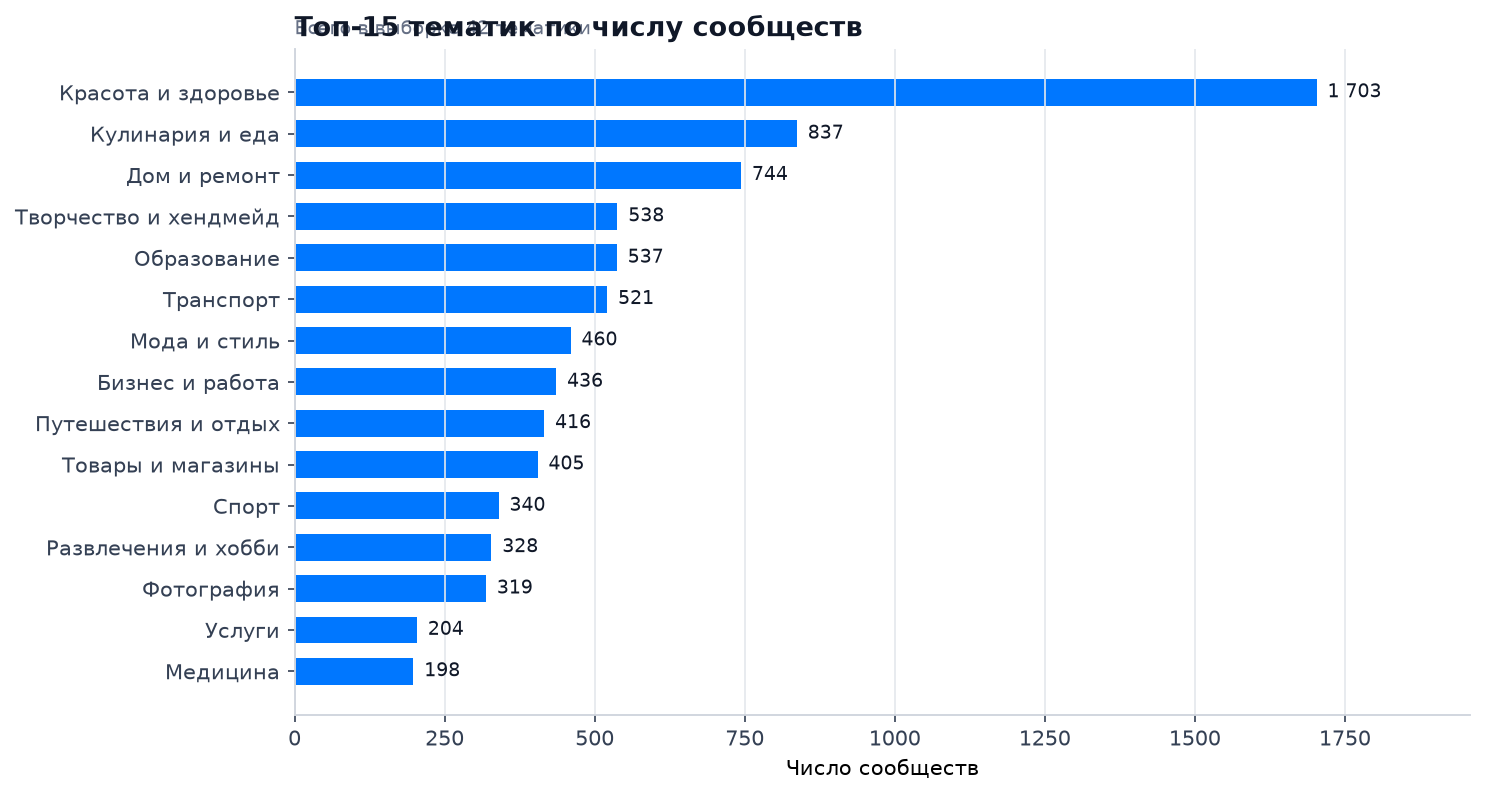

Доля топ-3 тематик: 33,7%
Доля топ-10 тематик: 67,6%


In [11]:
# --- Топ-15 тематик по числу сообществ --------------------------------------
th = biz['Тематика'].value_counts().head(15).sort_values()

fig, ax = plt.subplots(figsize=(10, 5.4))
bars = ax.barh(th.index, th.values, color=C_VK, height=0.65)
ax.set_xlabel('Число сообществ')
ax.set_title('Топ-15 тематик по числу сообществ')
subtitle(ax, 'Всего в выборке 42 тематики')
for b, v in zip(bars, th.values):
    ax.text(v+18, b.get_y()+b.get_height()/2, f'{v:,}'.replace(',', ' '), va='center', fontsize=9)
ax.set_xlim(0, th.max()*1.15)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Доля топ-3 тематик:', fpct(th.tail(3).sum()/len(biz)*100))
print('Доля топ-10 тематик:', fpct(biz['Тематика'].value_counts().head(10).sum()/len(biz)*100))

**Легенда к тематикам.** Горизонтальные столбцы упорядочены по убыванию; подписи — число сообществ. Лидируют «Красота и здоровье» (1 703; 17,5%), «Кулинария и еда» (837; 8,6%) и «Дом и ремонт» (744; 7,6%). Топ-3 дают 33,7% выборки, топ-10 — 67,6%. Это типичный профиль малого бизнеса в соцсети: услуги красоты, еда, домашние товары и хендмейд. Промышленного или крупного ритейла в выборке почти нет.

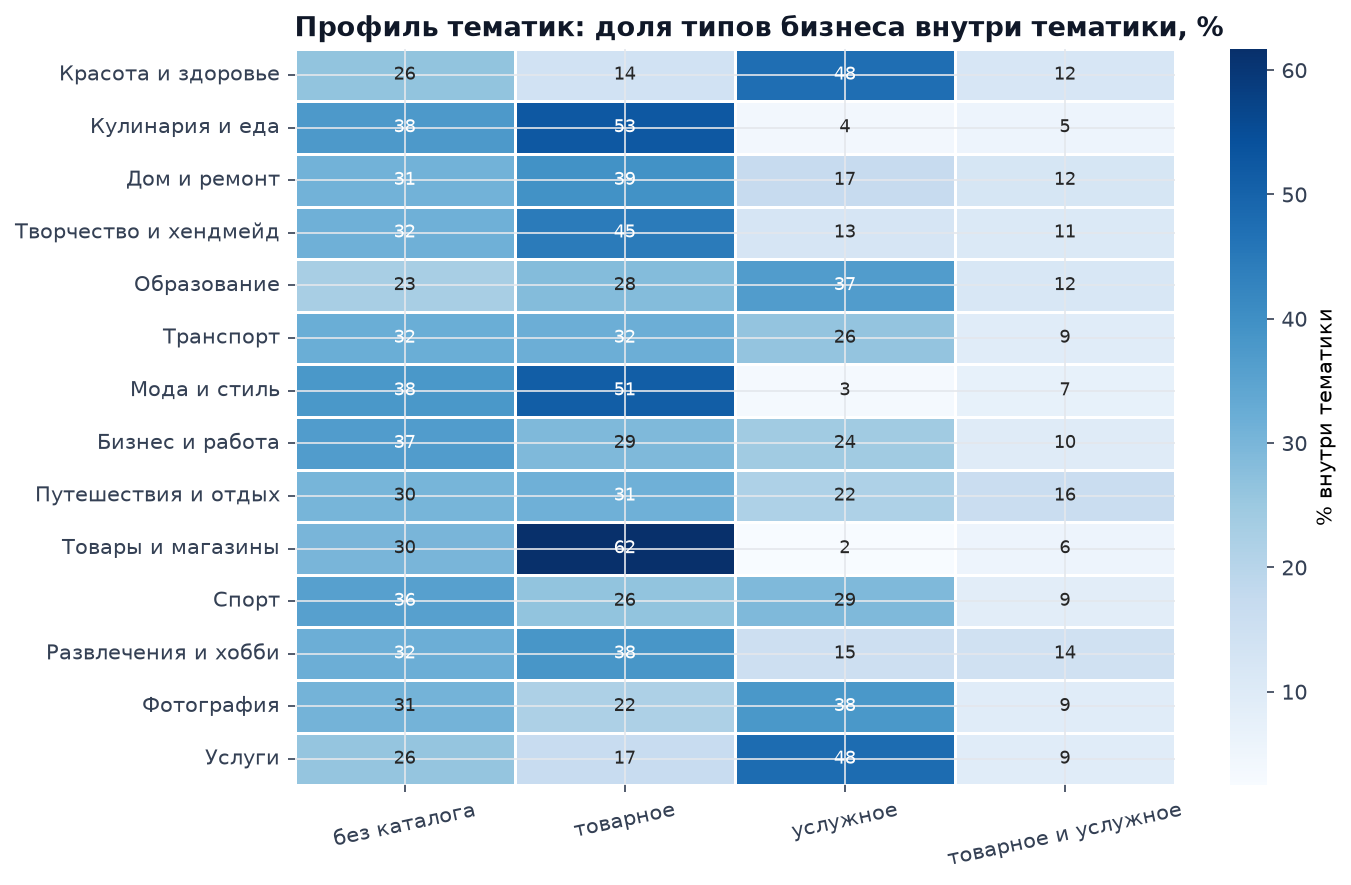

In [12]:
# --- Тематика × тип бизнеса --------------------------------------------------
top_th = biz['Тематика'].value_counts().head(14).index.tolist()
ct = pd.crosstab(biz['Тематика'], biz[type_col], normalize='index').loc[top_th] * 100
ct = ct[['без каталога', 'товарное', 'услужное', 'товарное и услужное']]

fig, ax = plt.subplots(figsize=(9.5, 6))
sns.heatmap(ct, annot=True, fmt='.0f', cmap='Blues', cbar_kws={'label': '% внутри тематики'},
            linewidths=1.2, linecolor='white', ax=ax, annot_kws={'fontsize': 8.5})
ax.set_title('Профиль тематик: доля типов бизнеса внутри тематики, %')
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=12)
plt.tight_layout()
plt.show()

**Легенда к теплокарте «тематика × тип».** Строка — тематика, столбец — тип бизнеса, цвет и число — доля типа внутри данной тематики (сумма по строке = 100%). Читать построчно. «Кулинария и еда» — 53% товарные, «Мода и стиль» — 51% товарные, «Красота и здоровье» — 48% услугные, «Образование» — 37% услугные. Тематика предсказывает модель монетизации: товарные ниши идут в каталог и чекаут, услужные — в запись и оплату вне платформы. Это объясняет, почему при большой доле услуг в выборке так мало заказов через чекаут.

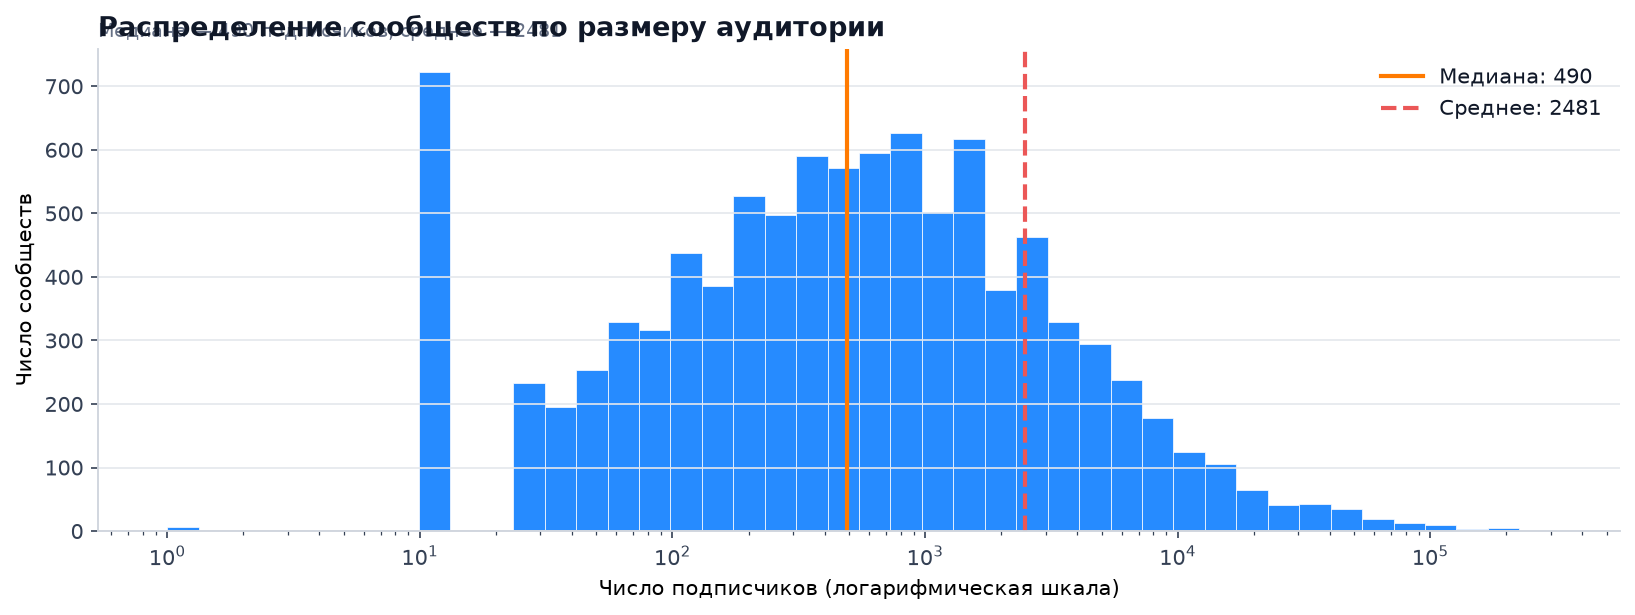

count      9754.0
mean       2482.0
std        9247.0
min           0.0
50%         490.0
90%        4900.0
99%       36000.0
max      300000.0


In [13]:
# --- Распределение подписчиков ----------------------------------------------
subs = biz['Число подписчиков'].clip(lower=1)
bins = np.logspace(0, np.log10(max(subs.max(), 10)), 45)

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.hist(subs, bins=bins, color=C_VK, alpha=0.85, edgecolor='white', linewidth=0.4)
ax.set_xscale('log')
ax.set_xlabel('Число подписчиков (логарифмическая шкала)')
ax.set_ylabel('Число сообществ')
ax.set_title('Распределение сообществ по размеру аудитории')
subtitle(ax, f'Медиана — {int(biz["Число подписчиков"].median())} подписчиков, среднее — {int(biz["Число подписчиков"].mean())}')
ax.axvline(biz['Число подписчиков'].median(), color=C_PT, lw=2, label=f'Медиана: {int(biz["Число подписчиков"].median())}')
ax.axvline(biz['Число подписчиков'].mean(), color=C_RED, lw=2, ls='--', label=f'Среднее: {int(biz["Число подписчиков"].mean())}')
ax.legend(loc='upper right')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print(biz['Число подписчиков'].describe(percentiles=[.5,.9,.99]).round(0).to_string())

**Легенда к распределению подписчиков.** По оси X — размер аудитории в логарифмическом масштабе, по Y — число сообществ. Распределение сильно правостороннее: медиана 490 подписчиков, среднее около 2 400, максимум 300 000. Красная пунктирная линия (среднее) правее медианы — признак выбросов. Основная масса — микросообщества до 5 тыс. подписчиков. Практический вывод: Маркет ВКонтакте в этой выборке — инструмент для малого бизнеса, а не для крупных брендов; решения должны быть mass-market, а не enterprise.

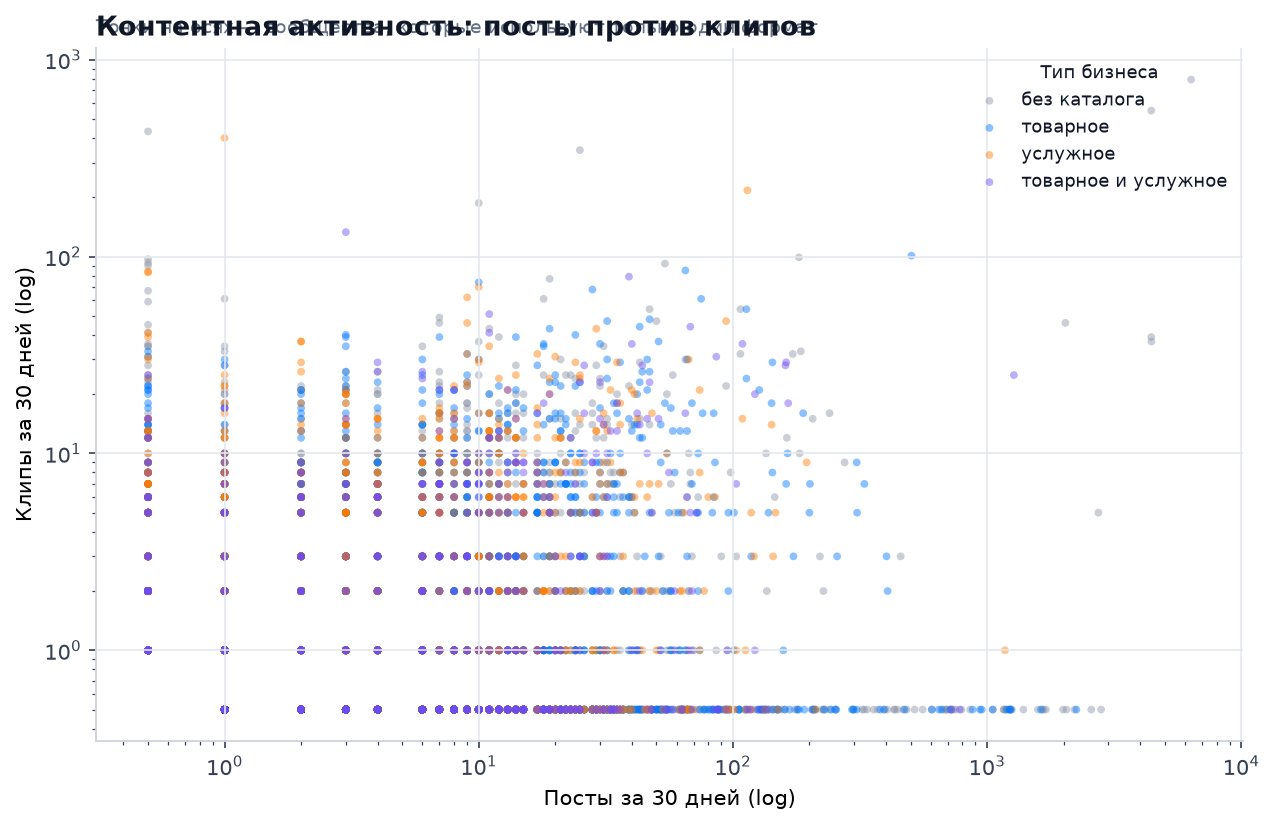

Медиана постов: 2.0 | медиана клипов: 0.0
Не публиковали ничего: 2373 (24.3%)


In [14]:
# --- Посты vs клипы ----------------------------------------------------------
sc = biz[(biz['Посты за 30 дней'] > 0) | (biz['Клипы за 30 дней'] > 0)].copy()

fig, ax = plt.subplots(figsize=(8.6, 5.6))
for t, c in zip(['без каталога', 'товарное', 'услужное', 'товарное и услужное'],
                [C_GRAY, C_VK, C_PT, C_ACC]):
    d = sc[sc[type_col] == t]
    ax.scatter(d['Посты за 30 дней'].clip(lower=0.5), d['Клипы за 30 дней'].clip(lower=0.5),
               s=14, alpha=0.45, color=c, label=t, edgecolors='none')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Посты за 30 дней (log)')
ax.set_ylabel('Клипы за 30 дней (log)')
ax.set_title('Контентная активность: посты против клипов')
subtitle(ax, 'Точки на осях — сообщества, которые используют только один формат')
ax.legend(title='Тип бизнеса', fontsize=8.5, title_fontsize=8.5, loc='upper right')
plt.tight_layout()
plt.show()

print('Медиана постов:', biz['Посты за 30 дней'].median(), '| медиана клипов:', biz['Клипы за 30 дней'].median())
print('Не публиковали ничего:', int(((biz['Посты за 30 дней']==0)&(biz['Клипы за 30 дней']==0)).sum()),
      f'({((biz["Посты за 30 дней"]==0)&(biz["Клипы за 30 дней"]==0)).mean()*100:.1f}%)')

**Легенда к scatter «посты против клипов».** Каждая точка — сообщество. Обе оси логарифмические, потому что активность различается в сотни раз. Точки на нижней оси — только посты, на левой — только клипы. Видно, что посты распространены шире: медиана 2 поста против 0 клипов за месяц. Четверть сообществ (2 373; 24,3%) не публикует ничего. Клипы концентрируются у активных товарных сообществ — это более трудоёмкий формат. Вывод: клипы — не массовая практика, а инструмент продвинутой части выборки.

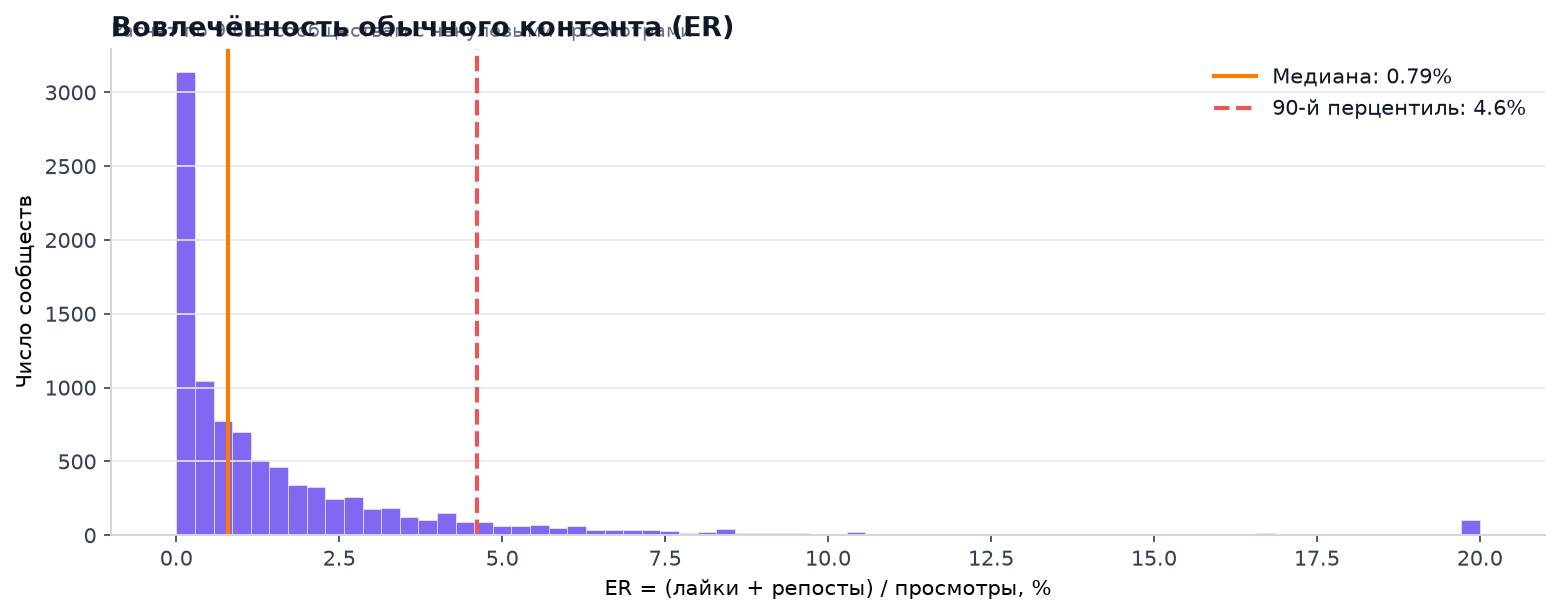

count    9613.00
mean        2.83
std        57.16
min         0.00
25%         0.13
50%         0.79
75%         2.18
90%         4.61
99%        20.83
max      5442.61


In [15]:
# --- Вовлечённость обычного контента ----------------------------------------
er = ((biz['Лайки обычного контента'] + biz['Репосты обычного контента']) /
      biz['Просмотры обычного контента'].replace(0, np.nan)) * 100
er = er.dropna()

fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.hist(er.clip(0, 20), bins=70, color=C_ACC, alpha=0.85, edgecolor='white', linewidth=0.3)
ax.axvline(er.median(), color=C_PT, lw=2, label=f'Медиана: {er.median():.2f}%')
ax.axvline(er.quantile(0.9), color=C_RED, lw=2, ls='--', label=f'90-й перцентиль: {er.quantile(0.9):.1f}%')
ax.set_xlabel('ER = (лайки + репосты) / просмотры, %')
ax.set_ylabel('Число сообществ')
ax.set_title('Вовлечённость обычного контента (ER)')
subtitle(ax, f'Расчёт по {len(er):,} сообществам с ненулевыми просмотрами'.replace(',', ' '))
ax.legend()
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print(er.describe(percentiles=[.25,.5,.75,.9,.99]).round(2).to_string())

**Легенда к ER.** По оси X — вовлечённость в процентах (лайки и репосты к просмотрам), по Y — число сообществ; значения выше 20% отсечены, чтобы не растягивать шкалу. Медиана — около 0,8%, 90-й перцентиль — 4,6%. То есть у типичного сообщества лайкает меньше одного человека из ста. Это нормальная картина для товарного контента: он выполняет функцию витрины, а не развлечения. Сравнивать ER между тематиками нужно осторожно — у развлекательного контента он структурно выше.

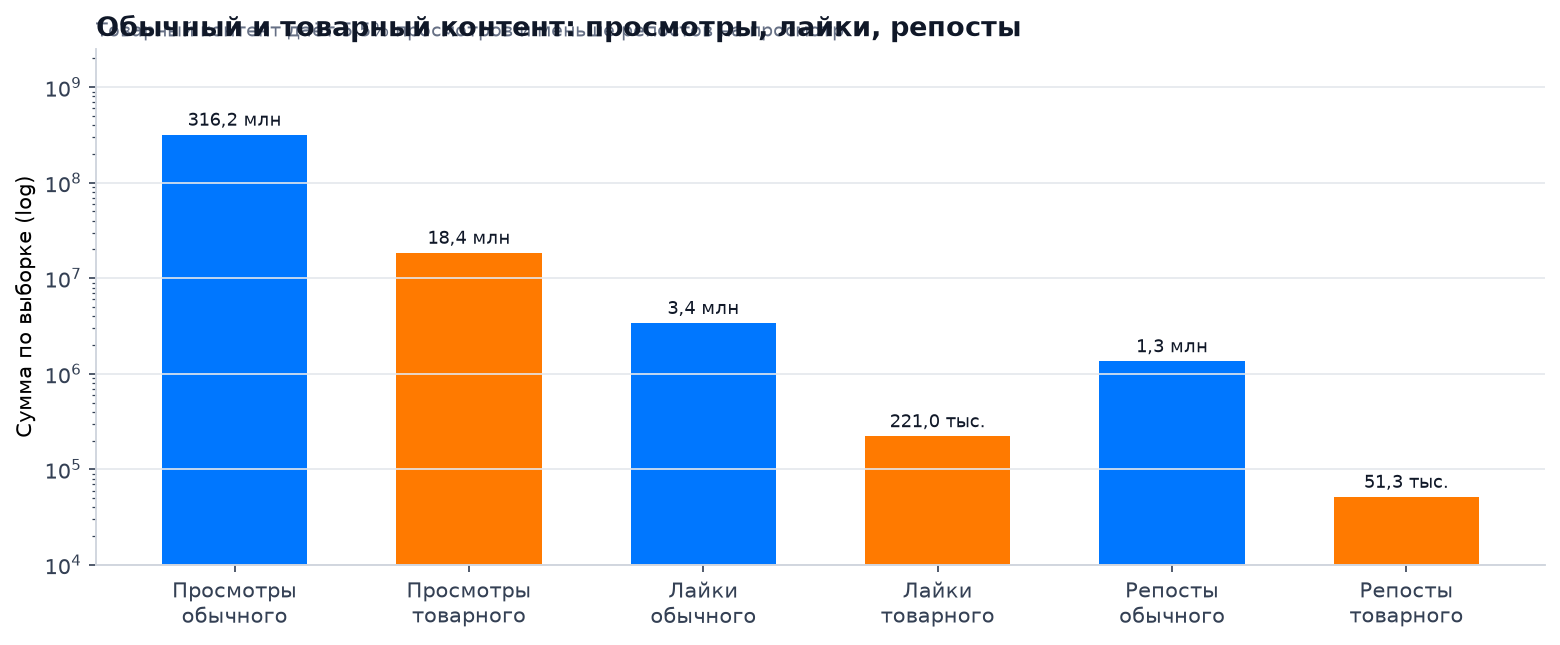

Доля товарного контента в просмотрах: 5,5%
Репостов на 1000 просмотров — обычный: 4.3 | товарный: 2.8


In [16]:
# --- Обычный и товарный контент --------------------------------------------
summary_content = pd.Series({
    'Просмотры\nобычного': biz['Просмотры обычного контента'].sum(),
    'Просмотры\nтоварного': biz['Просмотры товарного контента'].sum(),
    'Лайки\nобычного': biz['Лайки обычного контента'].sum(),
    'Лайки\nтоварного': biz['Лайки товарного контента'].sum(),
    'Репосты\nобычного': biz['Репосты обычного контента'].sum(),
    'Репосты\nтоварного': biz['Репосты товарного контента'].sum(),
})

fig, ax = plt.subplots(figsize=(10.5, 4.4))
colors = [C_VK, C_PT] * 3
bars = ax.bar(summary_content.index, summary_content.values, color=colors, width=0.62)
ax.set_yscale('log')
ax.set_ylabel('Сумма по выборке (log)')
ax.set_title('Обычный и товарный контент: просмотры, лайки, репосты')
subtitle(ax, 'Товарный контент даёт 5,5% просмотров и меньше репостов на просмотр')
for b, v in zip(bars, summary_content.values):
    ax.text(b.get_x()+b.get_width()/2, v*1.25, fnum(v, 1), ha='center', fontsize=8.5)
ax.set_ylim(1e4, summary_content.max()*8)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print('Доля товарного контента в просмотрах:',
      fpct(biz['Просмотры товарного контента'].sum()/(biz['Просмотры обычного контента'].sum()+biz['Просмотры товарного контента'].sum())*100))
print('Репостов на 1000 просмотров — обычный:',
      round(biz['Репосты обычного контента'].sum()/biz['Просмотры обычного контента'].sum()*1000, 1),
      '| товарный:', round(biz['Репосты товарного контента'].sum()/biz['Просмотры товарного контента'].sum()*1000, 1))

**Легенда к обычному и товарному контенту.** Шесть столбцов: три метрики для обычного контента (синие) и три для товарного (оранжевые). Шкала логарифмическая из-за разницы в порядки. Товарный контент собирает 18,4 млн просмотров против 316,2 млн у обычного — всего **5,5%**. При этом на 1 000 просмотров товарного контента приходится 2,8 репоста против 4,3 у обычного, то есть в 1,5 раза меньше: товарный контент не вируснее обычного, он просто уже встроен в воронку и ведёт в карточку.

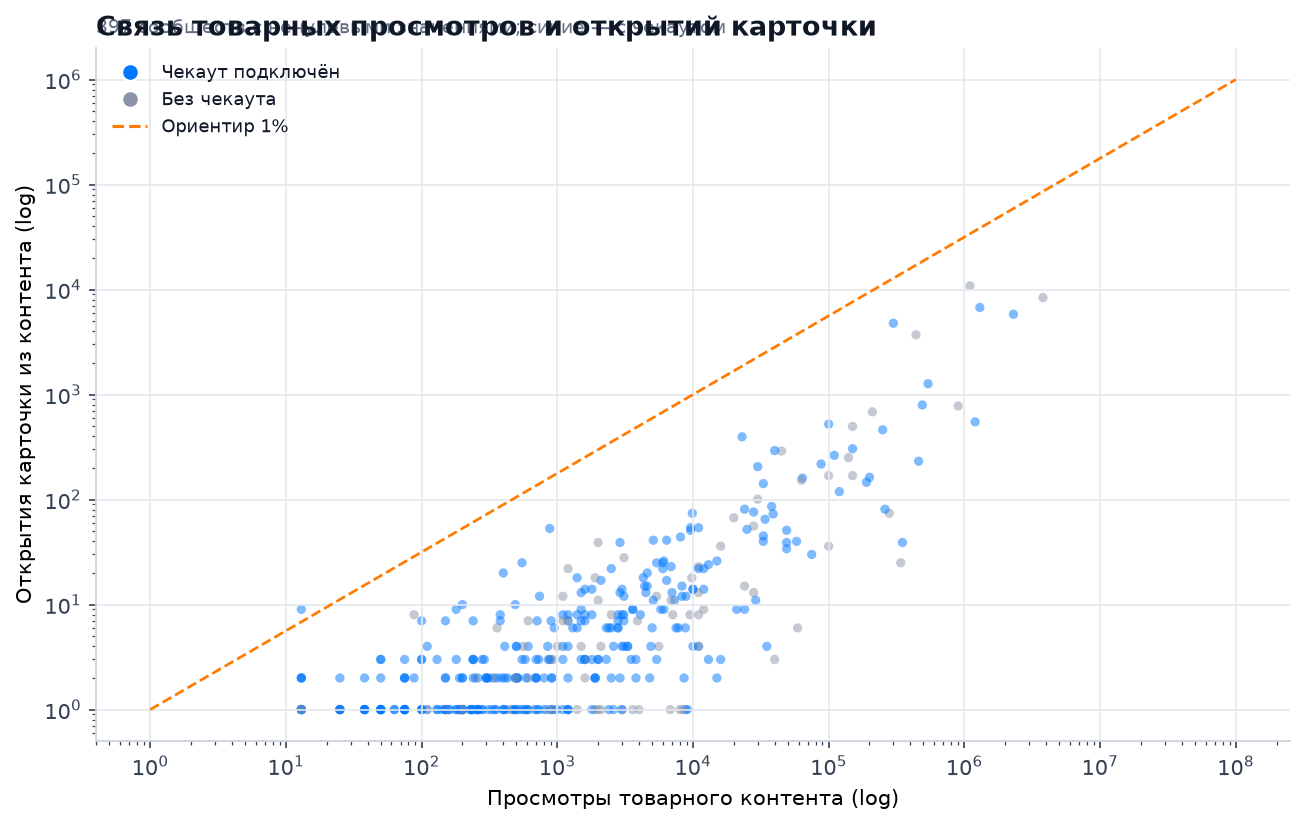

Медианная конверсия просмотр→открытие: 0,4%


In [17]:
# --- Товарные просмотры → открытия карточки ---------------------------------
d = biz[(biz['Просмотры товарного контента'] > 0) & (biz['Открытия карточки товара из контента'] > 0)].copy()

fig, ax = plt.subplots(figsize=(8.8, 5.6))
colors = np.where(d['Подключён чекаут'] == 1, C_VK, C_GRAY)
ax.scatter(d['Просмотры товарного контента'], d['Открытия карточки товара из контента'],
           s=20, alpha=0.5, c=colors, edgecolors='none')
lims = [max(d['Просмотры товарного контента'].min(), 1), d['Просмотры товарного контента'].max()]
ax.plot([1, 1e8], [1, 1e6], color=C_PT, ls='--', lw=1.3, label='Ориентир: 1% просмотров → открытие')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Просмотры товарного контента (log)')
ax.set_ylabel('Открытия карточки из контента (log)')
ax.set_title('Связь товарных просмотров и открытий карточки')
subtitle(ax, f'{len(d):,} сообществ с ненулевыми значениями; синие — с чекаутом'.replace(',', ' '))
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0],[0], marker='o', color='w', markerfacecolor=C_VK, markersize=8, label='Чекаут подключён'),
                   Line2D([0],[0], marker='o', color='w', markerfacecolor=C_GRAY, markersize=8, label='Без чекаута'),
                   Line2D([0],[0], color=C_PT, ls='--', label='Ориентир 1%')], fontsize=8.5)
plt.tight_layout()
plt.show()

print('Медианная конверсия просмотр→открытие:',
      fpct((d['Открытия карточки товара из контента']/d['Просмотры товарного контента']).median()*100))

**Легенда к связи «просмотры → открытия».** Оси логарифмические, точка — сообщество; синие подключили чекаут, серые нет; пунктир — ориентир «1% просмотров переходит в открытие карточки». Облако вытянуто вдоль диагонали: чем больше просмотров товарного контента, тем больше открытий, но разброс огромен — при одинаковых просмотрах открытия различаются в десятки раз. Медианная конверсия — около 0,4%. Это значит, что **просмотр сам по себе не продаёт**: решают креатив, цена и понятность карточки.

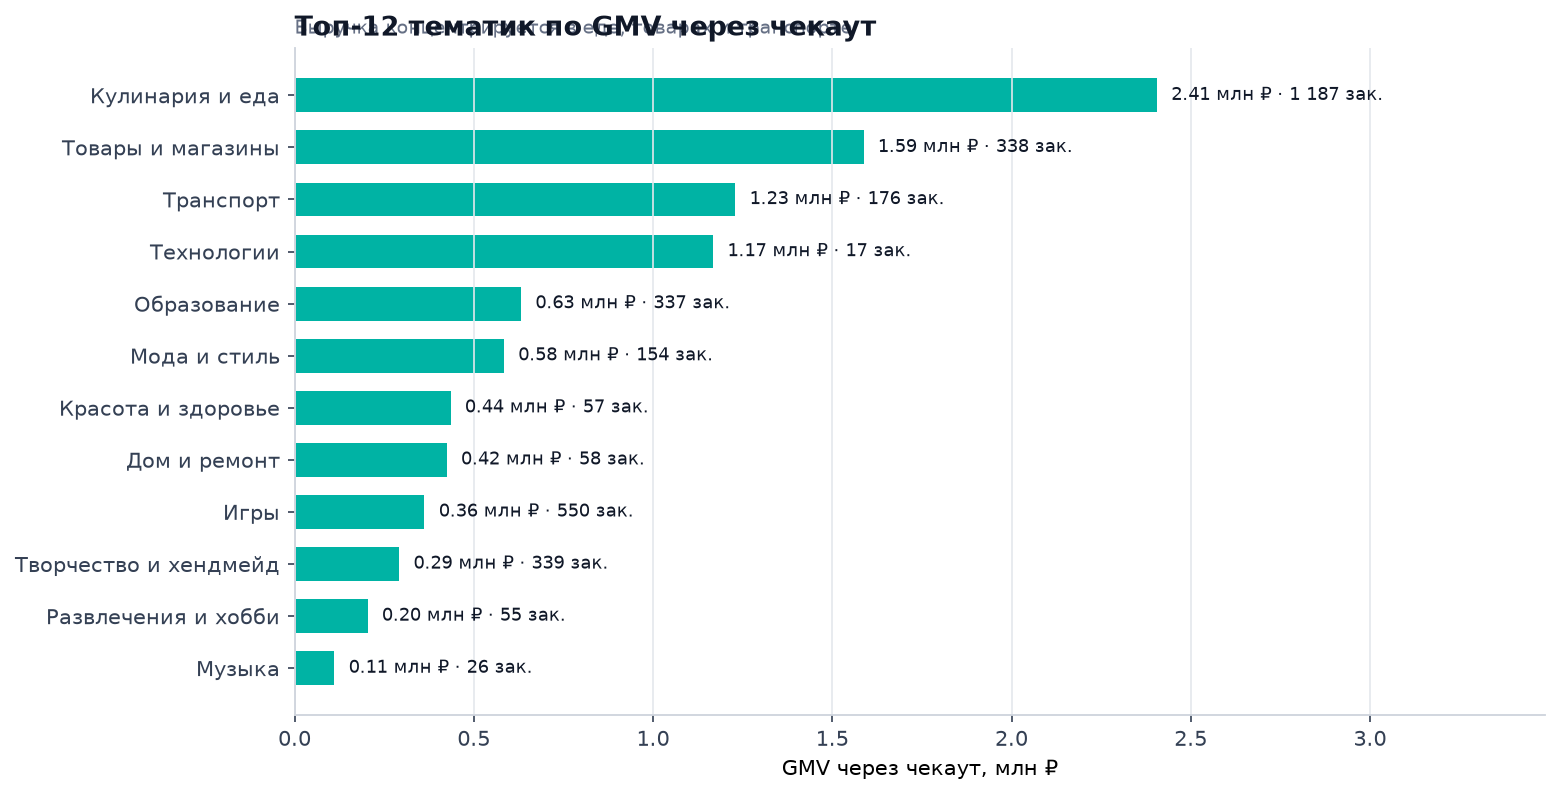

Топ-3 тематики по GMV: Кулинария и еда, Товары и магазины, Транспорт
Их доля в GMV выборки: 52,4%


In [18]:
# --- Топ-10 тематик по GMV ---------------------------------------------------
gth = (biz.groupby('Тематика')
          .agg(GMV=('GMV через чекаут, ₽','sum'), Заказы=('Заказы через чекаут','sum'),
               Сообществ=('ID бизнеса','size'))
          .sort_values('GMV', ascending=False).head(12).sort_values('GMV'))

fig, ax = plt.subplots(figsize=(10.5, 5.4))
bars = ax.barh(gth.index, gth['GMV']/1e6, color=C_TEAL, height=0.65)
ax.set_xlabel('GMV через чекаут, млн ₽')
ax.set_title('Топ-12 тематик по GMV через чекаут')
subtitle(ax, 'Выручка концентрируется в еде, товарах и транспорте')
for b, v, o in zip(bars, gth['GMV']/1e6, gth['Заказы']):
    ax.text(v+0.04, b.get_y()+b.get_height()/2, f'{v:.2f} млн ₽ · {o:,} зак.'.replace(',', ' '),
            va='center', fontsize=8.5)
ax.set_xlim(0, (gth['GMV']/1e6).max()*1.45)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Топ-3 тематики по GMV:', ', '.join(gth.tail(3).index[::-1]))
print('Их доля в GMV выборки:', fpct(gth.tail(3)['GMV'].sum()/biz['GMV через чекаут, ₽'].sum()*100))

**Легенда к GMV по тематикам.** Длина столбца — суммарный GMV через чекаут в млн ₽, подпись — GMV и число заказов. Лидеры: «Кулинария и еда» (2,41 млн ₽; 1 187 заказов), «Товары и магазины» (1,59 млн ₽; 338), «Транспорт» (1,23 млн ₽; 176). Обратите внимание на «Технологии»: 1,17 млн ₽ всего на 17 заказов — высокий чек. Топ-3 дают 52,4% GMV выборки. Сравнение с топом по числу сообществ («Красота и здоровье» — 1 703 сообщества, но лишь 0,44 млн ₽) показывает разрыв между размером аудитории и выручкой.

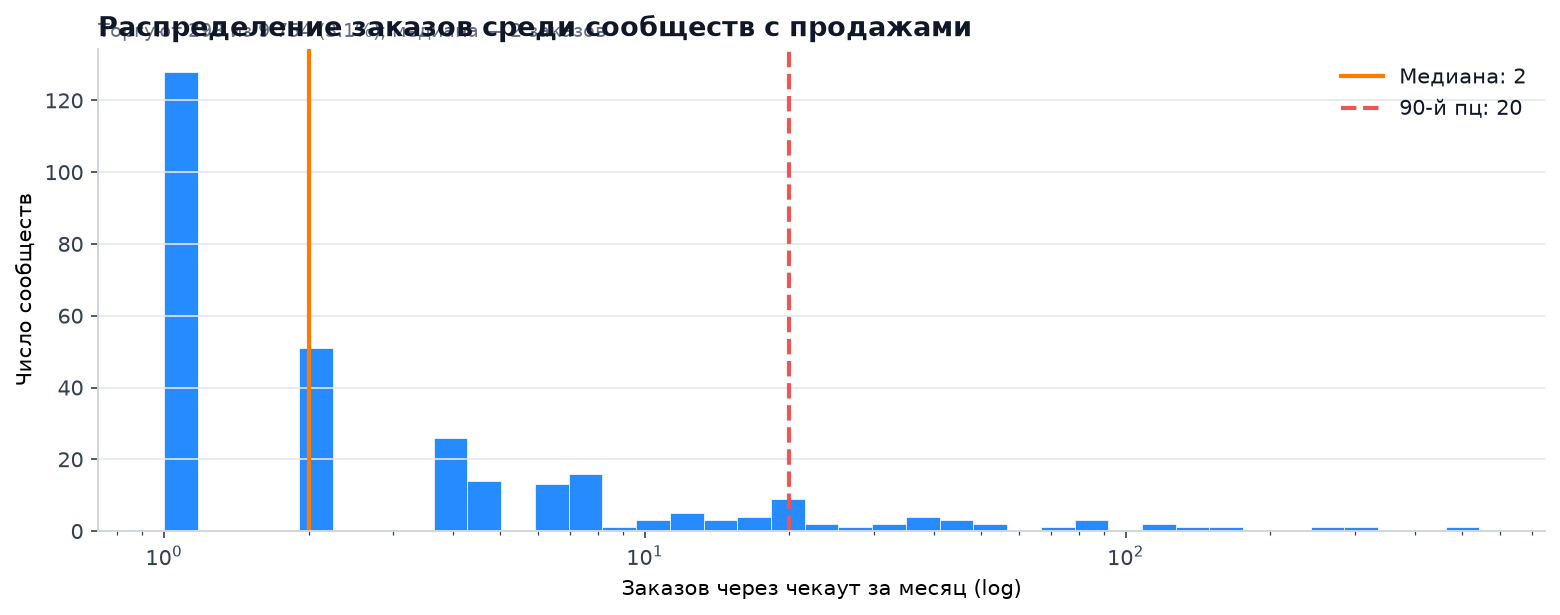

Всего заказов в выборке: 3478
Доля топ-1% торгующих в заказах: 24,4%


In [19]:
# --- Распределение заказов среди торгующих ----------------------------------
o = biz.loc[biz['Заказы через чекаут'] > 0, 'Заказы через чекаут']

fig, ax = plt.subplots(figsize=(10.5, 4.2))
bins = np.logspace(0, np.log10(o.max()+1), 40)
ax.hist(o, bins=bins, color=C_VK, alpha=0.85, edgecolor='white', linewidth=0.4)
ax.set_xscale('log')
ax.set_xlabel('Заказов через чекаут за месяц (log)')
ax.set_ylabel('Число сообществ')
ax.set_title('Распределение заказов среди сообществ с продажами')
subtitle(ax, f'Торгуют {len(o):,} из 9 754 ({len(o)/len(biz)*100:.1f}%); медиана — {int(o.median())} заказов'.replace(',', ' '))
ax.axvline(o.median(), color=C_PT, lw=2, label=f'Медиана: {int(o.median())}')
ax.axvline(o.quantile(0.9), color=C_RED, lw=2, ls='--', label=f'90-й пц: {int(o.quantile(0.9))}')
ax.legend()
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print('Всего заказов в выборке:', int(biz['Заказы через чекаут'].sum()))
print('Доля топ-1% торгующих в заказах:',
      fpct(o.nlargest(max(1,int(len(o)*0.01))).sum()/o.sum()*100))

**Легенда к распределению заказов.** Ось X — заказы за месяц в лог-масштабе, ось Y — число сообществ; включены только 298 сообществ с ненулевыми заказами. Распределение крайне неравномерно: медиана — 2 заказа, 90-й перцентиль — 20, максимум — 543. Топ-1% торгующих забирает 24,4% заказов. Это значит, что даже внутри «торгующих» есть выраженное ядро, а большинство делает единичные продажи. Стратегия роста должна опираться на активацию «длинного хвоста», а не только на крупнейших.

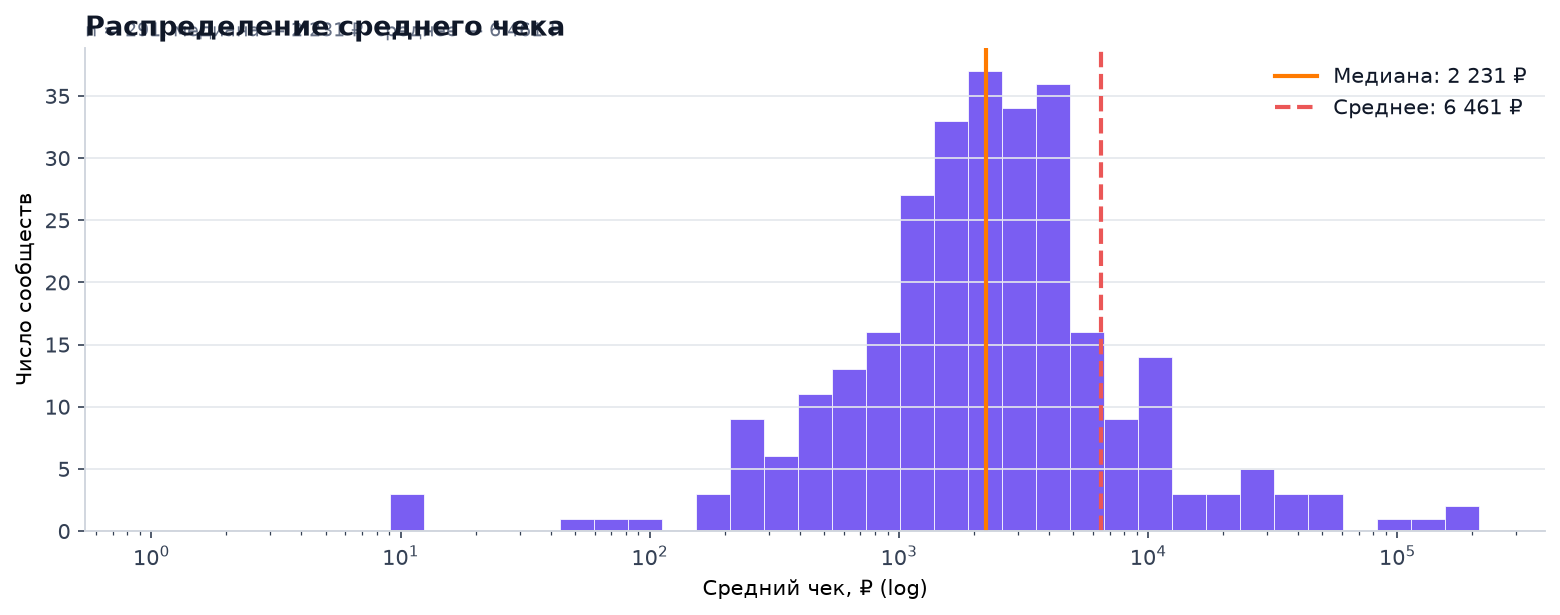

In [20]:
# --- Средний чек -------------------------------------------------------------
chk = biz.loc[biz['Средний чек, ₽'].notna(), 'Средний чек, ₽']

fig, ax = plt.subplots(figsize=(10.5, 4.2))
bins = np.logspace(0, np.log10(chk.max()+1), 40)
ax.hist(chk, bins=bins, color=C_ACC, alpha=0.9, edgecolor='white', linewidth=0.4)
ax.set_xscale('log')
ax.set_xlabel('Средний чек, ₽ (log)')
ax.set_ylabel('Число сообществ')
ax.set_title('Распределение среднего чека')
subtitle(ax, f'n = {len(chk):,}; медиана — {int(chk.median()):,} ₽, среднее — {int(chk.mean()):,} ₽'.replace(',', ' '))
ax.axvline(chk.median(), color=C_PT, lw=2, label=f'Медиана: {int(chk.median()):,} ₽'.replace(',', ' '))
ax.axvline(chk.mean(), color=C_RED, lw=2, ls='--', label=f'Среднее: {int(chk.mean()):,} ₽'.replace(',', ' '))
ax.legend()
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

**Легенда к среднему чеку.** Гистограмма по 291 сообществу, у которого есть и заказы, и заполненный чек; шкала X логарифмическая. Медиана — около 2 200 ₽, среднее — около 6 500 ₽: распределение сдвинуто вправо единичными крупными чеками (максимум — 211,8 тыс. ₽). Для сравнения: средний чек всего Маркета в «Итогах» — 3 781 ₽, Партнёра — 1 039 ₽. Выборка сообществ ближе к модели Маркета: небольшие продавцы с относительно дорогим товаром.

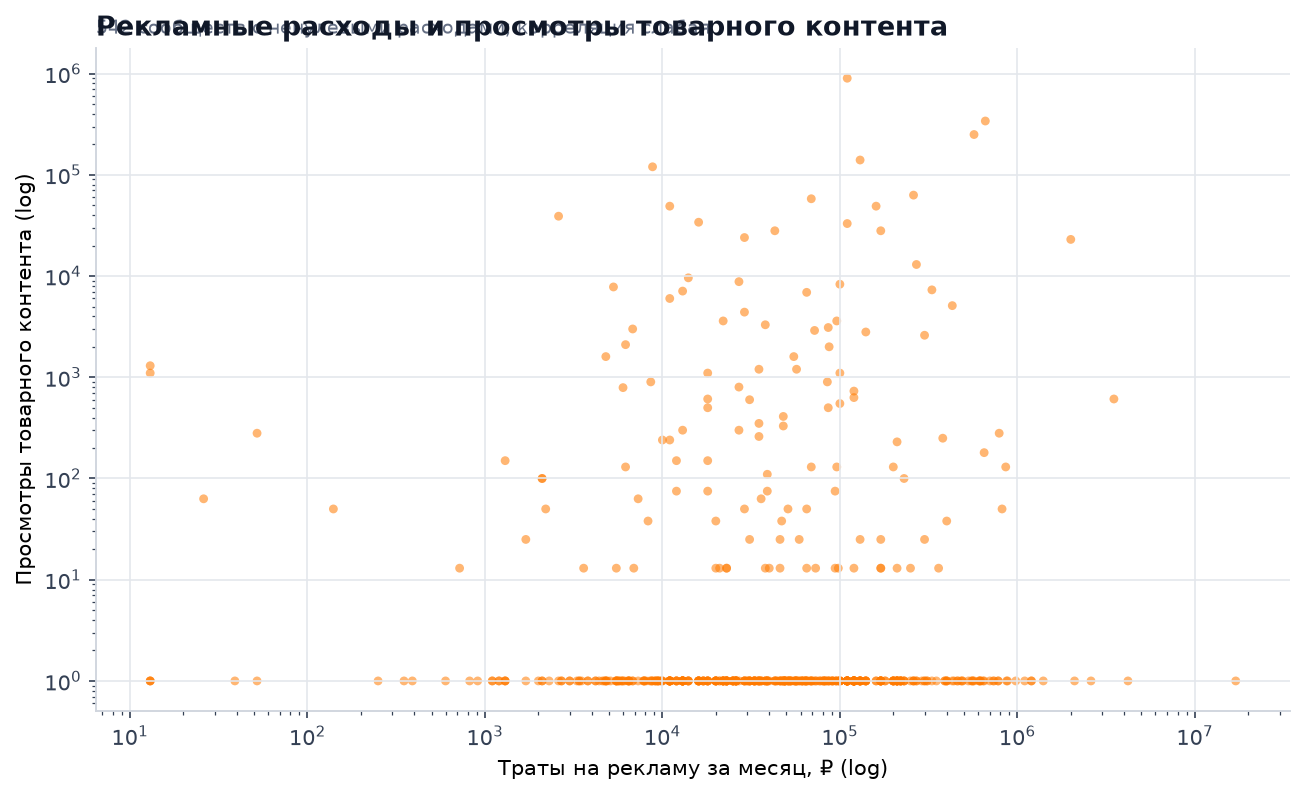

Суммарные траты на рекламу: 92,4 млн ₽
Медиана среди рекламодателей: 45,0 тыс. ₽
Корреляция (log): 0.004


In [21]:
# --- Реклама и товарные просмотры -------------------------------------------
ad = biz[biz['Траты на рекламу всего, ₽'] > 0].copy()

fig, ax = plt.subplots(figsize=(8.8, 5.4))
ax.scatter(ad['Траты на рекламу всего, ₽'], ad['Просмотры товарного контента'].clip(lower=1),
           s=18, alpha=0.55, color=C_PT, edgecolors='none')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Траты на рекламу за месяц, ₽ (log)')
ax.set_ylabel('Просмотры товарного контента (log)')
ax.set_title('Рекламные расходы и просмотры товарного контента')
subtitle(ax, f'{len(ad):,} сообществ с ненулевыми расходами; корреляция слабая'.replace(',', ' '))
plt.tight_layout()
plt.show()

print('Суммарные траты на рекламу:', fmoney(biz['Траты на рекламу всего, ₽'].sum()))
print('Медиана среди рекламодателей:', fmoney(ad['Траты на рекламу всего, ₽'].median()))
print('Корреляция (log):', round(np.corrcoef(np.log1p(ad['Траты на рекламу всего, ₽']),
                                             np.log1p(ad['Просмотры товарного контента']))[0,1], 3))

**Легенда к рекламе.** Оси логарифмические, точка — сообщество; включены 542 сообщества с ненулевыми расходами. Суммарные траты — 92,4 млн ₽, медиана среди рекламодателей — 45,0 тыс. ₽. Облако не образует чёткой линии: корреляция лог-значений всего 0,004. То есть **объём бюджета сам по себе не объясняет просмотры** — решают таргетинг, креатив и органическая дистрибуция. Для платформы это аргумент в пользу продажи не «показов», а результата.

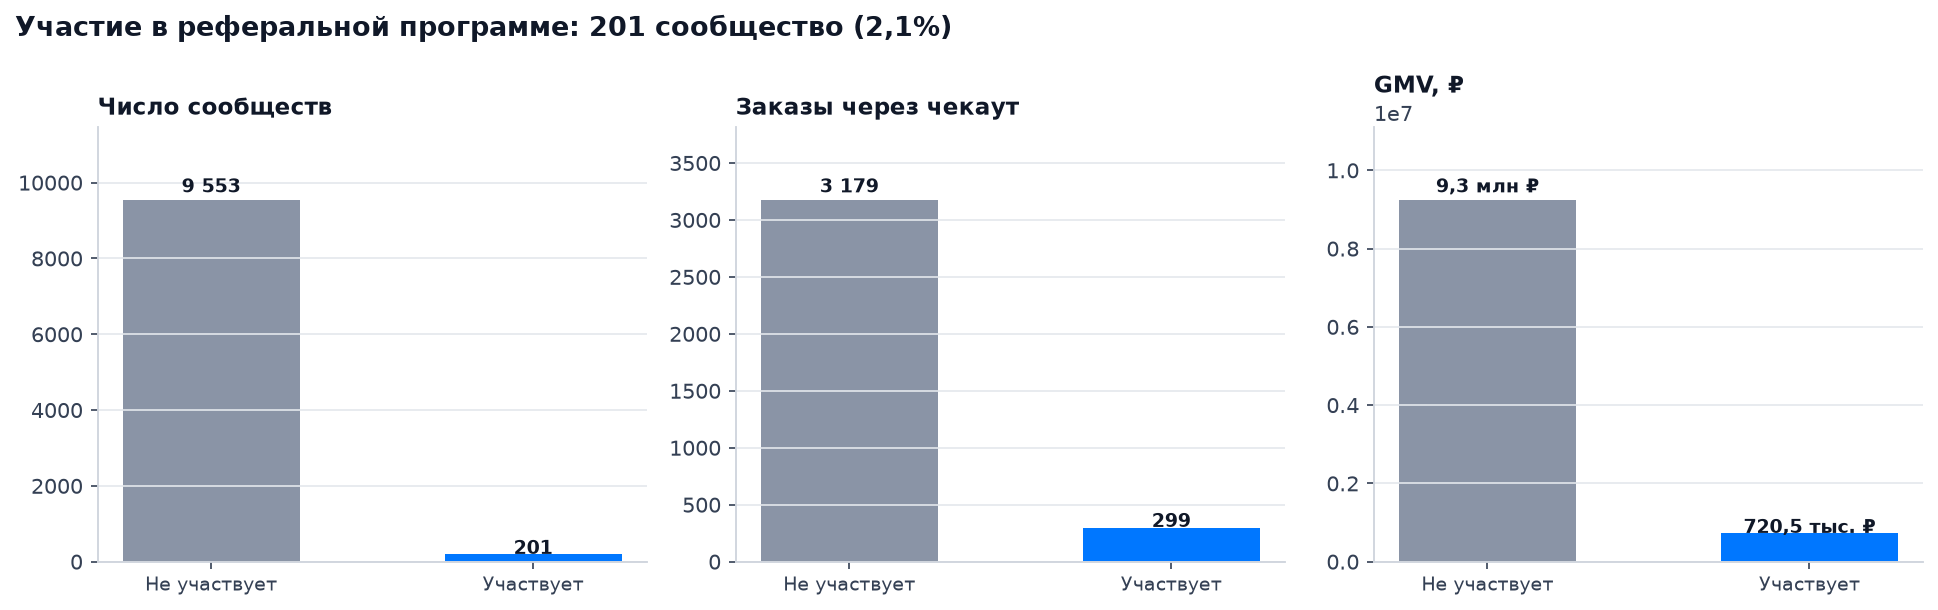

                         Сообществ      GMV  Заказы  Ср_подписчиков  GMV_млн
В реферальной программе                                                     
Не участвует                  9553  9252497    3179      2395.24966     9.25
Участвует                      201   720530     299      6587.58209     0.72
Средний GMV на участника: 3,6 тыс. ₽
Средний GMV на неучастника: 969 ₽


In [22]:
# --- Реферальная программа ---------------------------------------------------
biz['В реферальной программе'] = np.where(biz['Участие в реферальной программе'] == 1, 'Участвует', 'Не участвует')
ref = biz.groupby('В реферальной программе').agg(
    Сообществ=('ID бизнеса','size'),
    GMV=('GMV через чекаут, ₽','sum'),
    Заказы=('Заказы через чекаут','sum'),
    Ср_подписчиков=('Число подписчиков','mean'),
).reindex(['Не участвует','Участвует'])

fig, axes = plt.subplots(1, 3, figsize=(13, 4.1))
for ax, col, ttl, fmt in zip(
        axes,
        ['Сообществ','Заказы','GMV'],
        ['Число сообществ','Заказы через чекаут','GMV, ₽'],
        [lambda v: f'{v:,.0f}'.replace(',', ' '), lambda v: f'{v:,.0f}'.replace(',', ' '), fmoney]):
    bars = ax.bar(ref.index, ref[col], color=[C_GRAY, C_VK], width=0.55)
    ax.set_title(ttl, fontsize=11)
    for b, v in zip(bars, ref[col]):
        ax.text(b.get_x()+b.get_width()/2, v*1.02, fmt(v), ha='center', fontsize=9, fontweight='bold')
    ax.set_ylim(0, ref[col].max()*1.2)
    ax.grid(axis='x', visible=False)
    ax.tick_params(axis='x', labelsize=9)
fig.suptitle('Участие в реферальной программе: 201 сообщество (2,1%)', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

print(ref.assign(GMV_млн=(ref['GMV']/1e6).round(2)).to_string())
print('Средний GMV на участника:', fmoney(ref.loc['Участвует','GMV']/ref.loc['Участвует','Сообществ']))
print('Средний GMV на неучастника:', fmoney(ref.loc['Не участвует','GMV']/ref.loc['Не участвует','Сообществ']))

**Легенда к реферальной программе.** Три панели: число сообществ, заказы, GMV — для участников (синий) и неучастников (серый). Участвуют всего 201 сообщество (2,1%), но на них приходится 720,5 тыс. ₽ GMV из 9,97 млн — **7,2%**. Средний GMV участника — 3 584 ₽ против 969 ₽ у остальных, в 3,7 раза больше. Это не доказательство причинности (в программу идут уже активные), но сильный сигнал: реферальный контур концентрирует наиболее «торгующих» продавцов.

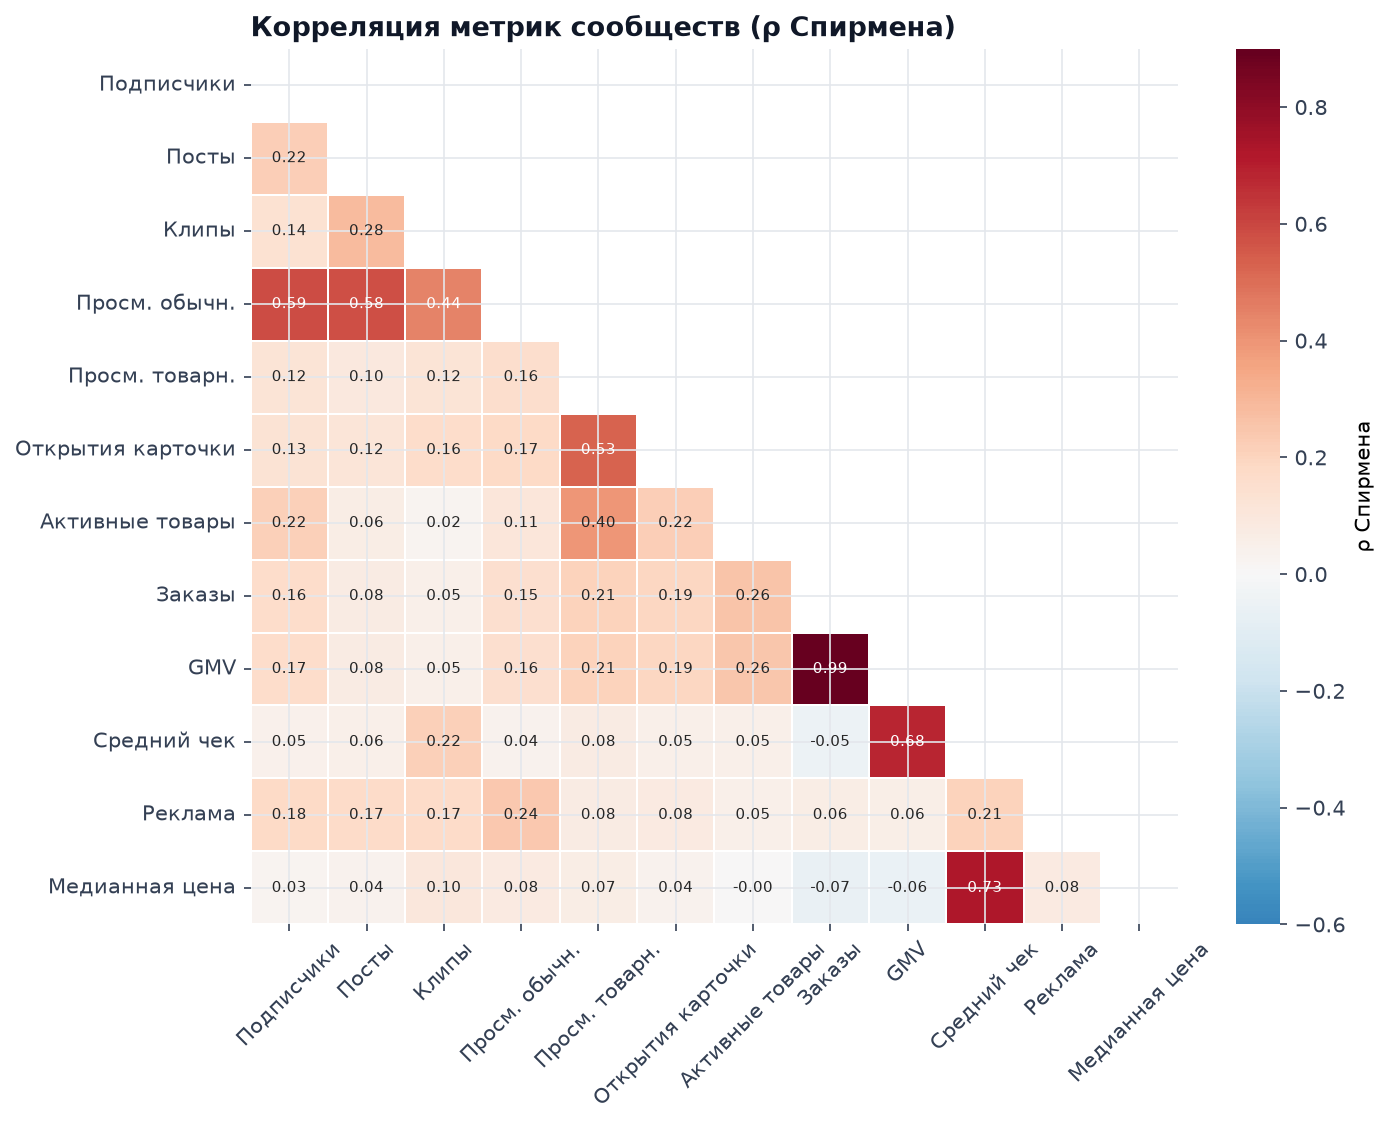

Самые сильные связи с заказами:


,Заказы через чекаут
"GMV через чекаут, ₽",0.99
Число активных товаров в каталоге,0.26
Просмотры товарного контента,0.21
Открытия карточки товара из контента,0.19
Число подписчиков,0.16
Просмотры обычного контента,0.15


In [23]:
# --- Корреляционная матрица (Бизнесы) ----------------------------------------
corr_cols = ['Число подписчиков','Посты за 30 дней','Клипы за 30 дней',
             'Просмотры обычного контента','Просмотры товарного контента',
             'Открытия карточки товара из контента','Число активных товаров в каталоге',
             'Заказы через чекаут','GMV через чекаут, ₽','Средний чек, ₽',
             'Траты на рекламу всего, ₽','Медианная цена товара, ₽']
corr = biz[corr_cols].corr(method='spearman')
short = ['Подписчики','Посты','Клипы','Просм. обычн.','Просм. товарн.','Открытия карточки',
         'Активные товары','Заказы','GMV','Средний чек','Реклама','Медианная цена']

fig, ax = plt.subplots(figsize=(9.6, 7.6))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-0.6, vmax=0.9,
            xticklabels=short, yticklabels=short, linewidths=0.8, linecolor='white',
            cbar_kws={'label': 'ρ Спирмена'}, annot_kws={'fontsize': 7.4}, ax=ax)
ax.set_title('Корреляция метрик сообществ (ρ Спирмена)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print('Самые сильные связи с заказами:')
display(corr['Заказы через чекаут'].drop('Заказы через чекаут').sort_values(ascending=False).head(6).round(2).to_frame())

**Легенда к корреляционной матрице.** Коэффициент Спирмена ρ показывает монотонную связь, устойчивую к выбросам; шкала от −1 до +1, красное — прямая связь, синее — обратная. Читаем строку «Заказы»: сильнее всего с ней связаны GMV (ρ ≈ 0,99 — механическая связь), число активных товаров (ρ ≈ 0,26), загруженные товары (0,24) и просмотры товарного контента (0,21); открытия карточки дают 0,19, подписчики — 0,16. Вывод: **размер аудитории — не главный предиктор продаж**; важнее наличие товара в каталоге и способность вести трафик в карточку, хотя и эти связи умеренные.

In [24]:
# --- Топ-15 сообществ по GMV -------------------------------------------------
top_biz = biz.nlargest(15, 'GMV через чекаут, ₽')[
    ['ID бизнеса','Тематика','Тип бизнеса (товары / услуги)','Число подписчиков',
     'Число активных товаров в каталоге','Открытия карточки товара из контента',
     'Заказы через чекаут','GMV через чекаут, ₽','Средний чек, ₽']].copy()
top_biz['GMV через чекаут, ₽'] = top_biz['GMV через чекаут, ₽'].map(lambda v: f'{v:,.0f}'.replace(',', ' '))
top_biz['Средний чек, ₽'] = top_biz['Средний чек, ₽'].map(lambda v: f'{v:,.0f}'.replace(',', ' ') if pd.notna(v) else '—')
display(top_biz.style.hide(axis='index'))
print('Доля топ-15 в GMV выборки:', fpct(biz.nlargest(15,'GMV через чекаут, ₽')['GMV через чекаут, ₽'].sum()/biz['GMV через чекаут, ₽'].sum()*100))

ID бизнеса,Тематика,Тип бизнеса (товары / услуги),Число подписчиков,Число активных товаров в каталоге,Открытия карточки товара из контента,Заказы через чекаут,"GMV через чекаут, ₽","Средний чек, ₽"
8130,Технологии,товарное,38000,984,0,13,635 250,53 835
8697,Кулинария и еда,товарное,9800,179,0,249,510 440,2 050
5626,Транспорт,товарное,77000,5354,9,129,470 730,3 660
5791,Технологии,товарное,3100,87,0,2,464 980,197 023
1294,Кулинария и еда,товарное,6600,277,0,307,455 320,1 484
8757,Товары и магазины,товарное,200000,1083,462,54,431 530,7 950
4974,Игры,товарное,42000,302,0,543,345 510,640
7437,Красота и здоровье,товарное,1700,712,3,37,322 940,8 828
9621,Образование,товарное и услужное,4100,1,0,4,299 630,84 640
2730,Товары и магазины,товарное,3500,68,0,2,279 980,118 633


Доля топ-15 в GMV выборки: 54,5%


**Легенда к топ-15 сообществ.** Таблица показывает крупнейших продавцов выборки: ID, тематику, тип, аудиторию, число активных товаров, открытия карточки, заказы, GMV и средний чек. Топ-15 дают 54,5% всего GMV выборки при доле в сообществах 0,15%. Обратите внимание: у части лидеров небольшая аудитория, но много активных товаров и открытий — ещё одно подтверждение, что каталог и трафик важнее подписчиков.

## 2. Таблица 2 «Маркет ВКонтакте — итоги»: макроуровень

Здесь сопоставлены два сегмента одного месяца: **Маркет ВКонтакте** (собственная витрина и чекаут платформы) и **Партнёр 1** (внешний маркетплейс, интегрированный в ВКонтакте). Это главный лист для ответа на вопрос «какую роль играет Маркет».

### 2.1. Сводная таблица метрик

Значения приведены как в файле; производные показатели рассчитаны отдельно и помечены.

In [25]:
# --- Разбор сводных метрик ---------------------------------------------------
M = {}
for _, r in tot.iterrows():
    M[str(r['Метрика'])] = (r['Маркет Вконтакте'], r['Партнёр 1'], r['Всего'])

def gv(name, i=0):
    v = M.get(name, (np.nan, np.nan, np.nan))[i]
    return np.nan if isinstance(v, str) else v

IMP_VK, IMP_PT = gv('Показы товаров',0), gv('Показы товаров',1)
OPEN_VK, OPEN_PT = gv('Открытия карточки товара',0), gv('Открытия карточки товара',1)
CLICK_VK, CLICK_PT = gv('Нажатия на кнопку в карточке',0), gv('Нажатия на кнопку в карточке',1)
ORD_VK, ORD_PT = gv('Оформленные заказы',0), gv('Оформленные заказы',1)
PAID_VK = gv('Оплаченные заказы',0)
GMV_VK, GMV_PT = gv('GMV, ₽',0), gv('GMV, ₽',1)
AOV_VK, AOV_PT = gv('Средний чек, ₽',0), gv('Средний чек, ₽',1)
BUY_VK, BUY_PT = gv('Уникальные покупатели за 30 дней',0), gv('Уникальные покупатели за 30 дней',1)
OPB_VK, OPB_PT = gv('Заказов на покупателя',0), gv('Заказов на покупателя',1)
REP_VK, REP_PT = gv('Доля повторных покупателей (2+ заказа), %',0), gv('Доля повторных покупателей (2+ заказа), %',1)
CR1_VK, CR1_PT = gv('Конверсия: показ → открытие карточки, %',0), gv('Конверсия: показ → открытие карточки, %',1)
CR2_VK, CR2_PT = gv('Конверсия: открытие карточки → заказ, %',0), gv('Конверсия: открытие карточки → заказ, %',1)
CR3_VK, CR3_PT = gv('Конверсия: показ → заказ, %',0), gv('Конверсия: показ → заказ, %',1)
DIRECT_PT = gv('Прямые переходы к Партнёру 1 (без открытия карточки)',1)

DAU = gv('DAU Маркета Вконтакте (среднее за день)',2)
MAU = gv('MAU Маркета Вконтакте (уникальные за 30 дней)',2)
VIEWERS = gv('Пользователи, видевшие товары за 30 дней',2)
OPENERS = gv('Пользователи, открывавшие карточку товара за 30 дней',2)
POST_OPENS = gv('Открытия карточки товара из постов и клипов',2)
REF_OPENS = gv('в т.ч. из реферальных постов и клипов',2)
QUERIES = gv('Запросы в товарном поиске',2)
SEARCH_CR = gv('Доля поисковых запросов с открытием карточки, %',2)

# Производные метрики
GMV_ALL = GMV_VK + GMV_PT
ORD_ALL = ORD_VK + ORD_PT
BUY_ALL = BUY_VK + BUY_PT
CLICK_CR_VK = ORD_VK / CLICK_VK * 100
CLICK_CR_PT = ORD_PT / CLICK_PT * 100
OPEN_CLICK_VK = CLICK_VK / OPEN_VK * 100
OPEN_CLICK_PT = CLICK_PT / OPEN_PT * 100
GMVB_VK = GMV_VK / BUY_VK
GMVB_PT = GMV_PT / BUY_PT
ORD1000_VK = ORD_VK / IMP_VK * 1000
ORD1000_PT = ORD_PT / IMP_PT * 1000
GMV1000_VK = GMV_VK / IMP_VK * 1000
GMV1000_PT = GMV_PT / IMP_PT * 1000
PAID_SHARE_VK = PAID_VK / ORD_VK * 100

kpi = pd.DataFrame([
    ('Показы товаров', fnum(IMP_VK,2), fnum(IMP_PT,2), fpct(IMP_VK/(IMP_VK+IMP_PT)*100)),
    ('Открытия карточки', fnum(OPEN_VK,1), fnum(OPEN_PT,1), fpct(OPEN_VK/(OPEN_VK+OPEN_PT)*100)),
    ('Нажатия на кнопку', fnum(CLICK_VK,2), fnum(CLICK_PT,2), fpct(CLICK_VK/(CLICK_VK+CLICK_PT)*100)),
    ('Оформленные заказы', fnum(ORD_VK,0), fnum(ORD_PT,0), fpct(ORD_VK/ORD_ALL*100)),
    ('Оплаченные заказы', fnum(PAID_VK,0), '—', '—'),
    ('GMV', fmoney(GMV_VK,2), fmoney(GMV_PT,2), fpct(GMV_VK/GMV_ALL*100)),
    ('Средний чек', fmoney(AOV_VK,0), fmoney(AOV_PT,0), '×'+f'{AOV_VK/AOV_PT:.2f}'.replace('.', ',')),
    ('Уникальные покупатели', fnum(BUY_VK,0), fnum(BUY_PT,0), fpct(BUY_VK/BUY_ALL*100)),
    ('Заказов на покупателя', f'{OPB_VK:.1f}'.replace('.', ','), f'{OPB_PT:.1f}'.replace('.', ','), '—'),
    ('Доля повторных покупателей', fpct(REP_VK), fpct(REP_PT), '—'),
    ('CR: показ → открытие', fpct(CR1_VK,2), fpct(CR1_PT,2), '—'),
    ('CR: открытие → заказ', fpct(CR2_VK,2), fpct(CR2_PT,2), '—'),
    ('CR: показ → заказ', fpct(CR3_VK,3), fpct(CR3_PT,3), '—'),
    ('Прямые переходы к Партнёру', '—', fnum(DIRECT_PT,1), '—'),
], columns=['Метрика', 'Маркет ВКонтакте', 'Партнёр 1', 'Доля Маркета'])

display(kpi.style.hide(axis='index').set_caption('Сводные метрики за сентябрь 2026'))
print('Итого GMV:', fmoney(GMV_ALL,2), '| заказов:', f'{int(ORD_ALL):,}'.replace(',', ' '),
      '| покупателей:', f'{int(BUY_ALL):,}'.replace(',', ' '))

Метрика,Маркет ВКонтакте,Партнёр 1,Доля Маркета
Показы товаров,"4,78 млрд","5,73 млрд","45,5%"
Открытия карточки,"193,5 млн","86,9 млн","69,0%"
Нажатия на кнопку,"5,97 млн","36,63 млн","14,0%"
Оформленные заказы,414 тыс.,5 млн,"7,7%"
Оплаченные заказы,5 тыс.,—,—
GMV,"1,56 млрд ₽","5,12 млрд ₽","23,4%"
Средний чек,4 тыс. ₽,1 тыс. ₽,"×3,64"
Уникальные покупатели,296 тыс.,3 млн,"9,3%"
Заказов на покупателя,"1,4","1,7",—
Доля повторных покупателей,"19,0%","26,6%",—


Итого GMV: 6,68 млрд ₽ | заказов: 5 341 265 | покупателей: 3 197 482


**Легенда к сводной таблице.** Строки — метрики, три числовых столбца — значения сегментов и доля Маркета ВКонтакте в общем показателе. Ключевые числа: 4,78 млрд показов у Маркета против 5,73 млрд у Партнёра (45,5% против 54,5%), но 193,5 млн открытий против 86,9 млн (69,0% против 31,0%). Дальше пропорции переворачиваются: 413,7 тыс. заказов против 4,93 млн (7,7% против 92,3%) и 1,56 млрд ₽ против 5,12 млрд ₽ GMV (23,4% против 76,6%). То есть **Маркет выигрывает верх воронки и проигрывает низ**: он приводит людей в карточку, но завершает сделку партнёр.

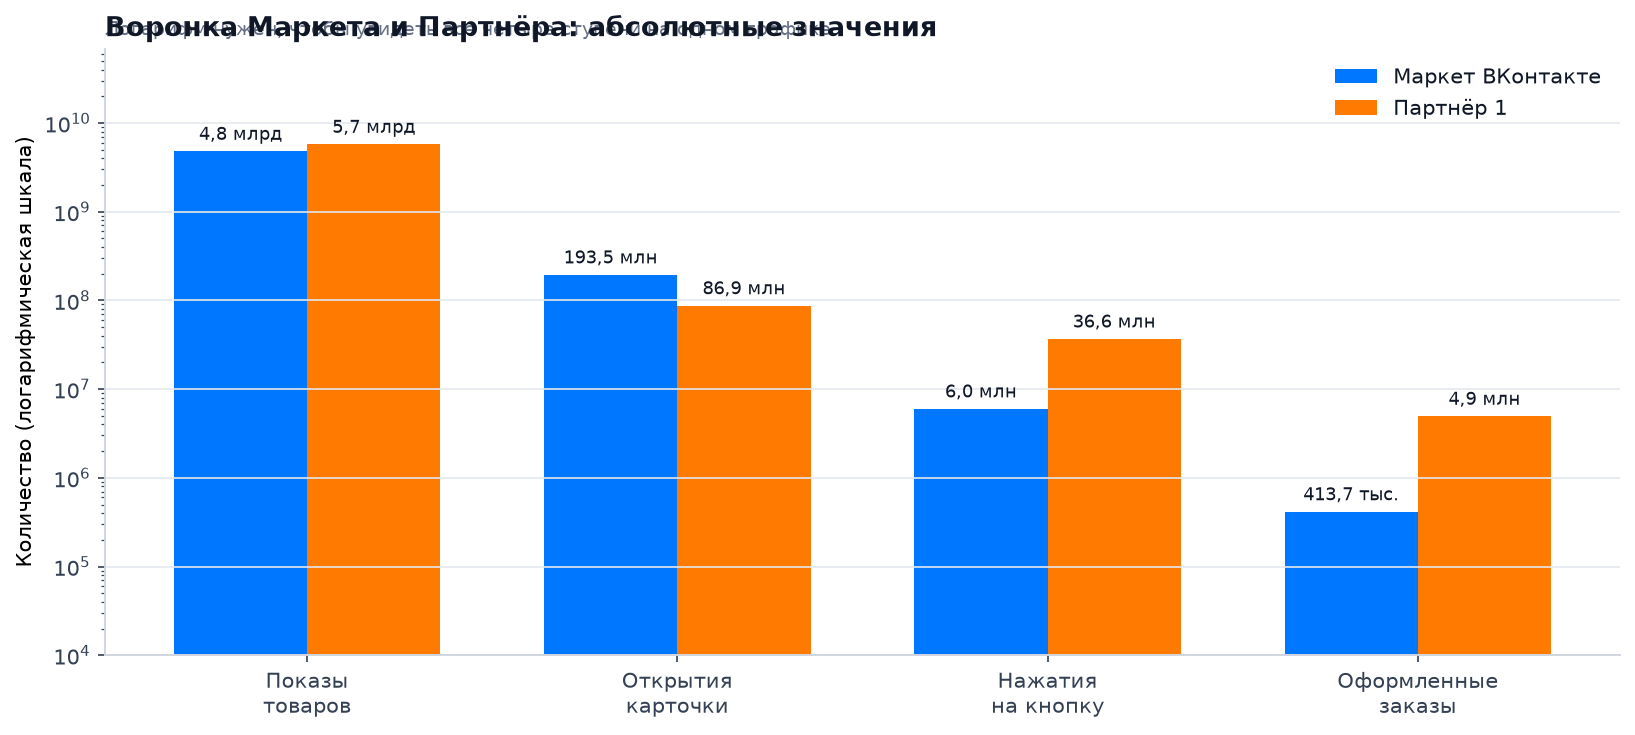

Ступень,Маркет,Партнёр,"Доля Маркета, %"
Показы товаров,"4,777,750,023","5,729,628,790",45.5
Открытия карточки,"193,512,461","86,882,822",69.0
Нажатия на кнопку,"5,969,063","36,626,075",14.0
Оформленные заказы,"413,740","4,927,525",7.7


In [26]:
# --- Воронка: абсолютные значения -------------------------------------------
stages = ['Показы\nтоваров', 'Открытия\nкарточки', 'Нажатия\nна кнопку', 'Оформленные\nзаказы']
vkv = [IMP_VK, OPEN_VK, CLICK_VK, ORD_VK]
vpt = [IMP_PT, OPEN_PT, CLICK_PT, ORD_PT]

x = np.arange(len(stages)); w = 0.36
fig, ax = plt.subplots(figsize=(11, 5))
b1 = ax.bar(x - w/2, vkv, w, label='Маркет ВКонтакте', color=C_VK)
b2 = ax.bar(x + w/2, vpt, w, label='Партнёр 1', color=C_PT)
ax.set_yscale('log')
ax.set_ylabel('Количество (логарифмическая шкала)')
ax.set_title('Воронка Маркета и Партнёра: абсолютные значения')
subtitle(ax, 'Логарифм нужен, чтобы увидеть все четыре ступени на одном графике')
ax.set_xticks(x); ax.set_xticklabels(stages)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()*1.35, fnum(b.get_height(),1),
                ha='center', fontsize=8.5, rotation=0)
ax.set_ylim(1e4, max(IMP_VK, IMP_PT)*12)
ax.legend(loc='upper right')
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

funnel = pd.DataFrame({'Ступень': stages, 'Маркет': vkv, 'Партнёр': vpt})
funnel['Доля Маркета, %'] = (funnel['Маркет']/(funnel['Маркет']+funnel['Партнёр'])*100).round(1)
display(funnel.style.hide(axis='index').format({'Маркет':'{:,.0f}','Партнёр':'{:,.0f}','Доля Маркета, %':'{:.1f}'}))

**Легенда к воронке.** Четыре ступени слева направо: показы → открытия карточки → нажатия на кнопку → заказы. Синие столбцы — Маркет, оранжевые — Партнёр, шкала Y логарифмическая. Читать по парам: на показах паритет (4,8 против 5,7 млрд), на открытиях Маркет впереди в 2,2 раза, на нажатиях уже отстаёт в 6,1 раза, на заказах — в 11,9 раза. Это визуальный «крест»: **линия Маркета падает круче**. Причина — не показы, а глубина воронки: люди охотно смотрят карточку, но редко покупают внутри Маркета.

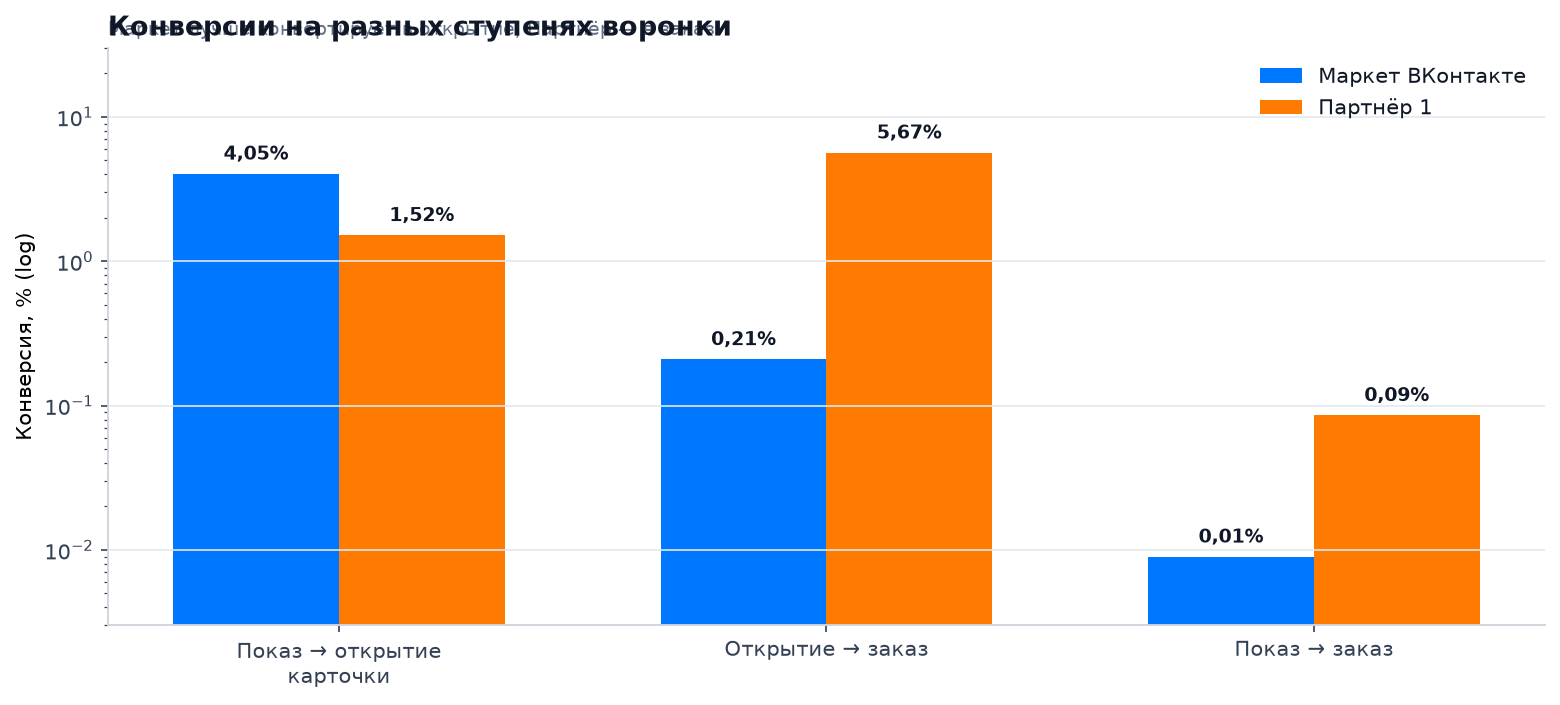

Показатель,Маркет,Партнёр
"Открытие → нажатие, %",3.08,42.16
"Нажатие → заказ, %",6.93,13.45
Заказов на 1 000 показов,0.09,0.86
"GMV на 1 000 показов, ₽",327.47,893.52
"GMV на покупателя, ₽",5282.99,1764.54
"Доля оплаченных заказов, %",1.19,nan


In [27]:
# --- Конверсии по ступеням ---------------------------------------------------
labels = ['Показ → открытие\nкарточки', 'Открытие → заказ', 'Показ → заказ']
x = np.arange(3); w = 0.34
fig, ax = plt.subplots(figsize=(10.5, 4.8))
b1 = ax.bar(x - w/2, [CR1_VK, CR2_VK, CR3_VK], w, label='Маркет ВКонтакте', color=C_VK)
b2 = ax.bar(x + w/2, [CR1_PT, CR2_PT, CR3_PT], w, label='Партнёр 1', color=C_PT)
ax.set_yscale('log')
ax.set_ylabel('Конверсия, % (log)')
ax.set_title('Конверсии на разных ступенях воронки')
subtitle(ax, 'Маркет лучше конвертирует в открытие, Партнёр — в заказ')
ax.set_xticks(x); ax.set_xticklabels(labels)
for bars in (b1, b2):
    for b in bars:
        ax.text(b.get_x()+b.get_width()/2, b.get_height()*1.25, fpct(b.get_height(),2),
                ha='center', fontsize=9, fontweight='bold')
ax.set_ylim(0.003, 30)
ax.legend()
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

extra = pd.DataFrame({
    'Показатель': ['Открытие → нажатие, %', 'Нажатие → заказ, %', 'Заказов на 1 000 показов',
                   'GMV на 1 000 показов, ₽', 'GMV на покупателя, ₽', 'Доля оплаченных заказов, %'],
    'Маркет': [OPEN_CLICK_VK, CLICK_CR_VK, ORD1000_VK, GMV1000_VK, GMVB_VK, PAID_SHARE_VK],
    'Партнёр': [OPEN_CLICK_PT, CLICK_CR_PT, ORD1000_PT, GMV1000_PT, GMVB_PT, np.nan],
})
display(extra.round(2).style.hide(axis='index').format({'Маркет':'{:.2f}','Партнёр':'{:.2f}'}))

**Легенда к конверсиям.** Три пары столбцов, шкала Y логарифмическая, потому что конверсии различаются на порядки. Первая пара: показ → открытие карточки — 4,05% у Маркета против 1,52% у Партнёра, Маркет в 2,7 раза лучше. Вторая: открытие → заказ — 0,21% против 5,67%, Партнёр в 27 раз лучше. Третья: сквозная показ → заказ — 0,009% против 0,086%, Партнёр в 9,6 раза лучше.

Дополнительная таблица раскрывает механику: у Партнёра 42,2% открытий доходят до нажатия кнопки против 3,1% у Маркета, а нажатие превращается в заказ в 13,5% случаев против 6,9%. Значит, у Партнёра сильнее не только «желание нажать», но и транзакционный сценарий: привычный чекаут, доставка, узнаваемость маркетплейса.

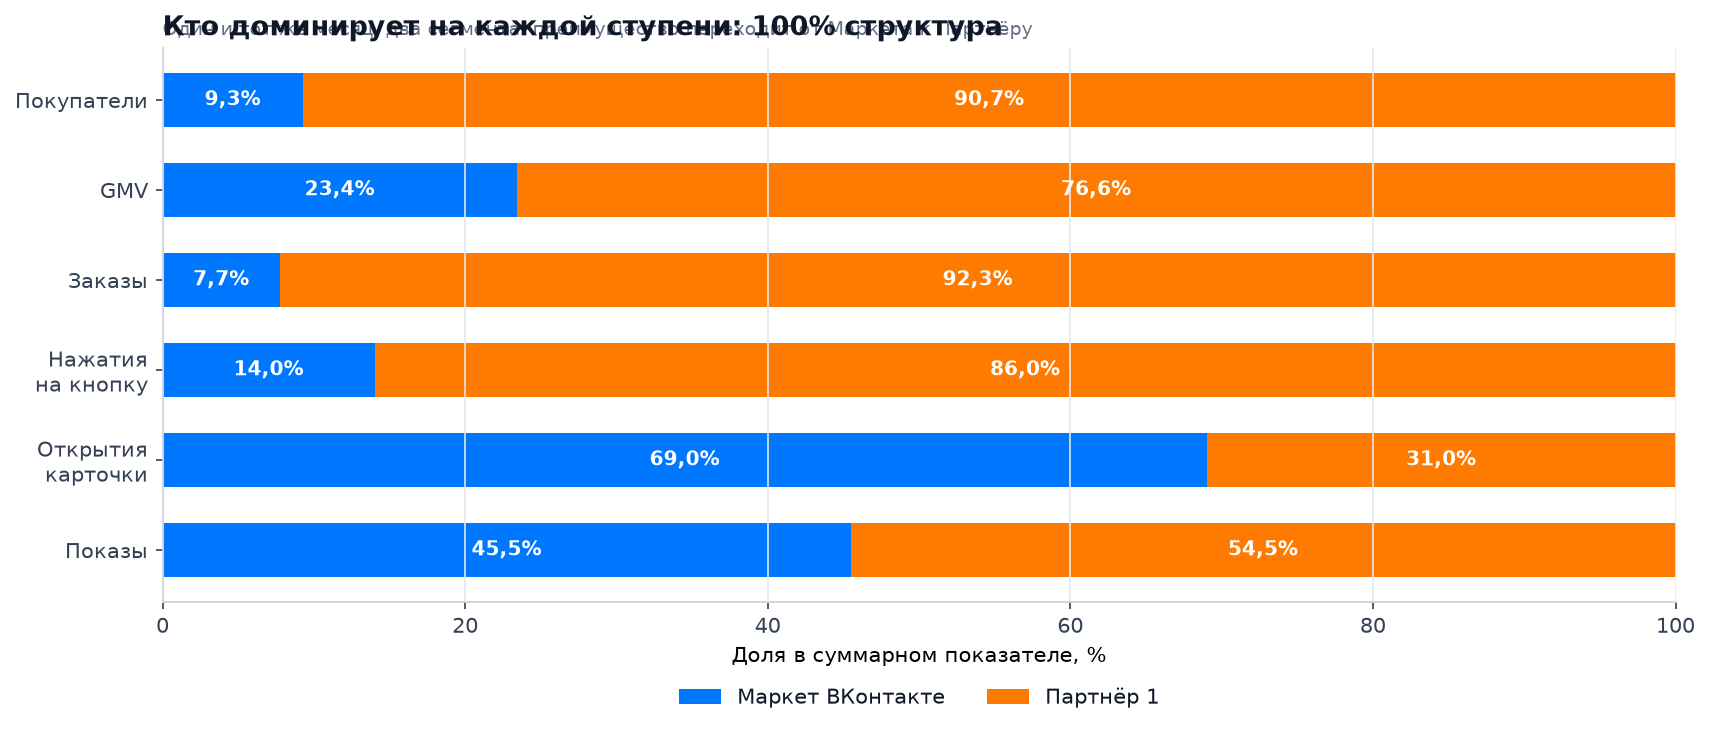

In [28]:
# --- 100% структура по ступеням ---------------------------------------------
stages = ['Показы', 'Открытия\nкарточки', 'Нажатия\nна кнопку', 'Заказы', 'GMV', 'Покупатели']
vk_abs = np.array([IMP_VK, OPEN_VK, CLICK_VK, ORD_VK, GMV_VK, BUY_VK], dtype=float)
pt_abs = np.array([IMP_PT, OPEN_PT, CLICK_PT, ORD_PT, GMV_PT, BUY_PT], dtype=float)
vk_sh = vk_abs/(vk_abs+pt_abs)*100
pt_sh = 100 - vk_sh

fig, ax = plt.subplots(figsize=(11.5, 5))
y = np.arange(len(stages))
ax.barh(y, vk_sh, color=C_VK, height=0.6, label='Маркет ВКонтакте')
ax.barh(y, pt_sh, left=vk_sh, color=C_PT, height=0.6, label='Партнёр 1')
for i in range(len(stages)):
    ax.text(vk_sh[i]/2, i, f'{vk_sh[i]:.1f}%'.replace('.', ','), ha='center', va='center',
            color='white', fontsize=9.5, fontweight='bold')
    ax.text(vk_sh[i]+pt_sh[i]/2, i, f'{pt_sh[i]:.1f}%'.replace('.', ','), ha='center', va='center',
            color='white', fontsize=9.5, fontweight='bold')
ax.set_yticks(y); ax.set_yticklabels(stages)
ax.set_xlim(0, 100)
ax.set_xlabel('Доля в суммарном показателе, %')
ax.set_title('Кто доминирует на каждой ступени: 100% структура')
subtitle(ax, 'Один и тот же месяц, два сегмента: преимущество переходит от Маркета к Партнёру')
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к 100% структуре.** Каждая строка — ступень воронки, длина полосы = 100%, синяя часть — вклад Маркета, оранжевая — Партнёра. Это самый наглядный график о роли: Маркет ведёт на показах (45,5%) и доминирует на открытиях карточки (69,0%), но уступает на нажатиях (14,0%), заказах (7,7%), GMV (23,4%) и покупателях (9,3%). Перелом происходит между открытием карточки и нажатием кнопки. Именно там Маркет теряет пользователя. Гипотезы: цена, доверие к чекауту, срок доставки, ассортимент.

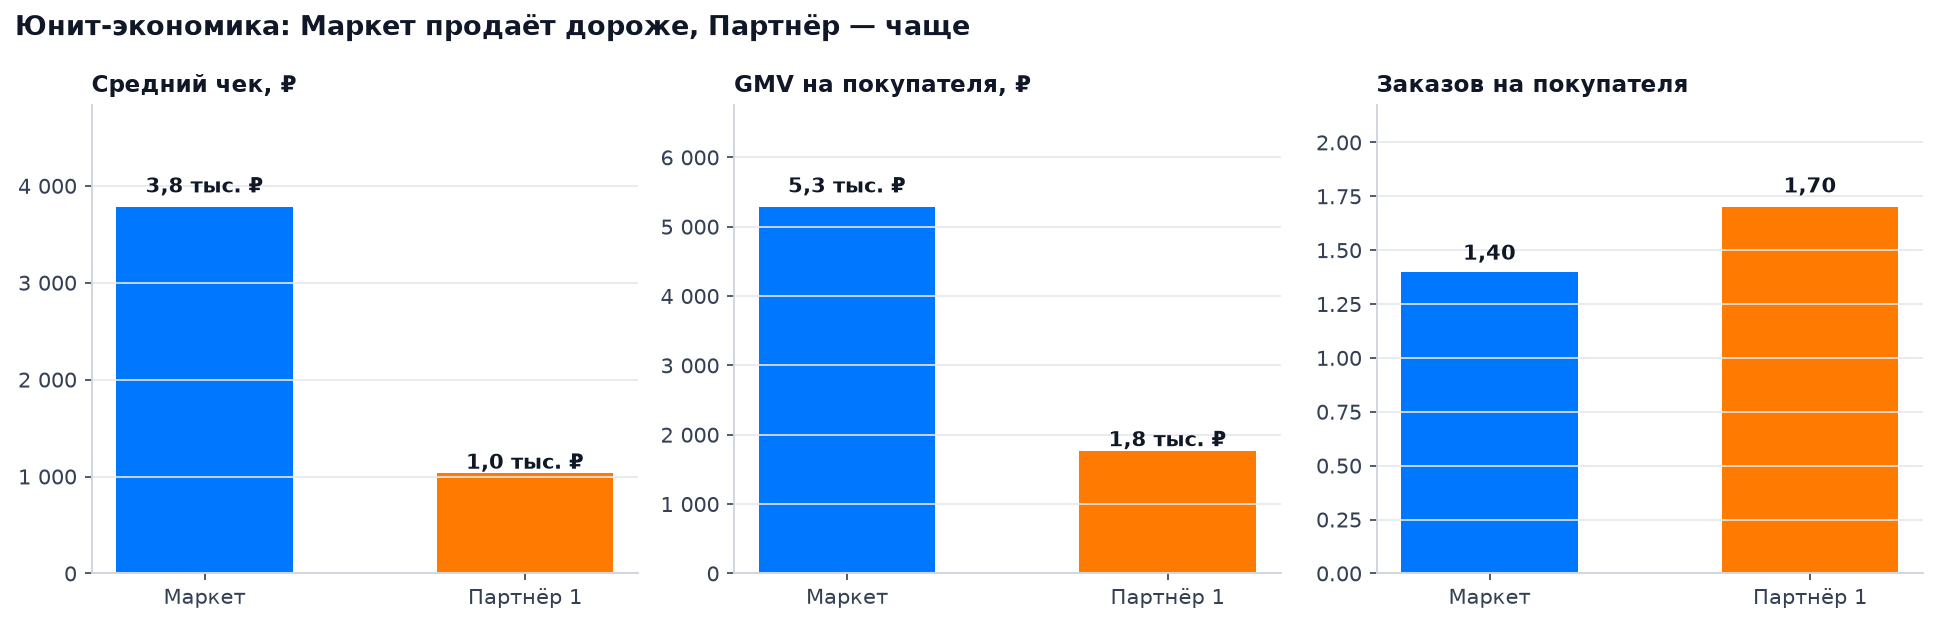

Отношение среднего чека Маркет/Партнёр: 3.64
Отношение GMV на покупателя: 2.99
Отношение заказов на покупателя: 0.82


In [29]:
# --- Юнит-экономика ----------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2))
data = [('Средний чек, ₽', AOV_VK, AOV_PT, fmoney),
        ('GMV на покупателя, ₽', GMVB_VK, GMVB_PT, fmoney),
        ('Заказов на покупателя', OPB_VK, OPB_PT, lambda v: f'{v:.2f}'.replace('.', ','))]
for ax, (ttl, a, b, fmt) in zip(axes, data):
    bars = ax.bar(['Маркет', 'Партнёр 1'], [a, b], color=[C_VK, C_PT], width=0.55)
    ax.set_title(ttl, fontsize=11)
    ax.set_ylim(0, max(a, b)*1.28)
    for bar, v in zip(bars, [a, b]):
        ax.text(bar.get_x()+bar.get_width()/2, v*1.04, fmt(v), ha='center', fontsize=10, fontweight='bold')
    ax.grid(axis='x', visible=False)
    if ttl.startswith('Средний') or ttl.startswith('GMV'):
        ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{v:,.0f}'.replace(',', ' ')))
fig.suptitle('Юнит-экономика: Маркет продаёт дороже, Партнёр — чаще', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

print('Отношение среднего чека Маркет/Партнёр:', round(AOV_VK/AOV_PT,2))
print('Отношение GMV на покупателя:', round(GMVB_VK/GMVB_PT,2))
print('Отношение заказов на покупателя:', round(OPB_VK/OPB_PT,2))

**Легенда к юнит-экономике.** Три панели: средний чек, GMV на покупателя, число заказов на покупателя; синий — Маркет, оранжевый — Партнёр. Средний чек Маркета 3 781 ₽ против 1 039 ₽ (в 3,64 раза выше), GMV на покупателя 5 283 ₽ против 1 765 ₽ (в 2,99 раза), заказов на покупателя 1,40 против 1,71 (на 18% меньше). Портрет: **Маркет — «редкие дорогие покупки», Партнёр — «частые недорогие»**. Это два разных потребительских сценария, а не конкуренты за одного и того же покупателя.

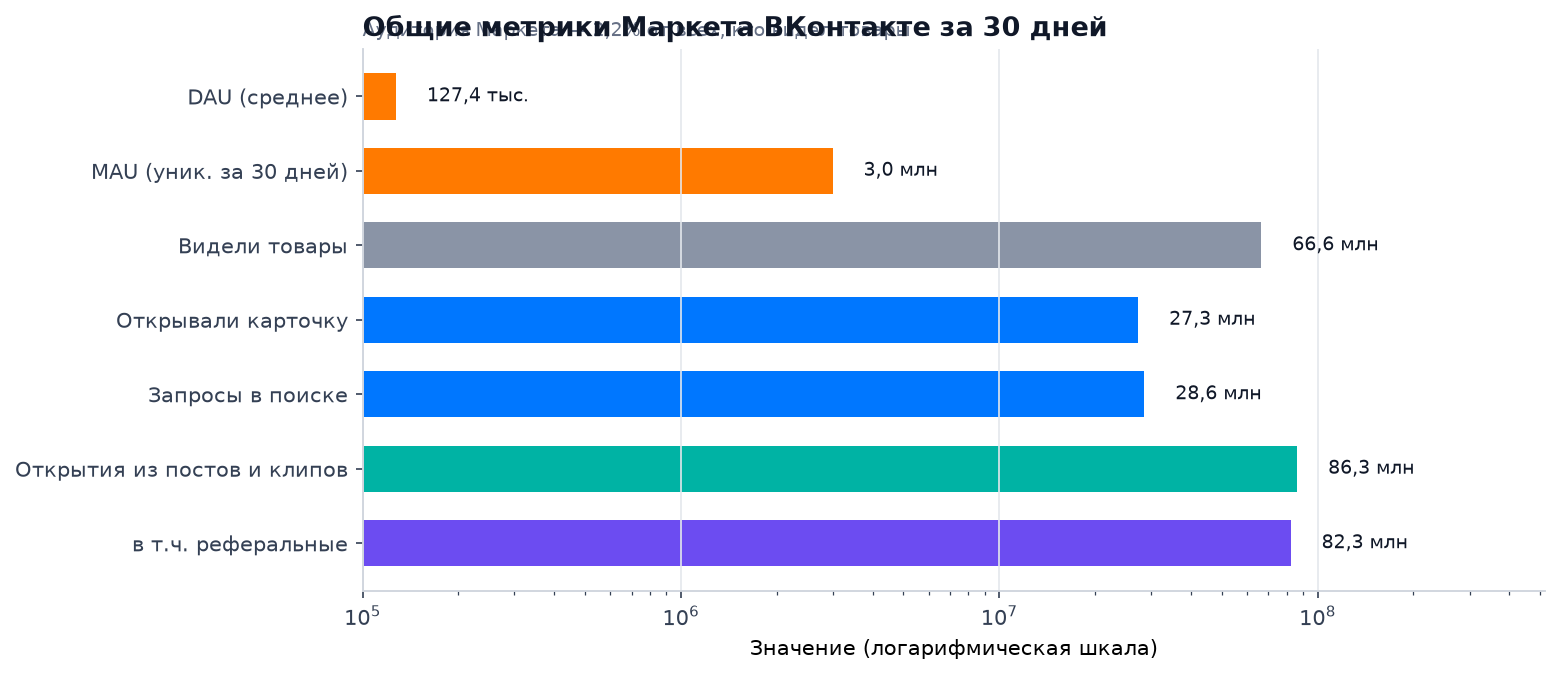

DAU/MAU: 4,3% | открытие карточки от видевших: 41,0%
Открытий на одного открывавшего: 7.08
Доля реферальных в открытиях из постов/клипов: 95,4%


In [30]:
# --- Общие метрики Маркета ---------------------------------------------------
overall = pd.Series({
    'DAU (среднее)': DAU,
    'MAU (уник. за 30 дней)': MAU,
    'Видели товары': VIEWERS,
    'Открывали карточку': OPENERS,
    'Запросы в поиске': QUERIES,
    'Открытия из постов и клипов': POST_OPENS,
    'в т.ч. реферальные': REF_OPENS,
})

fig, ax = plt.subplots(figsize=(10.5, 4.6))
bars = ax.barh(overall.index[::-1], overall.values[::-1],
               color=[C_ACC, C_TEAL, C_VK, C_VK, C_GRAY, C_PT, C_PT], height=0.62)
ax.set_xscale('log')
ax.set_xlabel('Значение (логарифмическая шкала)')
ax.set_title('Общие метрики Маркета ВКонтакте за 30 дней')
subtitle(ax, 'Аудитория Маркета — 2,2% от всех, кто видел товары')
for b, v in zip(bars, overall.values[::-1]):
    ax.text(v*1.25, b.get_y()+b.get_height()/2, fnum(v,1), va='center', fontsize=9)
ax.set_xlim(1e5, overall.max()*6)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('DAU/MAU:', fpct(DAU/MAU*100), '| открытие карточки от видевших:', fpct(OPENERS/VIEWERS*100))
print('Открытий на одного открывавшего:', round(OPEN_VK/OPENERS,2))
print('Доля реферальных в открытиях из постов/клипов:', fpct(REF_OPENS/POST_OPENS*100))

**Легенда к общим метрикам.** Горизонтальные столбцы, логарифмическая шкала. Сверху вниз: DAU 127 тыс., MAU 3,0 млн, 66,6 млн видели товары, 27,3 млн открывали карточку, 28,6 млн поисковых запросов, 86,3 млн открытий из постов и клипов, из них 82,3 млн — реферальные.

Три вывода. Первый: **DAU/MAU = 4,3%** — очень низкая «прилипчивость»: Маркетом пользуются эпизодически, чаще всего случайно наткнувшись на товар. Второй: карточку открывает 41,0% видевших товар — верх воронки работает. Третий: 95,4% открытий из контента — реферальные, то есть контент авторов и клипы, а не собственная витрина, являются главным входом.

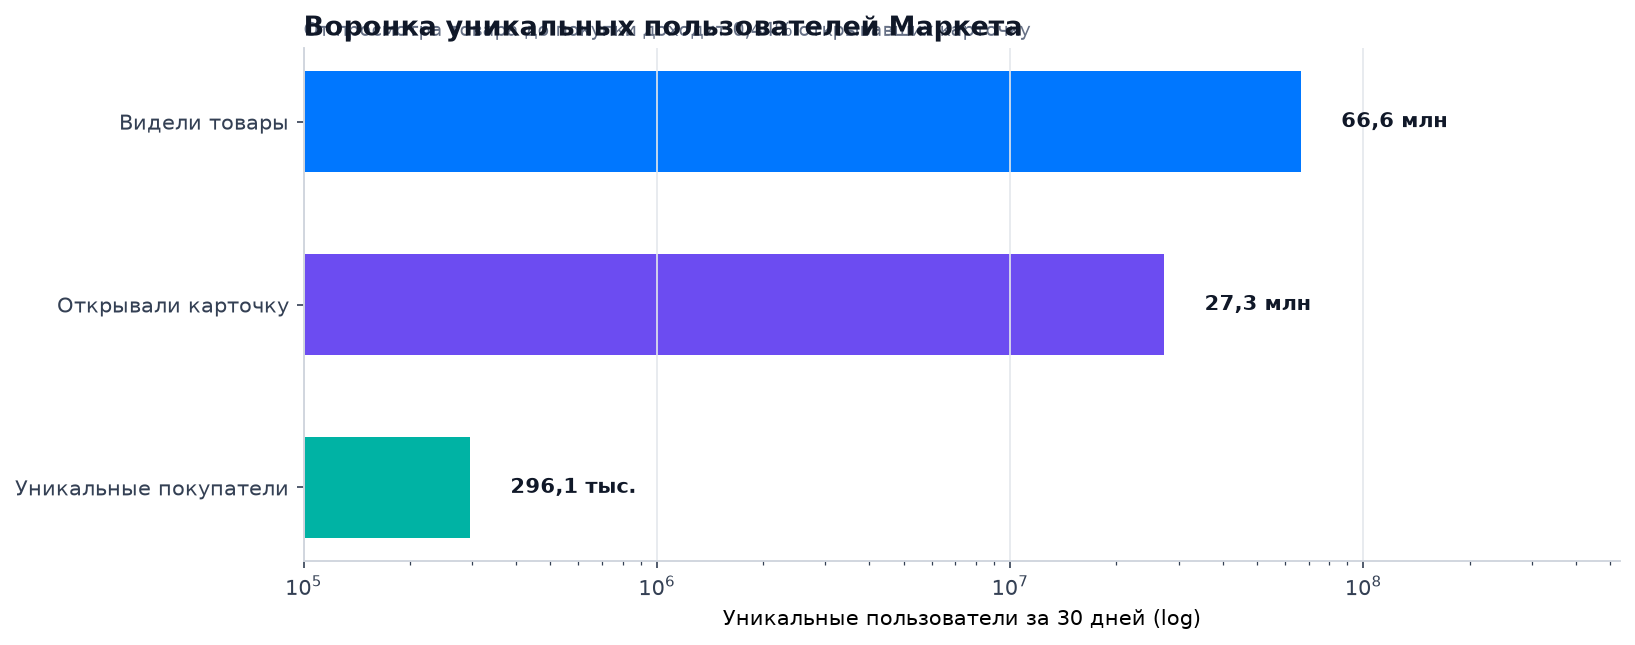

Видели → открывали: 41,0%
Открывали → купили: 1,1%
Видели → купили: 0,44%


In [31]:
# --- Пользовательская воронка Маркета ---------------------------------------
steps = ['Видели товары', 'Открывали карточку', 'Уникальные покупатели']
vals = [VIEWERS, OPENERS, BUY_VK]
colors = [C_VK, C_ACC, C_TEAL]

fig, ax = plt.subplots(figsize=(11, 4.4))
bars = ax.barh(steps[::-1], vals[::-1], color=colors[::-1], height=0.55)
ax.set_xscale('log')
ax.set_xlabel('Уникальные пользователи за 30 дней (log)')
ax.set_title('Воронка уникальных пользователей Маркета')
subtitle(ax, 'От просмотра товара до покупки доходит 0,44% открывавших карточку')
for b, v in zip(bars, vals[::-1]):
    ax.text(v*1.3, b.get_y()+b.get_height()/2, fnum(v,1), va='center', fontsize=10, fontweight='bold')
ax.set_xlim(1e5, VIEWERS*8)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Видели → открывали:', fpct(OPENERS/VIEWERS*100))
print('Открывали → купили:', fpct(BUY_VK/OPENERS*100))
print('Видели → купили:', fpct(BUY_VK/VIEWERS*100, 2))

**Легенда к пользовательской воронке.** Три ступени по уникальным людям за 30 дней: 66,6 млн видели товары → 27,3 млн открывали карточку (41,0%) → 296 тыс. купили (1,08% открывавших и 0,44% видевших). Шкала логарифмическая. Это «жёсткая» воронка: между интересом и покупкой теряется 99% людей. Для сравнения, у Партнёра покупателей 2,9 млн — почти в 10 раз больше при меньшем числе открытий карточки. Разрыв объясняется не охватом, а транзакционным опытом.

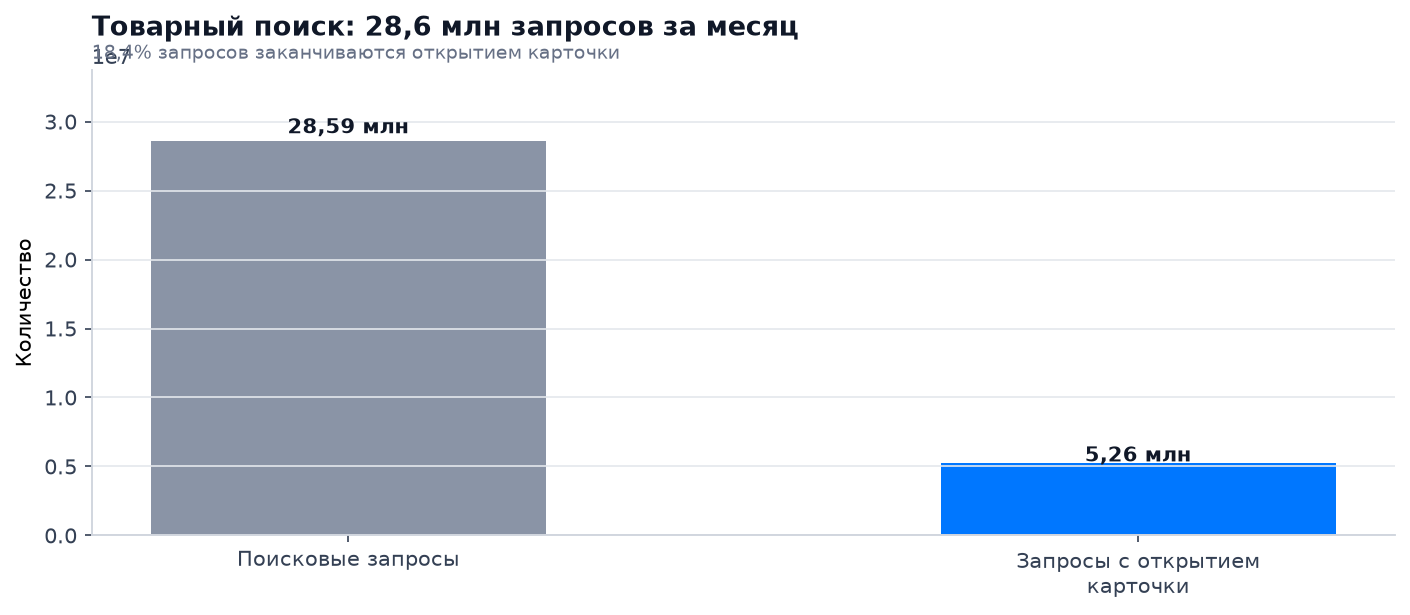

Запросов с открытием карточки: 5,26 млн
Поиск даёт 2,7% всех открытий карточки Маркета


In [32]:
# --- Поиск -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.5, 4.2))
search_vals = [QUERIES, QUERIES*SEARCH_CR/100]
bars = ax.bar(['Поисковые запросы', 'Запросы с открытием\nкарточки'], search_vals,
              color=[C_GRAY, C_VK], width=0.5)
ax.set_ylabel('Количество')
ax.set_title('Товарный поиск: 28,6 млн запросов за месяц')
subtitle(ax, f'18,4% запросов заканчиваются открытием карточки')
for b, v in zip(bars, search_vals):
    ax.text(b.get_x()+b.get_width()/2, v*1.02, fnum(v,2), ha='center', fontsize=10, fontweight='bold')
ax.set_ylim(0, QUERIES*1.18)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print('Запросов с открытием карточки:', fnum(QUERIES*SEARCH_CR/100,2))
print('Поиск даёт', fpct(QUERIES*SEARCH_CR/100/OPEN_VK*100), 'всех открытий карточки Маркета')

**Легенда к поиску.** Два столбца: все запросы в товарном поиске и те, что завершились открытием карточки. 28,6 млн запросов, 5,26 млн с открытием — конверсия 18,4%. При этом поиск даёт лишь 2,7% всех открытий карточки Маркета (5,26 из 193,5 млн). Парадокс: **поиском пользуются много, но он не является главным входом** — люди приходят из контента. Значит, инвестиции в поиск дают ограниченный прирост, а инвестиции в контент и реферальные механики — основной.

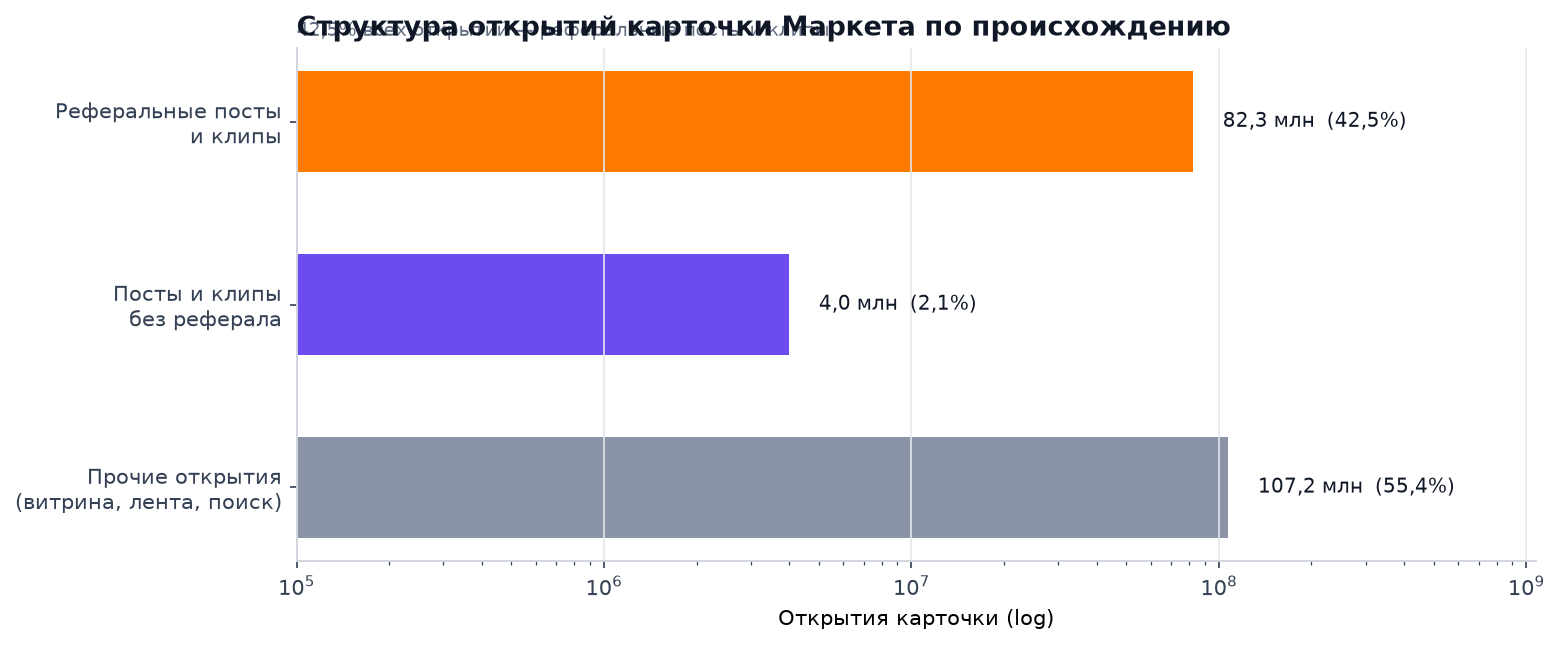

In [33]:
# --- Из чего состоят открытия карточки --------------------------------------
other_opens = OPEN_VK - POST_OPENS
ref_other = POST_OPENS - REF_OPENS
parts = pd.Series({
    'Реферальные посты\nи клипы': REF_OPENS,
    'Посты и клипы\nбез реферала': ref_other,
    'Прочие открытия\n(витрина, лента, поиск)': other_opens,
})

fig, ax = plt.subplots(figsize=(10.5, 4.4))
bars = ax.barh(parts.index[::-1], parts.values[::-1], color=[C_GRAY, C_ACC, C_PT], height=0.55)
ax.set_xscale('log')
ax.set_xlabel('Открытия карточки (log)')
ax.set_title('Структура открытий карточки Маркета по происхождению')
subtitle(ax, '42,5% всех открытий — реферальные посты и клипы')
for b, v in zip(bars, parts.values[::-1]):
    ax.text(v*1.25, b.get_y()+b.get_height()/2,
            f'{fnum(v,1)}  ({v/OPEN_VK*100:.1f}%)'.replace('.', ','),
            va='center', fontsize=9.5)
ax.set_xlim(1e5, parts.max()*10)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к структуре открытий.** Три категории происхождения открытий карточки, логарифмическая шкала. Реферальные посты и клипы — 82,3 млн (42,5%), посты и клипы без реферала — 3,9 млн (2,0%), прочие каналы (витрина, лента, поиск, главная) — 107,3 млн (55,5%). Формально «прочие» больше, но если объединить весь контент — 44,6%. Главное: **реферальный контент — крупнейший единый источник**, сопоставимый со всеми остальными вместе. Это и есть социальная коммерция в действии.

## 3. Таблица 3 «Маркет ВКонтакте — по дням»: динамика сентября

30 дней наблюдений позволяют проверить устойчивость средних, увидеть недельный цикл и оценить, растёт ли Маркет внутри месяца. Все ряды агрегированы по дням.

### 3.1. Подготовка дневных данных

In [34]:
# --- Подготовка дневных данных ----------------------------------------------
day = day.sort_values('Дата').reset_index(drop=True)
DN = ['Пн','Вт','Ср','Чт','Пт','Сб','Вс']
day['День недели'] = day['Дата'].dt.weekday.map(dict(enumerate(DN)))
day['CR_VK'] = day['Заказы: Маркет Вконтакте'] / day['Открытия карточки: Маркет Вконтакте'] * 100
day['CR_PT'] = day['Заказы: Партнёр 1'] / day['Открытия карточки: Партнёр 1'] * 100
day['AOV_VK'] = day['GMV, ₽: Маркет Вконтакте'] / day['Заказы: Маркет Вконтакте']
day['AOV_PT'] = day['GMV, ₽: Партнёр 1'] / day['Заказы: Партнёр 1']
day['PAID_SHARE'] = day['Оплаченные заказы: Маркет Вконтакте'] / day['Заказы: Маркет Вконтакте'] * 100
day['GMV_cum_VK'] = day['GMV, ₽: Маркет Вконтакте'].cumsum()
day['GMV_cum_PT'] = day['GMV, ₽: Партнёр 1'].cumsum()
day['CR_search'] = day['Поисковые запросы с открытием карточки'] / day['Поисковые запросы'] * 100

display(day[['Дата','DAU Маркета Вконтакте','Показы товаров: Маркет Вконтакте','Заказы: Маркет Вконтакте',
             'GMV, ₽: Маркет Вконтакте','CR_VK','AOV_VK']].head(5).round(2))
print('Период:', day['Дата'].min().date(), '—', day['Дата'].max().date(), '| дней:', len(day))

,Дата,DAU Маркета Вконтакте,Показы товаров: Маркет Вконтакте,Заказы: Маркет Вконтакте,"GMV, ₽: Маркет Вконтакте",CR_VK,AOV_VK
0,2026-09-01,128656,164388078,20370,66555585,0.34,3267.33
1,2026-09-02,121217,160332304,12687,49599901,0.21,3909.51
2,2026-09-03,125152,163016247,13428,56951176,0.22,4241.23
3,2026-09-04,127084,168725840,15366,52908793,0.24,3443.24
4,2026-09-05,120908,155051855,15191,53443710,0.24,3518.12


Период: 2026-09-01 — 2026-09-30 | дней: 30


**Легенда к подготовке.** Показаны первые пять дней и вычисленные поля: `CR_VK` (конверсия открытие → заказ), `AOV_VK` (средний чек), `PAID_SHARE` (доля оплаченных), накопительный GMV. Эти производные используются во всех графиках раздела. Проверка периода: 1–30 сентября 2026, 30 наблюдений, пропусков нет.

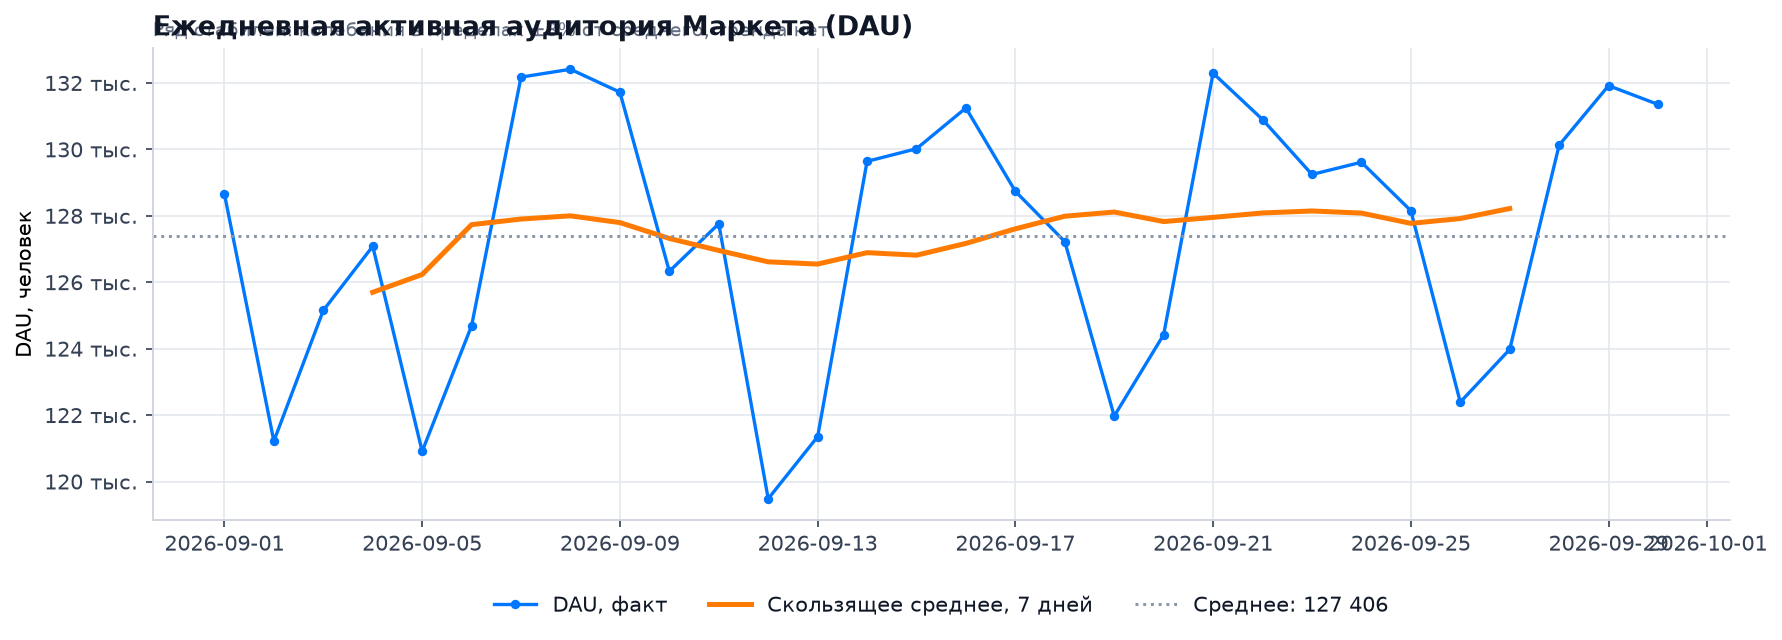

Мин/макс DAU: 119482 / 132413
Коэффициент вариации: 3,1%


In [35]:
# --- DAU ---------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(day['Дата'], day['DAU Маркета Вконтакте'], color=C_VK, lw=1.6, marker='o', ms=3.5, label='DAU, факт')
ax.plot(day['Дата'], day['DAU Маркета Вконтакте'].rolling(7, center=True).mean(),
        color=C_PT, lw=2.4, label='Скользящее среднее, 7 дней')
ax.axhline(day['DAU Маркета Вконтакте'].mean(), color=C_GRAY, ls=':', lw=1.4,
           label=f'Среднее: {day["DAU Маркета Вконтакте"].mean():,.0f}'.replace(',', ' '))
ax.set_ylabel('DAU, человек')
ax.set_title('Ежедневная активная аудитория Маркета (DAU)')
subtitle(ax, 'Ряд стабилен: колебания в пределах ±8% от среднего, тренда нет')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.12))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{v/1000:.0f} тыс.'))
plt.tight_layout()
plt.show()

print('Мин/макс DAU:', int(day['DAU Маркета Вконтакте'].min()), '/', int(day['DAU Маркета Вконтакте'].max()))
print('Коэффициент вариации:', fpct(day['DAU Маркета Вконтакте'].std()/day['DAU Маркета Вконтакте'].mean()*100))

**Легенда к DAU.** Синяя линия — факт по дням, оранжевая — скользящее среднее за 7 дней, пунктир — среднее за месяц. Ось Y в тысячах человек. DAU колеблется в коридоре примерно 119–132 тыс., среднее — 127,4 тыс., коэффициент вариации низкий. Скользящая линия почти горизонтальна: **внутри месяца Маркет не растёт и не падает**, он живёт в стабильном режиме. Это важно для прогнозов: месячные средние можно экстраполировать, но органического роста из данных не видно.

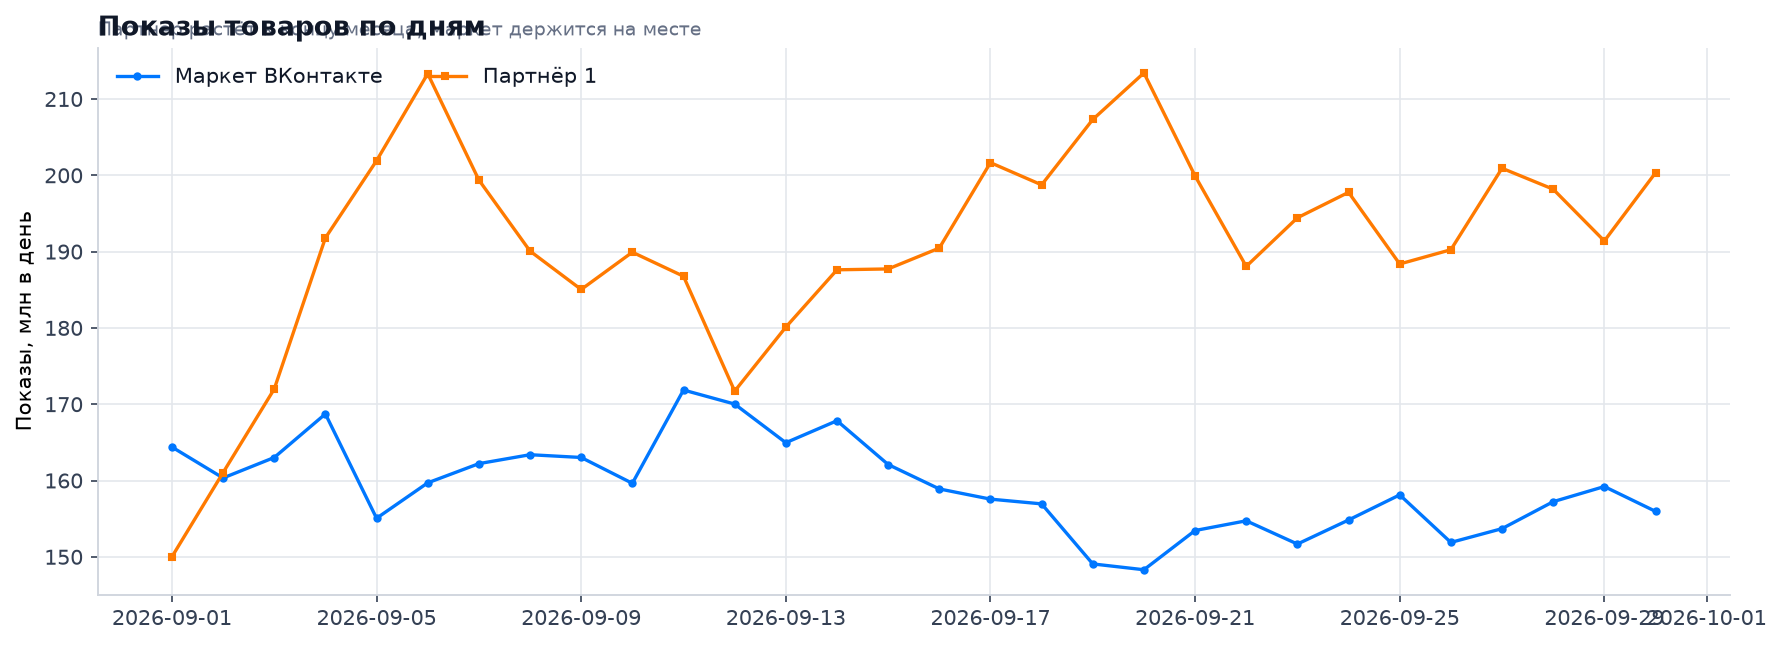

Средние показы в день — Маркет: 159,3 млн | Партнёр: 191,0 млн
Тренд (наклон линейной регрессии, млн/день) — Маркет: -0.394 | Партнёр: 0.721


In [36]:
# --- Показы ------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(day['Дата'], day['Показы товаров: Маркет Вконтакте']/1e6, color=C_VK, lw=1.6, marker='o', ms=3, label='Маркет ВКонтакте')
ax.plot(day['Дата'], day['Показы товаров: Партнёр 1']/1e6, color=C_PT, lw=1.6, marker='s', ms=3, label='Партнёр 1')
ax.set_ylabel('Показы, млн в день')
ax.set_title('Показы товаров по дням')
subtitle(ax, 'Партнёр растёт к концу месяца, Маркет держится на месте')
ax.legend(ncol=2, loc='upper left')
plt.tight_layout()
plt.show()

print('Средние показы в день — Маркет:', fnum(day['Показы товаров: Маркет Вконтакте'].mean(),1),
      '| Партнёр:', fnum(day['Показы товаров: Партнёр 1'].mean(),1))
print('Тренд (наклон линейной регрессии, млн/день) — Маркет:',
      round(np.polyfit(range(len(day)), day['Показы товаров: Маркет Вконтакте']/1e6, 1)[0], 3),
      '| Партнёр:', round(np.polyfit(range(len(day)), day['Показы товаров: Партнёр 1']/1e6, 1)[0], 3))

**Легенда к показам.** Две линии: синяя — Маркет, оранжевая — Партнёр, по дням сентября, в млн показов. У Маркета коридор 148–172 млн в день без выраженного тренда. У Партнёра — от 150 млн в начале до 200–213 млн во второй половине; линейный тренд положительный. То есть **инвентарь показов перетекает к Партнёру**: витрина ВКонтакте всё активнее показывает товары внешнего маркетплейса, а собственные показы остаются стабильными.

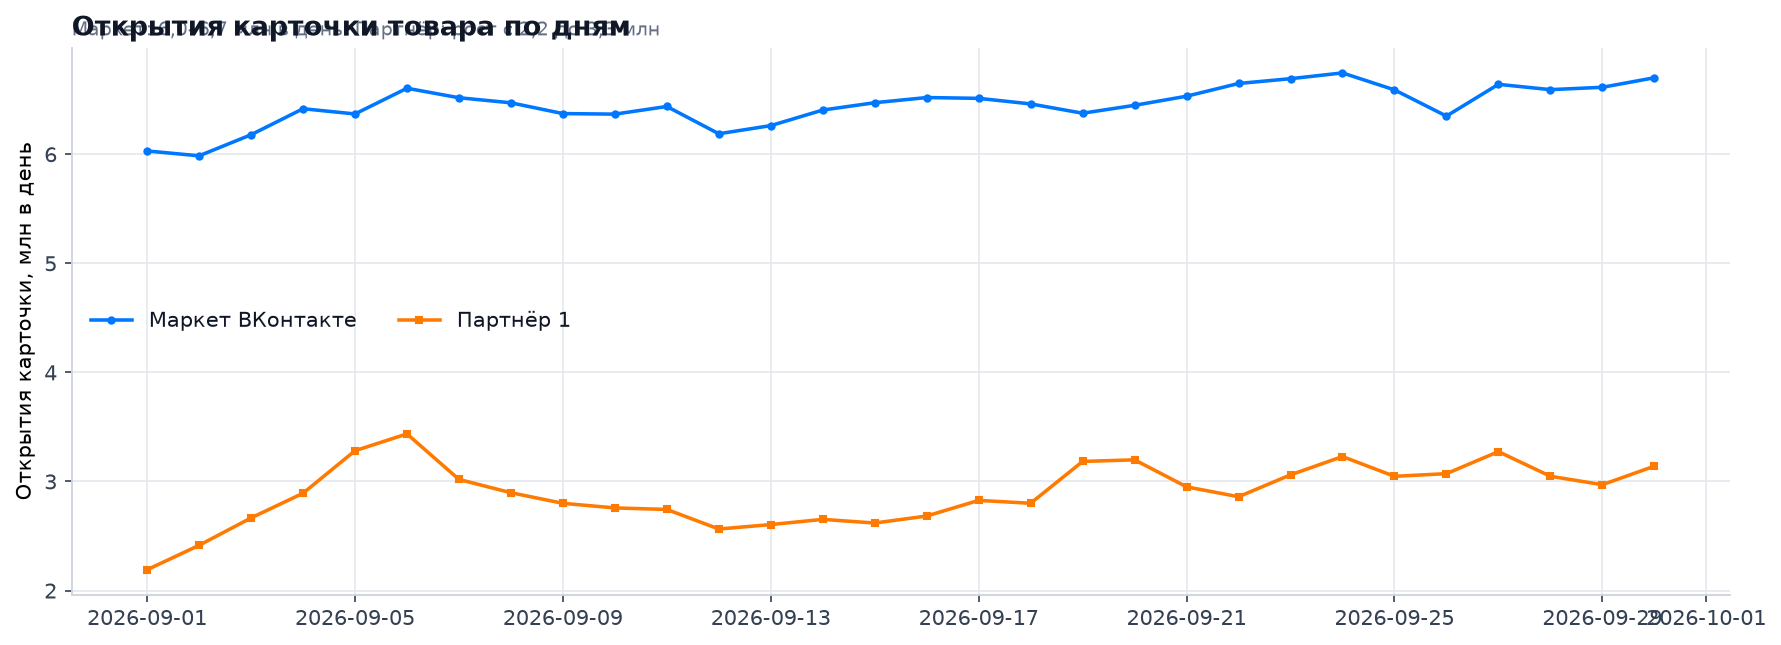

Средние открытия — Маркет: 6,45 млн | Партнёр: 2,90 млн
Рост Партнёра за месяц: 15,3%


In [37]:
# --- Открытия карточки -------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(day['Дата'], day['Открытия карточки: Маркет Вконтакте']/1e6, color=C_VK, lw=1.7, marker='o', ms=3, label='Маркет ВКонтакте')
ax.plot(day['Дата'], day['Открытия карточки: Партнёр 1']/1e6, color=C_PT, lw=1.7, marker='s', ms=3, label='Партнёр 1')
ax.set_ylabel('Открытия карточки, млн в день')
ax.set_title('Открытия карточки товара по дням')
subtitle(ax, 'Маркет: 6,0–6,7 млн в день. Партнёр: рост с 2,2 до 3,3 млн')
ax.legend(ncol=2, loc='center left')
plt.tight_layout()
plt.show()

print('Средние открытия — Маркет:', fnum(day['Открытия карточки: Маркет Вконтакте'].mean(),2),
      '| Партнёр:', fnum(day['Открытия карточки: Партнёр 1'].mean(),2))
print('Рост Партнёра за месяц:',
      fpct((day['Открытия карточки: Партнёр 1'].tail(5).mean()/day['Открытия карточки: Партнёр 1'].head(5).mean()-1)*100))

**Легенда к открытиям.** Те же две линии, но по открытиям карточки. Маркет держится в узком коридоре 6,0–6,7 млн в день. Партнёр начинает с 2,2 млн и заканчивает 3,1–3,4 млн; средний уровень последних пяти дней на 15,3% выше первых пяти. Вывод: **разрыв в открытиях сокращается**, хотя Маркет всё ещё впереди. Если тренд сохранится, через несколько месяцев Партнёр сравняется с Маркетом по глубине просмотра.

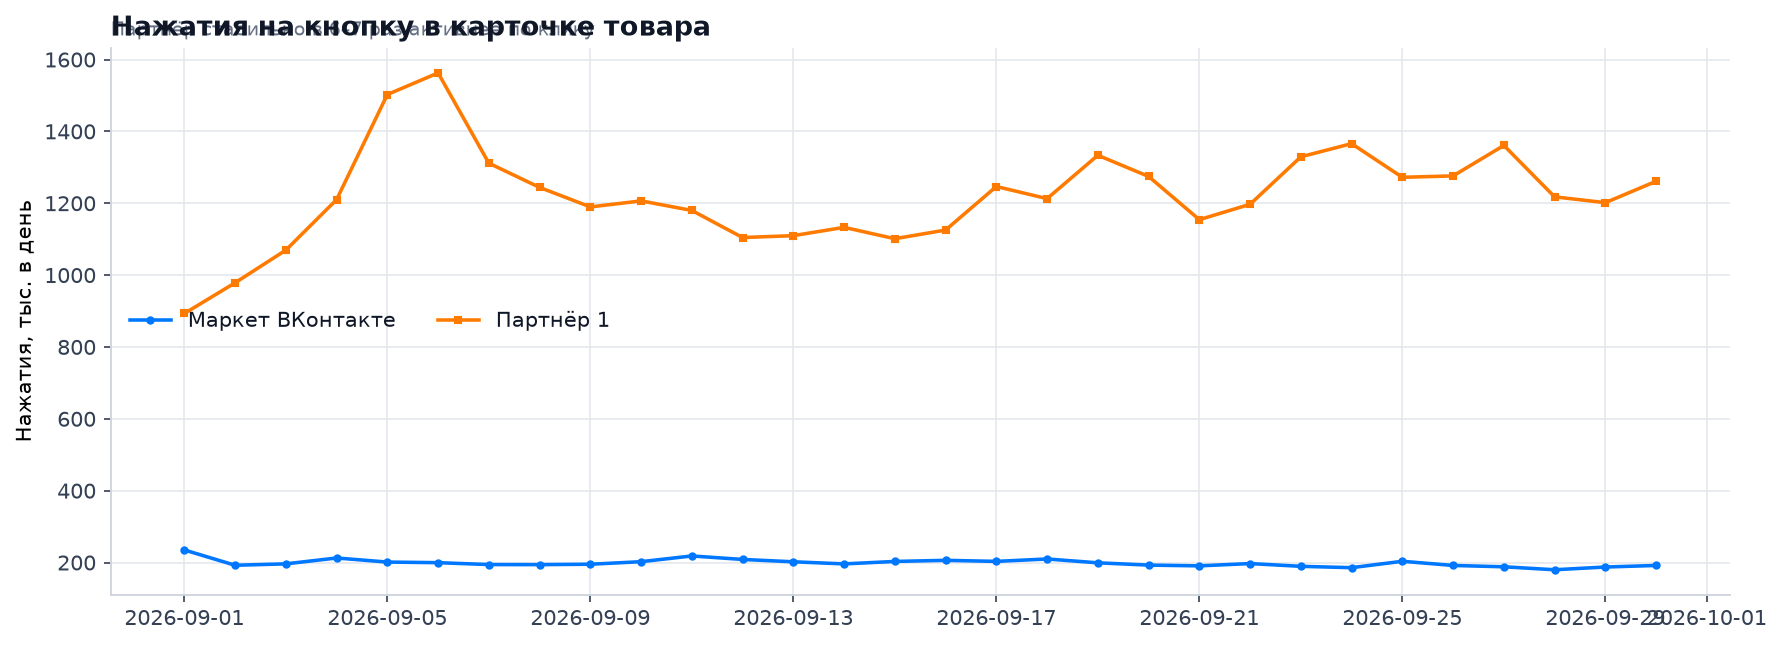

Средние нажатия — Маркет: 198 969 | Партнёр: 1 220 869
Отношение Партнёр/Маркет: 6.14


In [38]:
# --- Нажатия на кнопку -------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(day['Дата'], day['Нажатия на кнопку: Маркет Вконтакте']/1e3, color=C_VK, lw=1.7, marker='o', ms=3, label='Маркет ВКонтакте')
ax.plot(day['Дата'], day['Нажатия на кнопку: Партнёр 1']/1e3, color=C_PT, lw=1.7, marker='s', ms=3, label='Партнёр 1')
ax.set_ylabel('Нажатия, тыс. в день')
ax.set_title('Нажатия на кнопку в карточке товара')
subtitle(ax, 'Партнёр стабильно в 6–7 раз активнее по клику')
ax.legend(ncol=2, loc='center left')
plt.tight_layout()
plt.show()

print('Средние нажатия — Маркет:', f"{day['Нажатия на кнопку: Маркет Вконтакте'].mean():,.0f}".replace(',', ' '),
      '| Партнёр:', f"{day['Нажатия на кнопку: Партнёр 1'].mean():,.0f}".replace(',', ' '))
print('Отношение Партнёр/Маркет:', round(day['Нажатия на кнопку: Партнёр 1'].mean()/day['Нажатия на кнопку: Маркет Вконтакте'].mean(),2))

**Легенда к нажатиям.** Ось Y — тысячи нажатий в день. Синяя линия Маркета — около 180–235 тыс., оранжевая Партнёра — 0,9–1,6 млн. Отношение стабильно 6–7 раз в пользу Партнёра. Обратите внимание на синхронность: всплески и провалы у обоих сегментов часто совпадают — значит, на клик влияет общий трафик ВКонтакте (будни/выходные, события), а не только внутренняя механика сегмента.

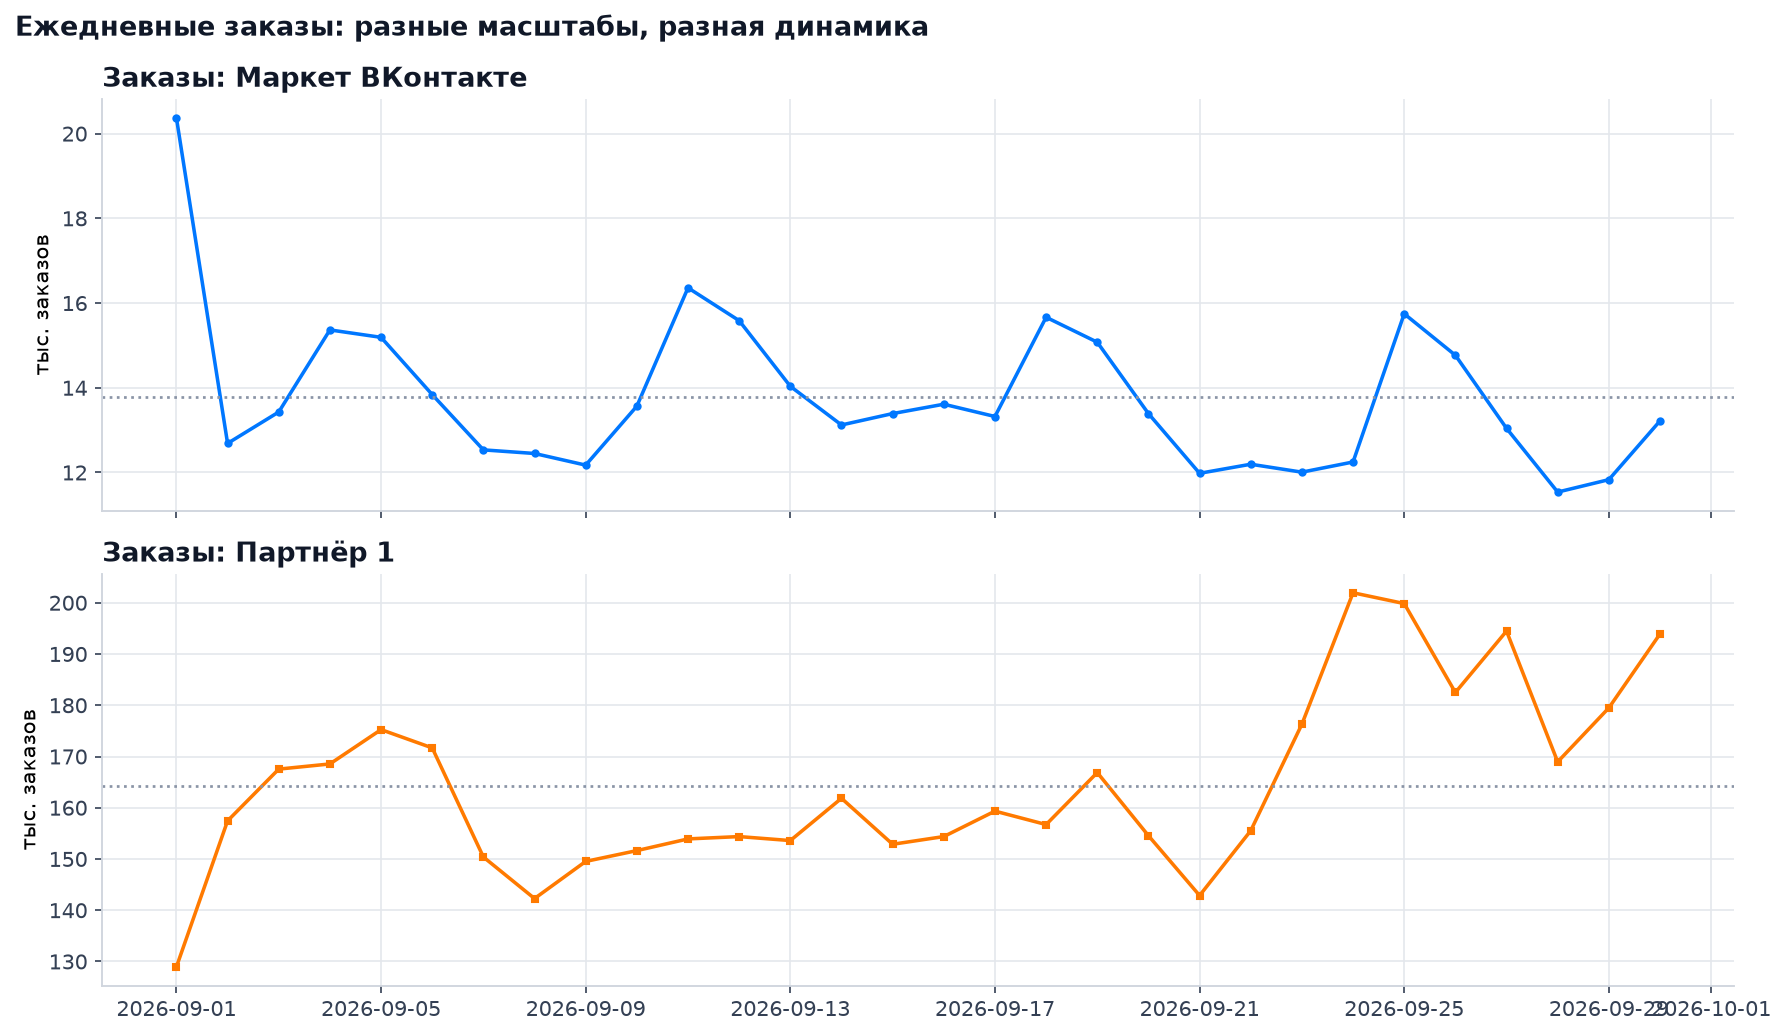

Средние заказы/день — Маркет: 13791.0 | Партнёр: 164251.0
Последняя неделя vs первая — Маркет: -10,7% | Партнёр: 18,0%


In [39]:
# --- Заказы: две панели ------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(day['Дата'], day['Заказы: Маркет Вконтакте']/1e3, color=C_VK, lw=1.7, marker='o', ms=3)
axes[0].set_ylabel('тыс. заказов')
axes[0].set_title('Заказы: Маркет ВКонтакте')
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{v:.0f}'))
axes[0].axhline(day['Заказы: Маркет Вконтакте'].mean()/1e3, color=C_GRAY, ls=':', lw=1.3)
axes[1].plot(day['Дата'], day['Заказы: Партнёр 1']/1e3, color=C_PT, lw=1.7, marker='s', ms=3)
axes[1].set_ylabel('тыс. заказов')
axes[1].set_title('Заказы: Партнёр 1')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{v:.0f}'))
axes[1].axhline(day['Заказы: Партнёр 1'].mean()/1e3, color=C_GRAY, ls=':', lw=1.3)
fig.suptitle('Ежедневные заказы: разные масштабы, разная динамика', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

print('Средние заказы/день — Маркет:', round(day['Заказы: Маркет Вконтакте'].mean(),0),
      '| Партнёр:', round(day['Заказы: Партнёр 1'].mean(),0))
print('Последняя неделя vs первая — Маркет:',
      fpct((day['Заказы: Маркет Вконтакте'].tail(7).mean()/day['Заказы: Маркет Вконтакте'].head(7).mean()-1)*100),
      '| Партнёр:', fpct((day['Заказы: Партнёр 1'].tail(7).mean()/day['Заказы: Партнёр 1'].head(7).mean()-1)*100))

**Легенда к заказам.** Две панели с общей осью времени: сверху Маркет, снизу Партнёр, обе в тысячах заказов. Масштабы разные: Маркет — 11,5–20,4 тыс. в день, Партнёр — 129–202 тыс. Пунктир — среднее. У Маркета пики приходятся на отдельные дни, у Партнёра — устойчивый рост во второй половине месяца. Сравнение последней и первой недели: Маркет −10,7%, Партнёр +18,0%. **Динамика роста сосредоточена в партнёрском сегменте.**

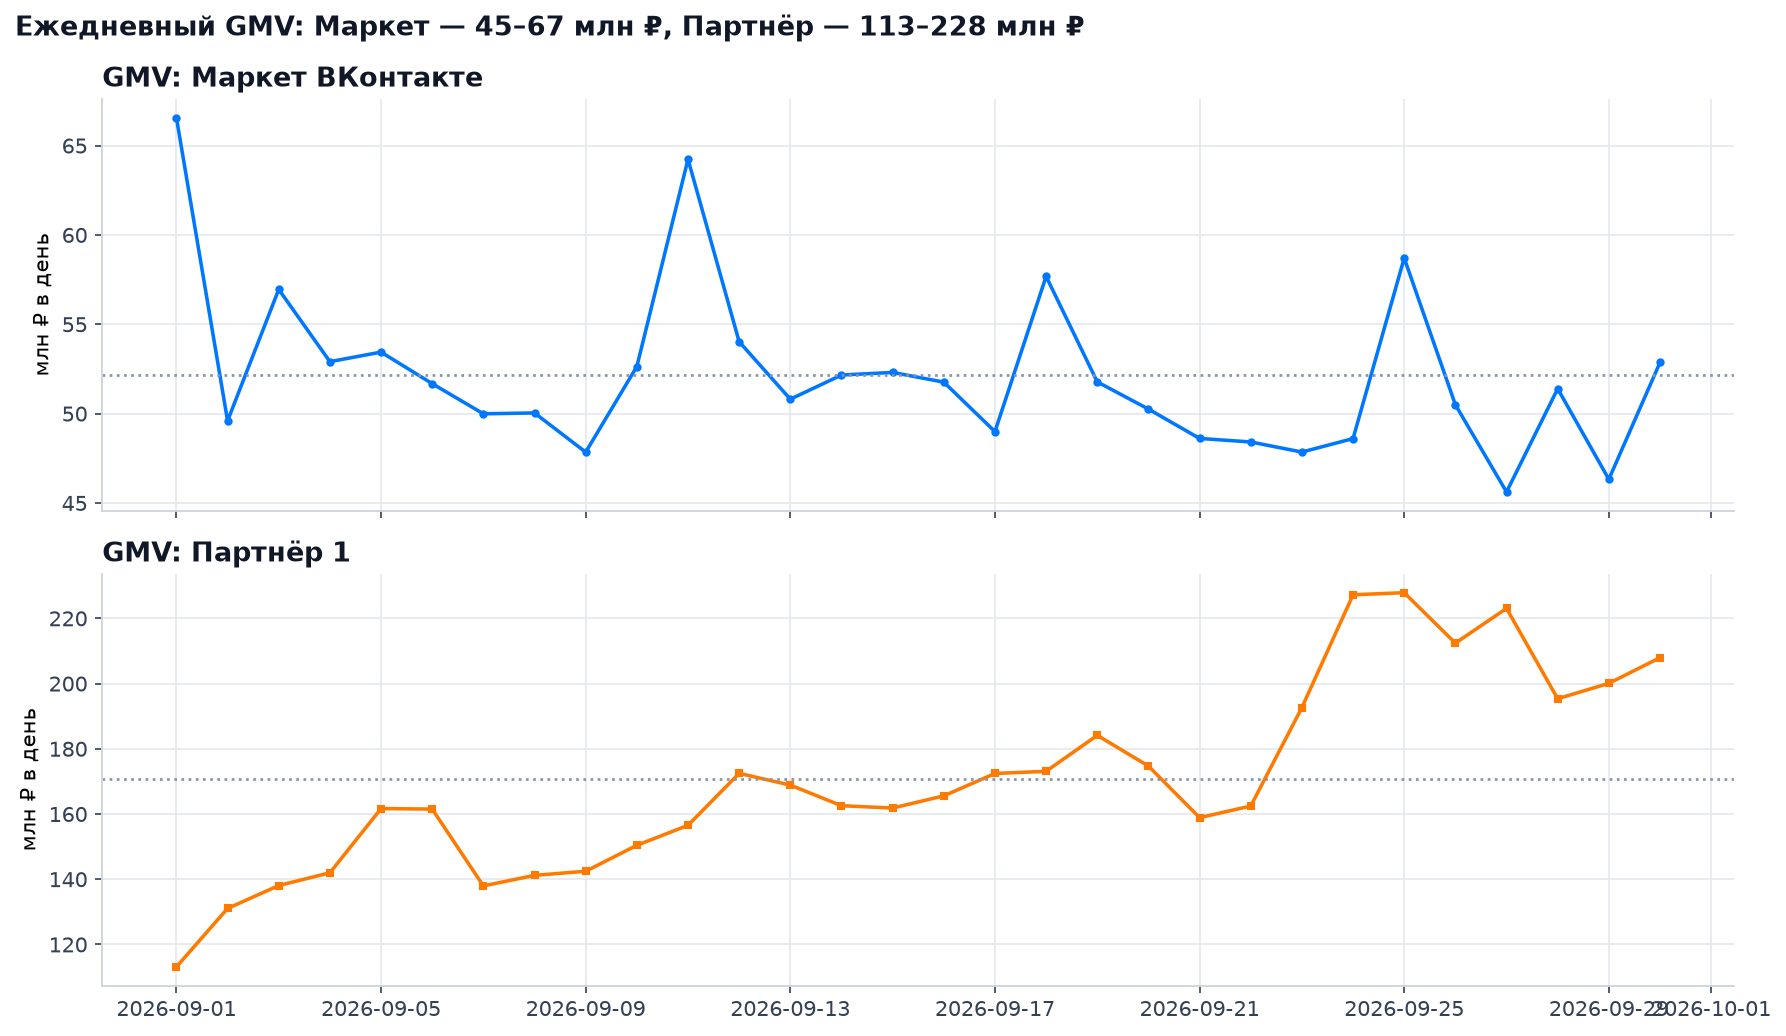

Средний GMV/день — Маркет: 52,2 млн ₽ | Партнёр: 170,7 млн ₽


In [40]:
# --- GMV: две панели ---------------------------------------------------------
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(day['Дата'], day['GMV, ₽: Маркет Вконтакте']/1e6, color=C_VK, lw=1.7, marker='o', ms=3)
axes[0].set_ylabel('млн ₽ в день')
axes[0].set_title('GMV: Маркет ВКонтакте')
axes[0].axhline(day['GMV, ₽: Маркет Вконтакте'].mean()/1e6, color=C_GRAY, ls=':', lw=1.3)
axes[1].plot(day['Дата'], day['GMV, ₽: Партнёр 1']/1e6, color=C_PT, lw=1.7, marker='s', ms=3)
axes[1].set_ylabel('млн ₽ в день')
axes[1].set_title('GMV: Партнёр 1')
axes[1].axhline(day['GMV, ₽: Партнёр 1'].mean()/1e6, color=C_GRAY, ls=':', lw=1.3)
fig.suptitle('Ежедневный GMV: Маркет — 45–67 млн ₽, Партнёр — 113–228 млн ₽', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

print('Средний GMV/день — Маркет:', fmoney(day['GMV, ₽: Маркет Вконтакте'].mean(),1),
      '| Партнёр:', fmoney(day['GMV, ₽: Партнёр 1'].mean(),1))

**Легенда к GMV.** Две панели, млн ₽ в день. Маркет: 45–67 млн ₽, среднее около 52 млн. Партнёр: от 113 млн в начале до 227 млн в конце, среднее около 171 млн, выраженный восходящий тренд. К концу месяца дневной GMV Партнёра в 4–5 раз превышает GMV Маркета. Это ключевой аргумент: **деньги в экосистеме делает партнёрская модель**, а Маркет остаётся витриной с высоким чеком, но небольшим оборотом.

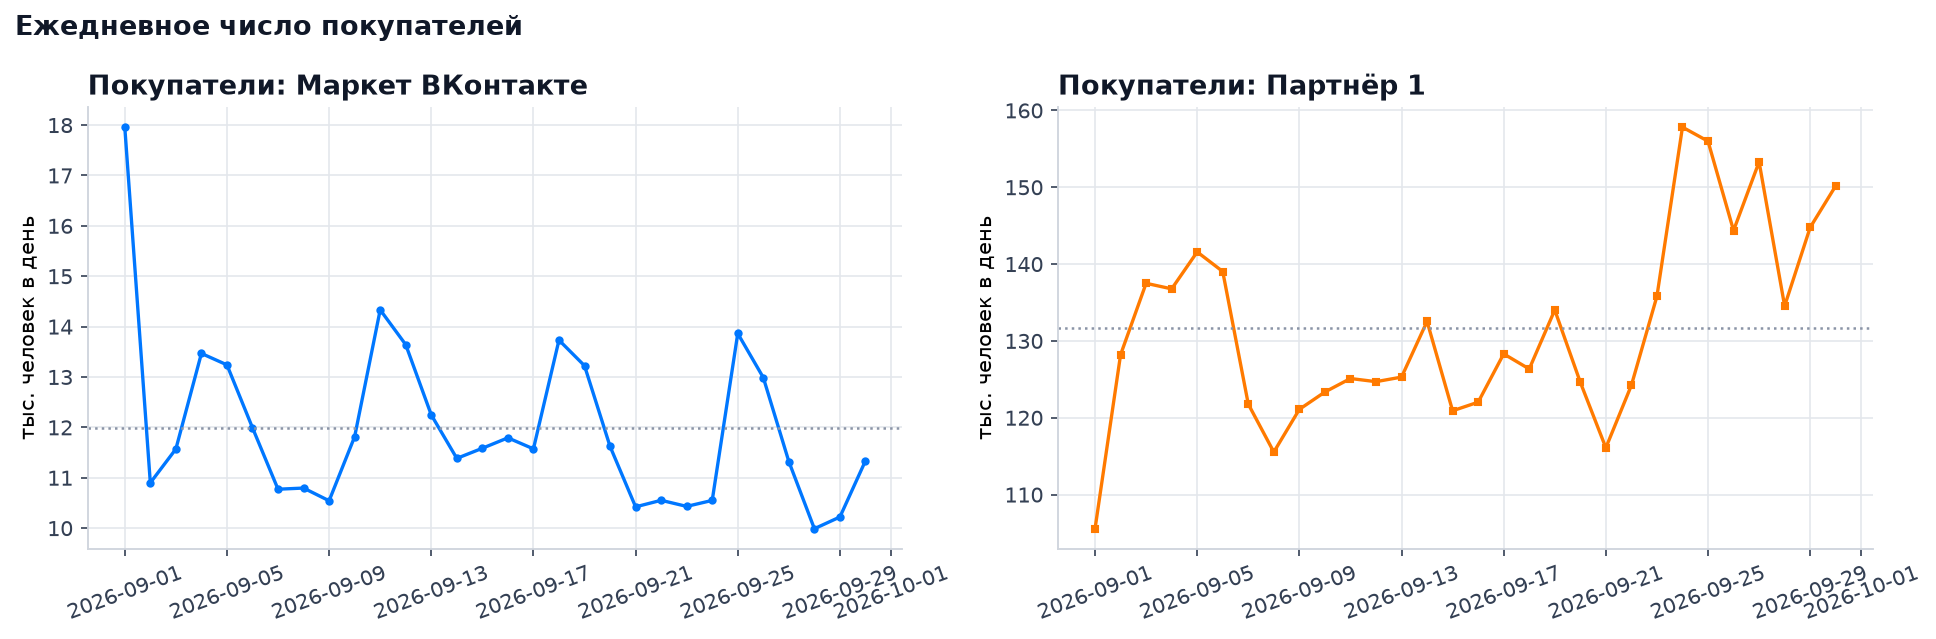

Среднее покупателей/день — Маркет: 11996.0 | Партнёр: 131716.0


In [41]:
# --- Покупатели --------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharex=True)
axes[0].plot(day['Дата'], day['Покупатели: Маркет Вконтакте']/1e3, color=C_VK, lw=1.6, marker='o', ms=3)
axes[0].set_title('Покупатели: Маркет ВКонтакте')
axes[0].set_ylabel('тыс. человек в день')
axes[0].axhline(day['Покупатели: Маркет Вконтакте'].mean()/1e3, color=C_GRAY, ls=':', lw=1.2)
axes[1].plot(day['Дата'], day['Покупатели: Партнёр 1']/1e3, color=C_PT, lw=1.6, marker='s', ms=3)
axes[1].set_title('Покупатели: Партнёр 1')
axes[1].set_ylabel('тыс. человек в день')
axes[1].axhline(day['Покупатели: Партнёр 1'].mean()/1e3, color=C_GRAY, ls=':', lw=1.2)
fig.suptitle('Ежедневное число покупателей', fontsize=13, fontweight='bold', x=0.01, ha='left')
for ax in axes:
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

print('Среднее покупателей/день — Маркет:', round(day['Покупатели: Маркет Вконтакте'].mean(),0),
      '| Партнёр:', round(day['Покупатели: Партнёр 1'].mean(),0))

**Легенда к покупателям.** Две панели, тыс. человек в день. Маркет — 10–18 тыс., Партнёр — 106–158 тыс. Обе линии колеблются синхронно в недельном ритме: просадки в начале недели, подъём к выходным. Пунктир — среднее. Отношение примерно 1:10. Это ещё раз подтверждает: **покупательская масса сконцентрирована в Партнёре**, а Маркет обслуживает нишевый спрос.

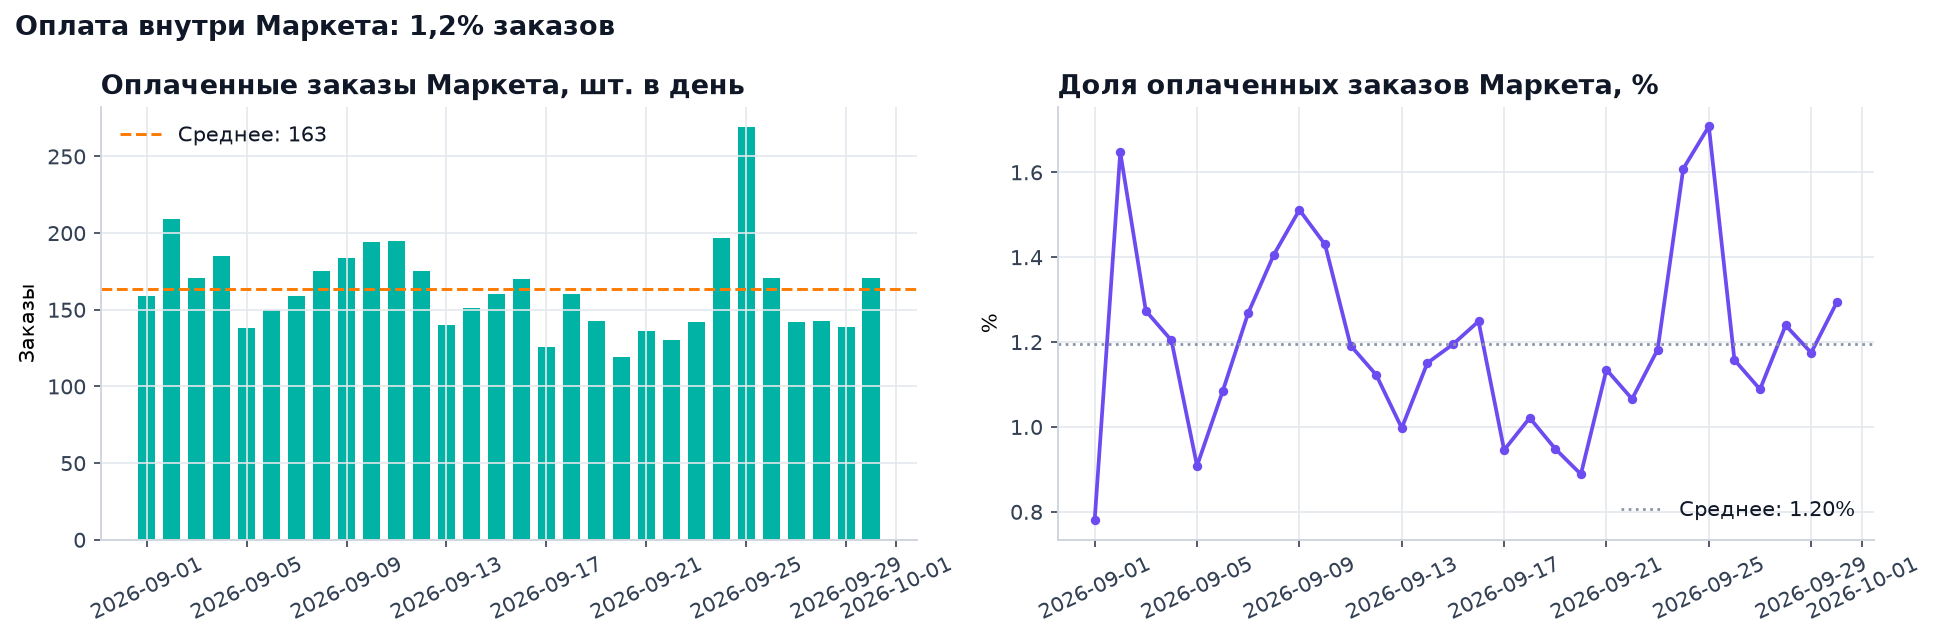

Всего оплачено: 4903 из 413740 = 1,19%


In [42]:
# --- Оплаченные заказы и доля оплаты ----------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].bar(day['Дата'], day['Оплаченные заказы: Маркет Вконтакте'], color=C_TEAL, width=0.7)
axes[0].set_title('Оплаченные заказы Маркета, шт. в день')
axes[0].set_ylabel('Заказы')
axes[0].tick_params(axis='x', rotation=25)
axes[0].axhline(day['Оплаченные заказы: Маркет Вконтакте'].mean(), color=C_PT, ls='--', lw=1.4,
                label=f'Среднее: {day["Оплаченные заказы: Маркет Вконтакте"].mean():.0f}')
axes[0].legend()
axes[1].plot(day['Дата'], day['PAID_SHARE'], color=C_ACC, lw=1.8, marker='o', ms=3.5)
axes[1].set_title('Доля оплаченных заказов Маркета, %')
axes[1].set_ylabel('%')
axes[1].tick_params(axis='x', rotation=25)
axes[1].axhline(day['PAID_SHARE'].mean(), color=C_GRAY, ls=':', lw=1.3,
                label=f'Среднее: {day["PAID_SHARE"].mean():.2f}%')
axes[1].legend()
fig.suptitle('Оплата внутри Маркета: 1,2% заказов', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

print('Всего оплачено:', int(day['Оплаченные заказы: Маркет Вконтакте'].sum()),
      'из', int(day['Заказы: Маркет Вконтакте'].sum()), '=', fpct(PAID_SHARE_VK,2))

**Легенда к оплате.** Слева — абсолютное число оплаченных заказов Маркета по дням, справа — их доля в оформленных заказах. Среднее — около 163 оплат в день, доля — 1,2%. Пики 25 сентября (269) и 2 сентября (209) не меняют картины. Ключевой вывод: **чекаут Маркета почти не используется для оплаты онлайн** — 98,8% оформленных заказов не оплачиваются внутри платформы (оплата при получении, переход на сторонний сайт или отмена). Это ограничение транзакционной модели.

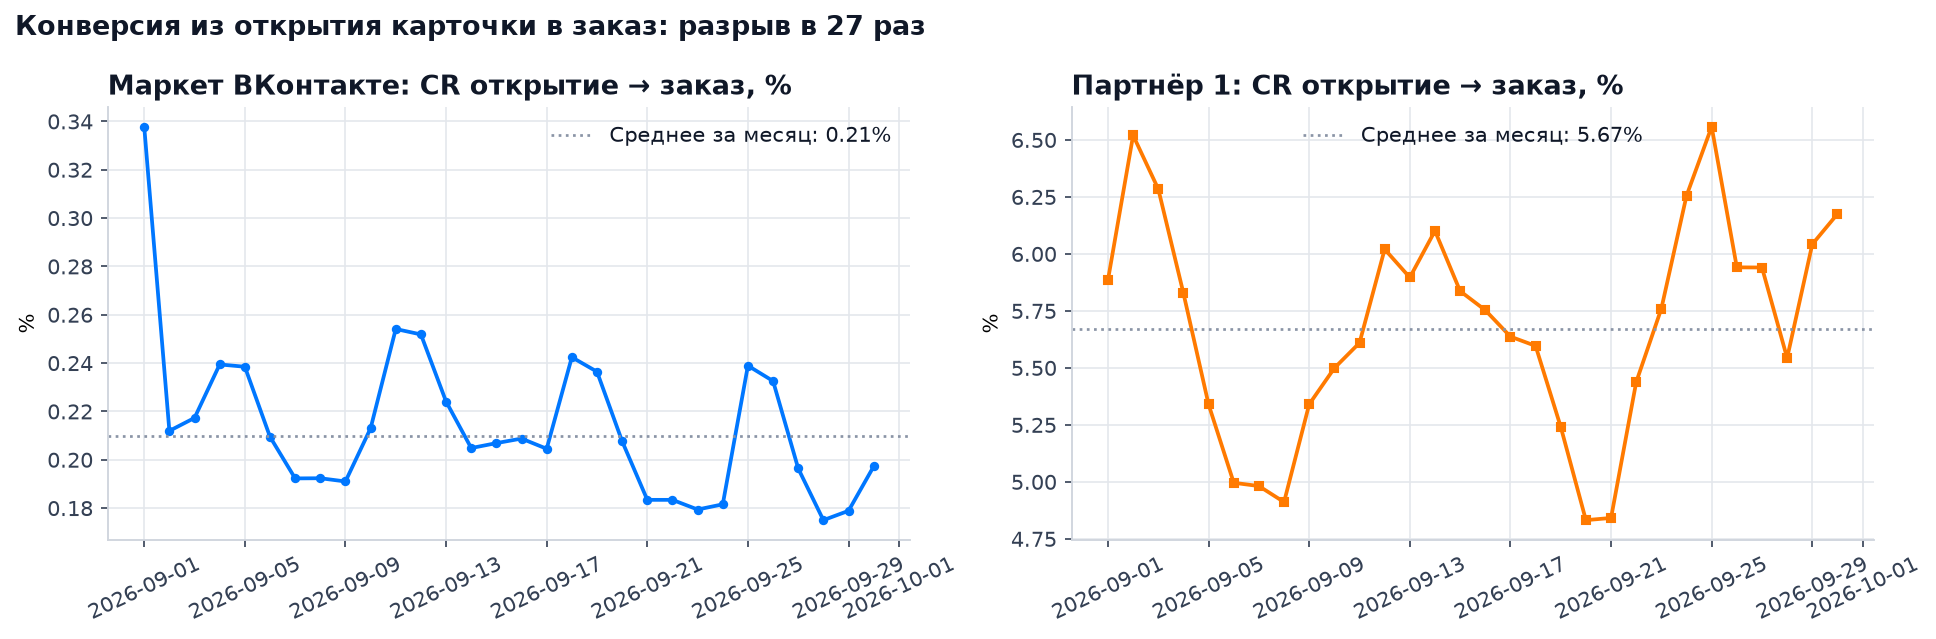

CR открытие→заказ — Маркет: мин 0.175 макс 0.338
CR открытие→заказ — Партнёр: мин 4.83 макс 6.56


In [43]:
# --- Конверсия открытие → заказ ---------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharex=True)
axes[0].plot(day['Дата'], day['CR_VK'], color=C_VK, lw=1.8, marker='o', ms=3.5)
axes[0].set_title('Маркет ВКонтакте: CR открытие → заказ, %')
axes[0].set_ylabel('%')
axes[0].axhline(CR2_VK, color=C_GRAY, ls=':', lw=1.3, label=f'Среднее за месяц: {CR2_VK:.2f}%')
axes[0].legend()
axes[1].plot(day['Дата'], day['CR_PT'], color=C_PT, lw=1.8, marker='s', ms=3.5)
axes[1].set_title('Партнёр 1: CR открытие → заказ, %')
axes[1].set_ylabel('%')
axes[1].axhline(CR2_PT, color=C_GRAY, ls=':', lw=1.3, label=f'Среднее за месяц: {CR2_PT:.2f}%')
axes[1].legend()
for ax in axes: ax.tick_params(axis='x', rotation=25)
fig.suptitle('Конверсия из открытия карточки в заказ: разрыв в 27 раз', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

print('CR открытие→заказ — Маркет: мин', round(day['CR_VK'].min(),3), 'макс', round(day['CR_VK'].max(),3))
print('CR открытие→заказ — Партнёр: мин', round(day['CR_PT'].min(),2), 'макс', round(day['CR_PT'].max(),2))

**Легенда к конверсии.** Две панели с одинаковой шкалой времени, но разными масштабами Y. Маркет: 0,18–0,34%, вокруг среднего 0,21%. Партнёр: 4,8–6,6%, среднее 5,67%. Разрыв стабилен **каждый день месяца** — это не разовая аномалия, а структурное свойство. Маркет не конвертирует открытие в заказ так, как это делает маркетплейс: сказываются доверие, привычка, ассортимент, доставка и сам чекаут.

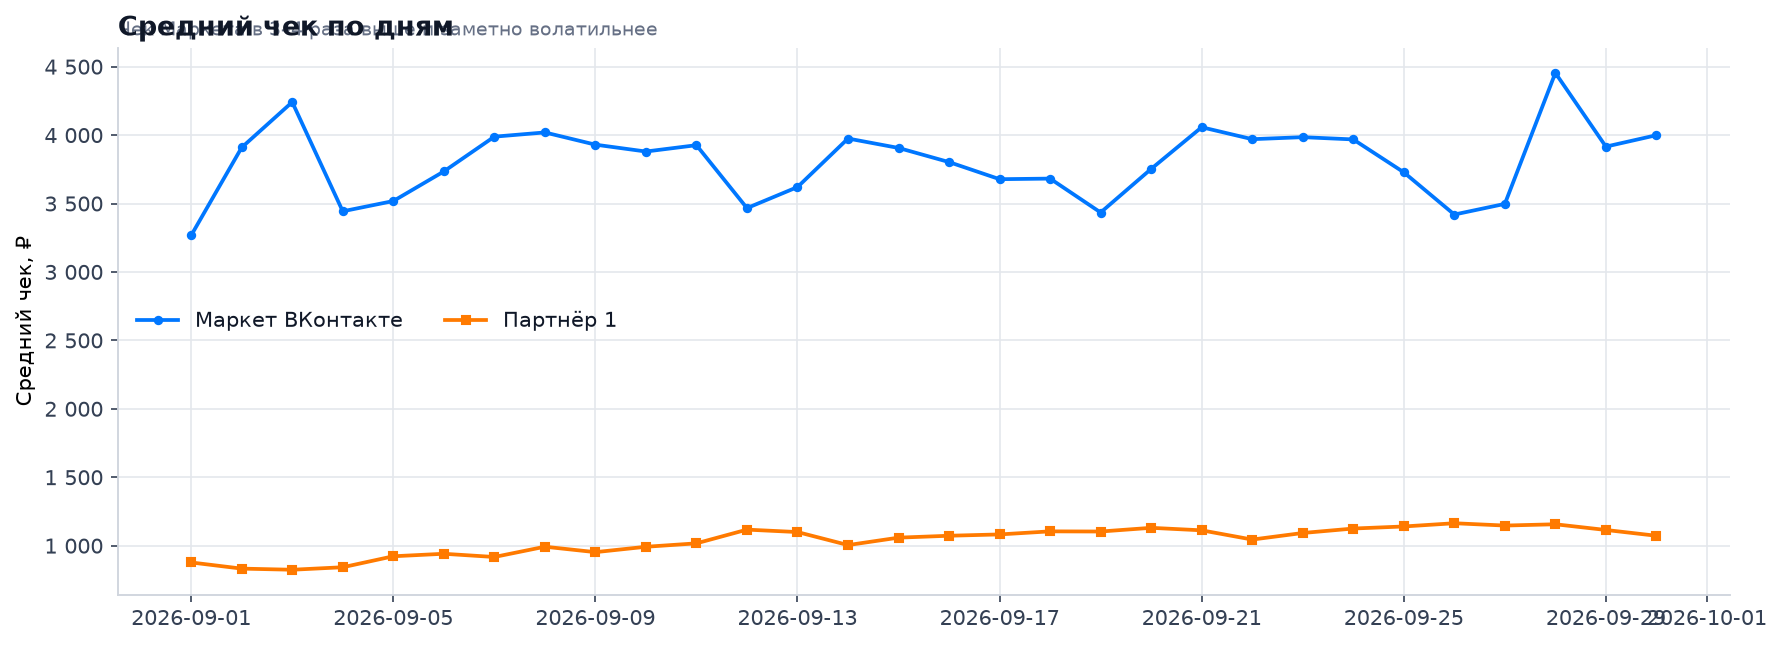

AOV Маркет: среднее 3806 | мин 3267 | макс 4454
AOV Партнёр: среднее 1035 | мин 824 | макс 1164


In [44]:
# --- Средний чек по дням -----------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(day['Дата'], day['AOV_VK'], color=C_VK, lw=1.8, marker='o', ms=3.5, label='Маркет ВКонтакте')
ax.plot(day['Дата'], day['AOV_PT'], color=C_PT, lw=1.8, marker='s', ms=3.5, label='Партнёр 1')
ax.set_ylabel('Средний чек, ₽')
ax.set_title('Средний чек по дням')
subtitle(ax, 'Чек Маркета в 3–4 раза выше и заметно волатильнее')
ax.legend(ncol=2, loc='center left')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{v:,.0f}'.replace(',', ' ')))
plt.tight_layout()
plt.show()

print('AOV Маркет: среднее', round(day['AOV_VK'].mean()),
      '| мин', round(day['AOV_VK'].min()), '| макс', round(day['AOV_VK'].max()))
print('AOV Партнёр: среднее', round(day['AOV_PT'].mean()),
      '| мин', round(day['AOV_PT'].min()), '| макс', round(day['AOV_PT'].max()))

**Легенда к среднему чеку.** Две линии, ₽. Маркет: 3 267–4 454 ₽, среднее 3 806 ₽. Партнёр: 824–1 164 ₽, среднее 1 035 ₽. У Маркета чек волатильнее — единичные дорогие заказы сильнее двигают среднее при небольшом объёме. У Партнёра чек почти плоский: масса дешёвых заказов стабилизирует среднее. Экономически это разные рынки: Маркет — техника, мебель, крупные товары; Партнёр — повседневные покупки.

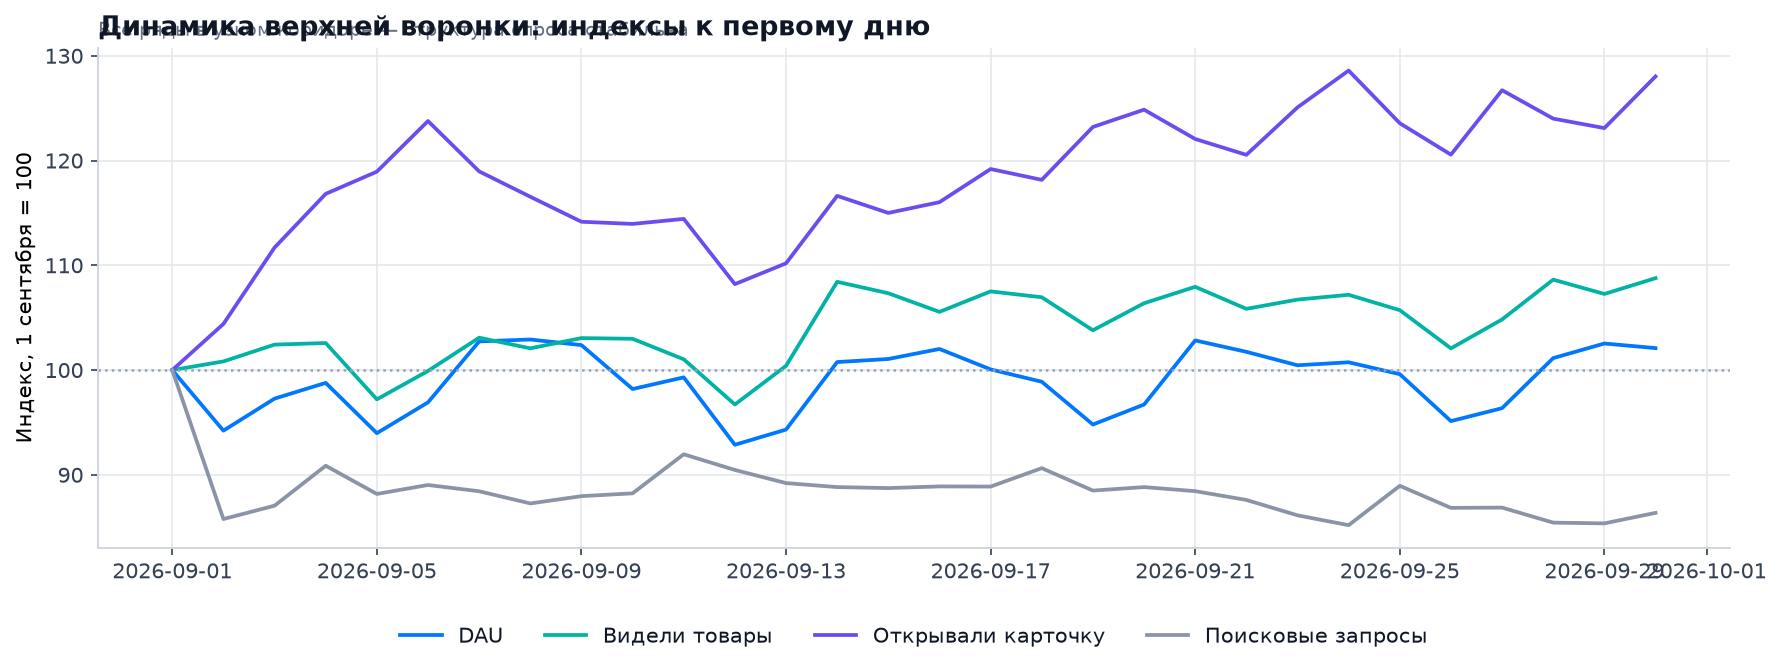

Размах индексов за месяц:
       DAU  Видели товары  Открывали карточку  Поисковые запросы
min   92.9           96.7               100.0               85.2
max  102.9          108.8               128.6              100.0


In [45]:
# --- Индекс динамики верхней воронки ----------------------------------------
idx = pd.DataFrame({
    'DAU': day['DAU Маркета Вконтакте'],
    'Видели товары': day['Видели товары (уник.)'],
    'Открывали карточку': day['Открывали карточку (уник.)'],
    'Поисковые запросы': day['Поисковые запросы'],
})
idx = idx / idx.iloc[0] * 100

fig, ax = plt.subplots(figsize=(12, 4.6))
for col, c in zip(idx.columns, [C_VK, C_TEAL, C_ACC, C_GRAY]):
    ax.plot(day['Дата'], idx[col], lw=1.8, label=col, color=c)
ax.axhline(100, color='#98A2B3', ls=':', lw=1.2)
ax.set_ylabel('Индекс, 1 сентября = 100')
ax.set_title('Динамика верхней воронки: индексы к первому дню')
subtitle(ax, 'Все ряды в узком коридоре — структура спроса стабильна')
ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(0.5, -0.12))
plt.tight_layout()
plt.show()

print('Размах индексов за месяц:')
print(idx.agg(['min','max']).round(1).to_string())

**Легенда к индексам.** Каждый ряд нормирован на своё значение 1 сентября (индекс = 100), поэтому на одном графике видны относительные изменения. Все четыре линии — DAU, видевшие товары, открывавшие карточку, поисковые запросы — держатся в коридоре примерно 85–129. Ни один канал не растёт кратно. Вывод: **верхняя воронка стабильна**, колебания носят недельный характер. Рост нижней воронки Партнёра — результат не роста трафика, а лучшей монетизации того же трафика.

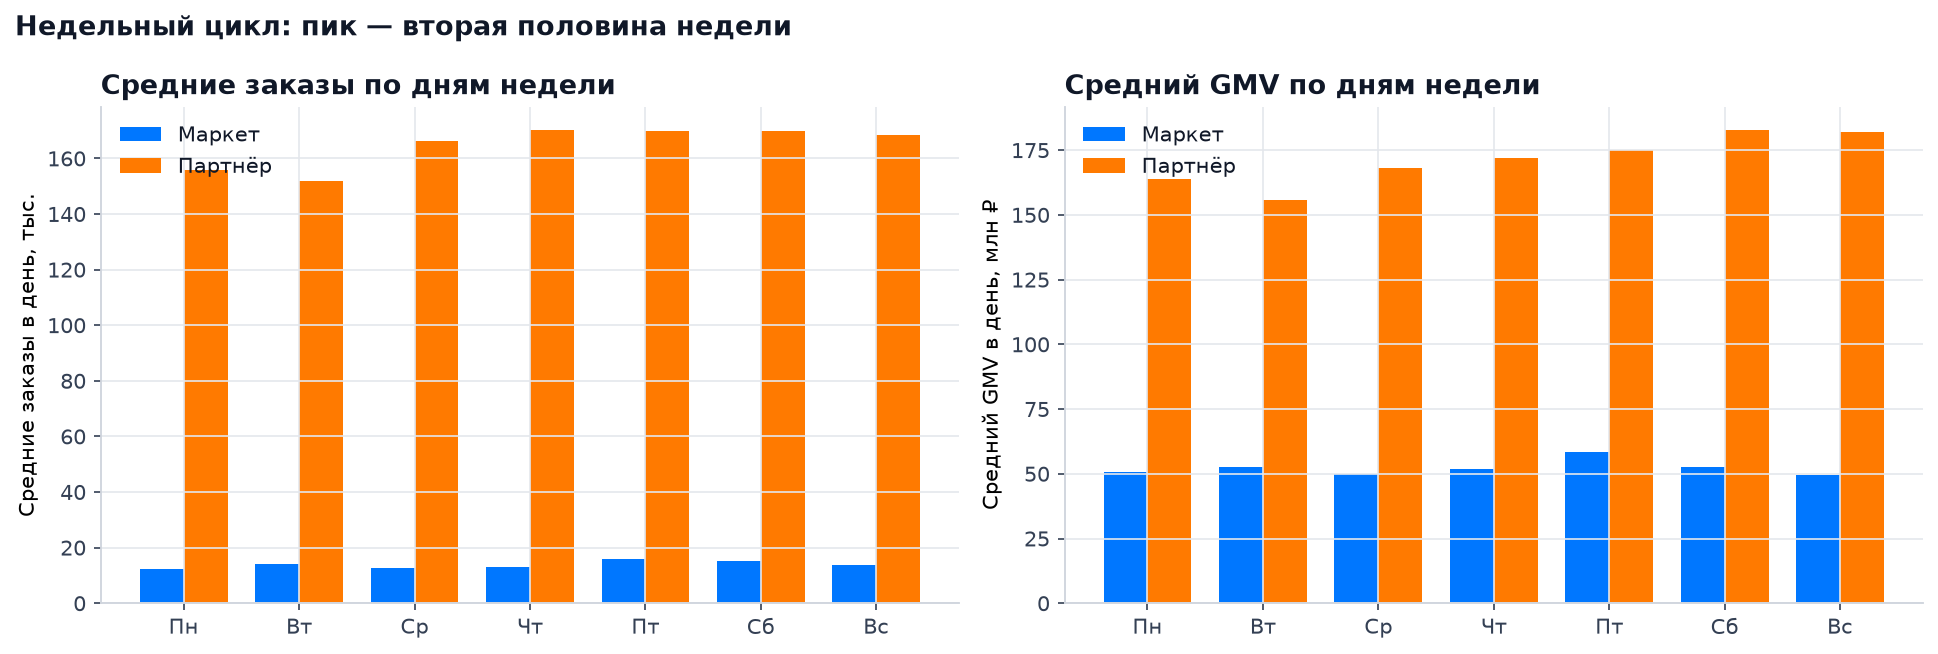

,Заказы_Маркет,Заказы_Партнёр,GMV_Маркет,GMV_Партнёр
День недели,,,,
Пн,12294.0,156016.0,50539750.0,163687866.0
Вт,14047.0,151823.0,52728647.0,155734317.0
Ср,12740.0,166314.0,49984383.0,167928488.0
Чт,13141.0,170118.0,51796822.0,172034237.0
Пт,15784.0,169757.0,58382620.0,174872498.0
Сб,15155.0,169745.0,52436180.0,182666945.0
Вс,13577.0,168575.0,49590026.0,182038618.0


In [46]:
# --- Будни и выходные --------------------------------------------------------
wd = (day.groupby('День недели')
         .agg(Заказы_Маркет=('Заказы: Маркет Вконтакте','mean'),
              Заказы_Партнёр=('Заказы: Партнёр 1','mean'),
              GMV_Маркет=('GMV, ₽: Маркет Вконтакте','mean'),
              GMV_Партнёр=('GMV, ₽: Партнёр 1','mean'))
         .reindex(DN))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
x = np.arange(7); w = 0.38
b1 = axes[0].bar(x-w/2, wd['Заказы_Маркет']/1e3, w, color=C_VK, label='Маркет')
b2 = axes[0].bar(x+w/2, wd['Заказы_Партнёр']/1e3, w, color=C_PT, label='Партнёр')
axes[0].set_xticks(x); axes[0].set_xticklabels(DN)
axes[0].set_ylabel('Средние заказы в день, тыс.')
axes[0].set_title('Средние заказы по дням недели')
axes[0].legend()

b3 = axes[1].bar(x-w/2, wd['GMV_Маркет']/1e6, w, color=C_VK, label='Маркет')
b4 = axes[1].bar(x+w/2, wd['GMV_Партнёр']/1e6, w, color=C_PT, label='Партнёр')
axes[1].set_xticks(x); axes[1].set_xticklabels(DN)
axes[1].set_ylabel('Средний GMV в день, млн ₽')
axes[1].set_title('Средний GMV по дням недели')
axes[1].legend()
fig.suptitle('Недельный цикл: пик — вторая половина недели', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

display(wd.round(0))

**Легенда к дням недели.** Слева — средние заказы по дням недели, справа — средний GMV; синий — Маркет, оранжевый — Партнёр. У обоих сегментов провал в понедельник-вторник и подъём со среды по пятницу. Пик Партнёра — четверг, у Маркета — пятница. Размах: у Маркета заказы меняются на 28% между худшим и лучшим днём, у Партнёра — на 12%. Практический вывод: **рекламные и промо-бюджеты выгоднее ставить на среду–субботу**, а не на начало недели.

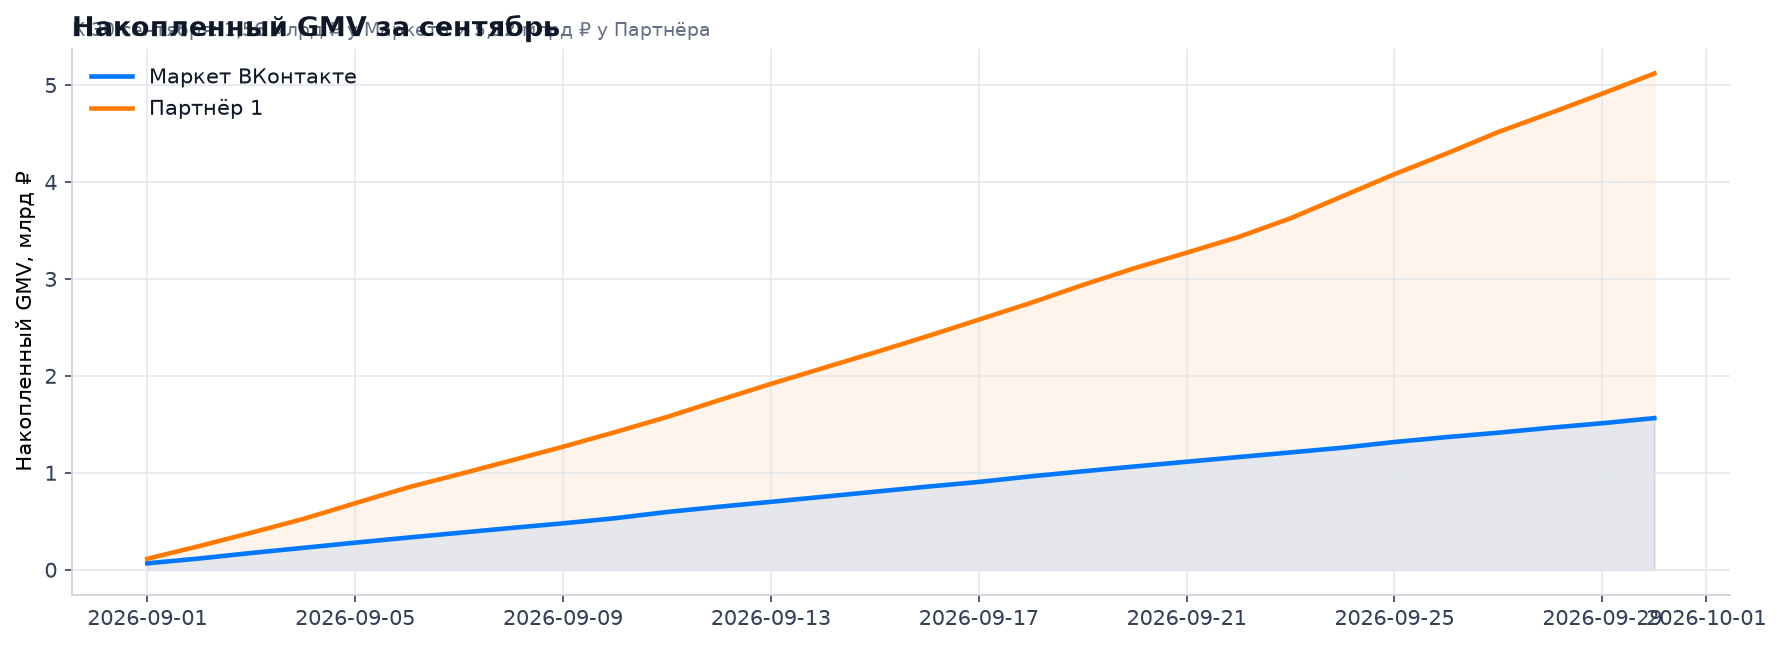

Итоговый GMV — Маркет: 1,56 млрд ₽ | Партнёр: 5,12 млрд ₽
Средний дневной GMV за последнюю неделю — Маркет: 50,6 млн ₽ | Партнёр: 213,4 млн ₽


In [47]:
# --- Накопительный GMV -------------------------------------------------------
fig, ax = plt.subplots(figsize=(12, 4.4))
ax.plot(day['Дата'], day['GMV_cum_VK']/1e9, color=C_VK, lw=2.2, label='Маркет ВКонтакте')
ax.plot(day['Дата'], day['GMV_cum_PT']/1e9, color=C_PT, lw=2.2, label='Партнёр 1')
ax.fill_between(day['Дата'], 0, day['GMV_cum_PT']/1e9, color=C_PT, alpha=0.08)
ax.fill_between(day['Дата'], 0, day['GMV_cum_VK']/1e9, color=C_VK, alpha=0.10)
ax.set_ylabel('Накопленный GMV, млрд ₽')
ax.set_title('Накопленный GMV за сентябрь')
subtitle(ax, 'К 30 сентября: 1,56 млрд ₽ у Маркета и 5,12 млрд ₽ у Партнёра')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

print('Итоговый GMV — Маркет:', fmoney(day['GMV_cum_VK'].iloc[-1],2),
      '| Партнёр:', fmoney(day['GMV_cum_PT'].iloc[-1],2))
print('Средний дневной GMV за последнюю неделю — Маркет:',
      fmoney(day['GMV, ₽: Маркет Вконтакте'].tail(7).mean(),1),
      '| Партнёр:', fmoney(day['GMV, ₽: Партнёр 1'].tail(7).mean(),1))

**Легенда к накопленному GMV.** Две накопительные кривые, млрд ₽. Наклон линии = дневная выручка. У Маркета наклон почти постоянный, у Партнёра — увеличивается к концу месяца, кривая заметно выгибается вверх. К 30 сентября накопленный GMV: 1,56 млрд ₽ против 5,12 млрд ₽. Если наклон Партнёра сохранится, разрыв будет расти. Для Маркета это означает необходимость либо повышать конверсию, либо переходить к модели, где партнёрский оборот учитывается как его собственный результат.

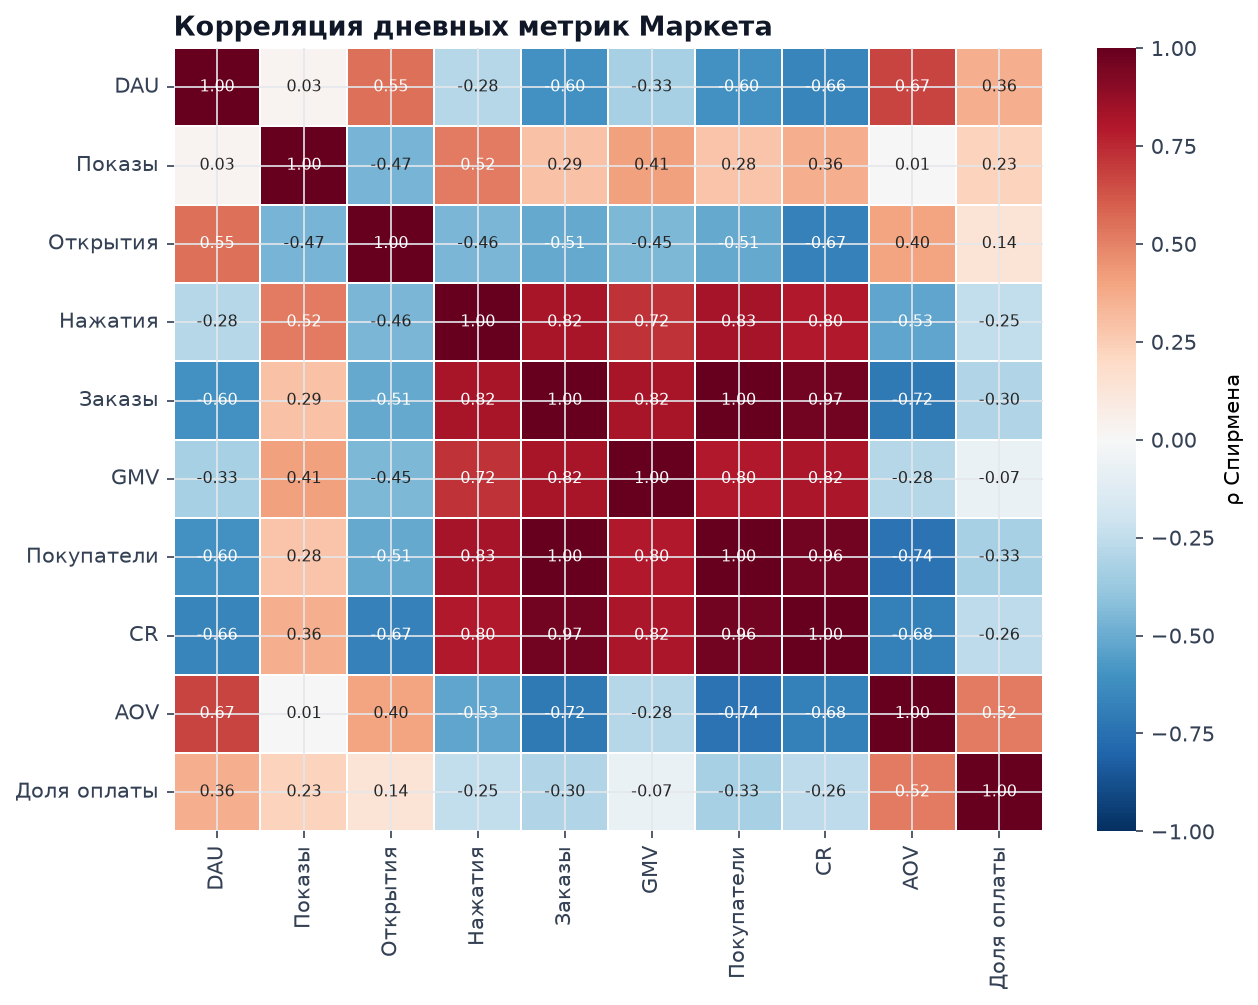

Связь заказов с показами: 0.29
Связь заказов с открытиями: -0.51
Связь заказов с AOV: -0.72


In [48]:
# --- Корреляция дневных метрик ----------------------------------------------
dc = day.drop(columns=['Дата','День недели']).corr(method='spearman')
sel = ['DAU Маркета Вконтакте','Показы товаров: Маркет Вконтакте','Открытия карточки: Маркет Вконтакте',
       'Нажатия на кнопку: Маркет Вконтакте','Заказы: Маркет Вконтакте','GMV, ₽: Маркет Вконтакте',
       'Покупатели: Маркет Вконтакте','CR_VK','AOV_VK','PAID_SHARE']
labels = ['DAU','Показы','Открытия','Нажатия','Заказы','GMV','Покупатели','CR','AOV','Доля оплаты']
sub = dc.loc[sel, sel]

fig, ax = plt.subplots(figsize=(8.6, 6.8))
sns.heatmap(sub, annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1,
            xticklabels=labels, yticklabels=labels, linewidths=0.8, linecolor='white',
            cbar_kws={'label':'ρ Спирмена'}, annot_kws={'fontsize':7.6}, ax=ax)
ax.set_title('Корреляция дневных метрик Маркета')
plt.tight_layout()
plt.show()

print('Связь заказов с показами:', round(dc.loc['Заказы: Маркет Вконтакте','Показы товаров: Маркет Вконтакте'],2))
print('Связь заказов с открытиями:', round(dc.loc['Заказы: Маркет Вконтакте','Открытия карточки: Маркет Вконтакте'],2))
print('Связь заказов с AOV:', round(dc.loc['Заказы: Маркет Вконтакте','AOV_VK'],2))

**Легенда к корреляции дней.** Матрица Спирмена по 30 дневным наблюдениям Маркета. Заказы почти совпадают с покупателями (ρ ≈ 1,00 — механическая связь) и тесно связаны с нажатиями (0,82) и конверсией (0,97); с показами связь слабая (0,29), а с открытиями карточки — отрицательная (−0,51). Средний чек с заказами связан отрицательно (−0,72): в дни с большим числом заказов чек ниже (массовые дешёвые покупки). Это подтверждает: **объём продаж определяется кликами и конверсией, а не шириной охвата**.

## 4. Таблица 4 «Источники»: откуда приходят открытия карточки

Лист показывает, какие каналы приводят пользователя к карточке товара. Сумма по шести каналам ровно совпадает с открытиями карточки в «Итогах» (193,5 млн у Маркета и 86,9 млн у Партнёра), поэтому анализируем и доли, и абсолюты. Строка «в т.ч. из реферальных постов и клипов» — вложенная детализация, её нельзя прибавлять к каналам, иначе получится задвоение.

Строка «в т.ч. из реферальных постов и клипов» — не отдельный канал, а вложенная детализация. В основные графики она не включается, чтобы не задваивать счёт.

In [49]:
# --- Источники: подготовка ---------------------------------------------------
REF_ROW = src[src['Источник'].str.startswith('в т.ч.')].iloc[0]
SRC = src[~src['Источник'].str.startswith('в т.ч.')].copy()
SRC = SRC.sort_values('Маркет Вконтакте', ascending=False)

display(SRC.style.hide(axis='index').format({
    'Маркет Вконтакте':'{:,.0f}', 'Доля, %: Маркет Вконтакте':'{:.1f}',
    'Партнёр 1':'{:,.0f}', 'Доля, %: Партнёр 1':'{:.1f}'}))

print('Сумма по источникам — Маркет:', fnum(SRC['Маркет Вконтакте'].sum(),1),
      '| Партнёр:', fnum(SRC['Партнёр 1'].sum(),1))
print('Реферальные посты/клипы у Партнёра:', fnum(REF_ROW['Партнёр 1'],1),
      '=', fpct(REF_ROW['Доля, %: Партнёр 1']), 'открытий Партнёра')

Источник,Маркет Вконтакте,"Доля, %: Маркет Вконтакте",Партнёр 1,"Доля, %: Партнёр 1"
Другое,"77,753,037",40.2,"5,380,616",6.2
Витрина магазина,"75,604,323",39.1,"714,540",0.8
Лента,"18,795,696",9.7,"15,622,386",18.0
Клипы,"17,239,066",8.9,"64,917,109",74.7
Поиск,"3,707,521",1.9,"159,788",0.2
Главная Маркета Вконтакте,"412,818",0.2,"88,383",0.1


Сумма по источникам — Маркет: 193,5 млн | Партнёр: 86,9 млн
Реферальные посты/клипы у Партнёра: 82,3 млн = 94,8% открытий Партнёра


**Легенда к таблице источников.** Шесть каналов и их доли для каждого сегмента. У Маркета картина «плоская»: «Другое» 40,2%, «Витрина магазина» 39,1%, «Лента» 9,7%, «Клипы» 8,9%, «Поиск» 1,9%, «Главная Маркета» 0,2%. У Партнёра — резко концентрированная: **«Клипы» 74,7%**, «Лента» 18,0%, «Другое» 6,2%, «Витрина» 0,8%. Это два разных механизма привлечения: у Маркета — витрина и «длинный хвост» каналов, у Партнёра — короткие видео.

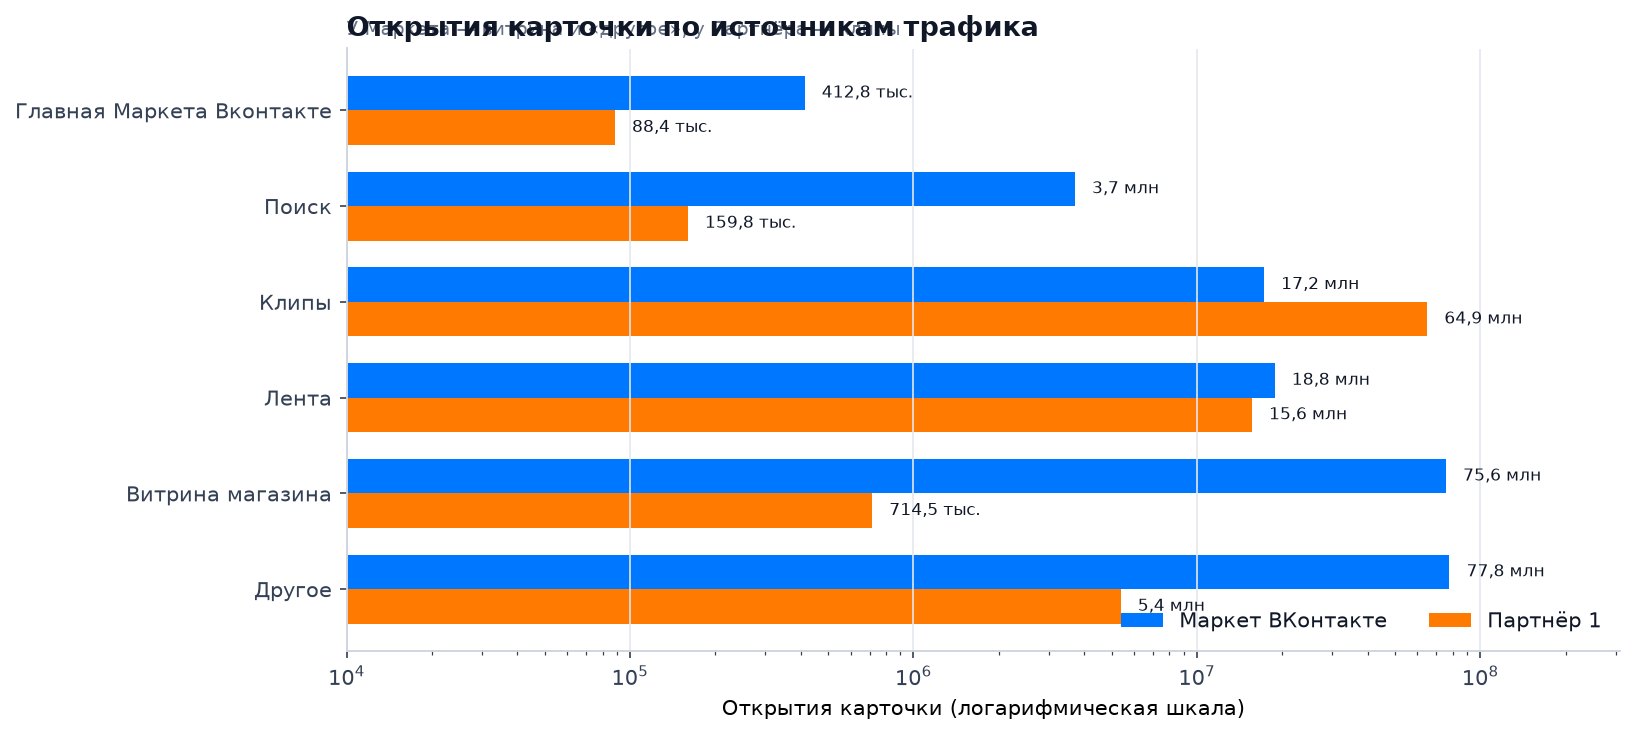

In [50]:
# --- Источники: сравнение ----------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(SRC)); h = 0.36
b1 = ax.barh(y+h/2, SRC['Маркет Вконтакте'], h, color=C_VK, label='Маркет ВКонтакте')
b2 = ax.barh(y-h/2, SRC['Партнёр 1'], h, color=C_PT, label='Партнёр 1')
ax.set_xscale('log')
ax.set_yticks(y); ax.set_yticklabels(SRC['Источник'])
ax.set_xlabel('Открытия карточки (логарифмическая шкала)')
ax.set_title('Открытия карточки по источникам трафика')
subtitle(ax, 'У Маркета — витрина и «другое», у Партнёра — клипы')
ax.legend(ncol=2, loc='lower right')
for bars in (b1, b2):
    for b in bars:
        v = b.get_width()
        ax.text(v*1.15, b.get_y()+b.get_height()/2, fnum(v,1), va='center', fontsize=8)
ax.set_xlim(1e4, SRC[['Маркет Вконтакте','Партнёр 1']].max().max()*4)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к сравнению источников.** Горизонтальные столбцы, логарифмическая шкала X, сверху пара для Маркета, снизу для Партнёра. Логарифм нужен из-за разброса от 88 тыс. до 77,8 млн. Читать по парам: у Маркета «Другое» и «Витрина магазина» почти равны (77,8 и 75,6 млн), у Партнёра «Клипы» (64,9 млн) в 4,2 раза больше следующего канала «Лента» (15,6 млн) и в 91 раз больше «Витрины» (0,7 млн). **Партнёр живёт клипами, Маркет — витриной.**

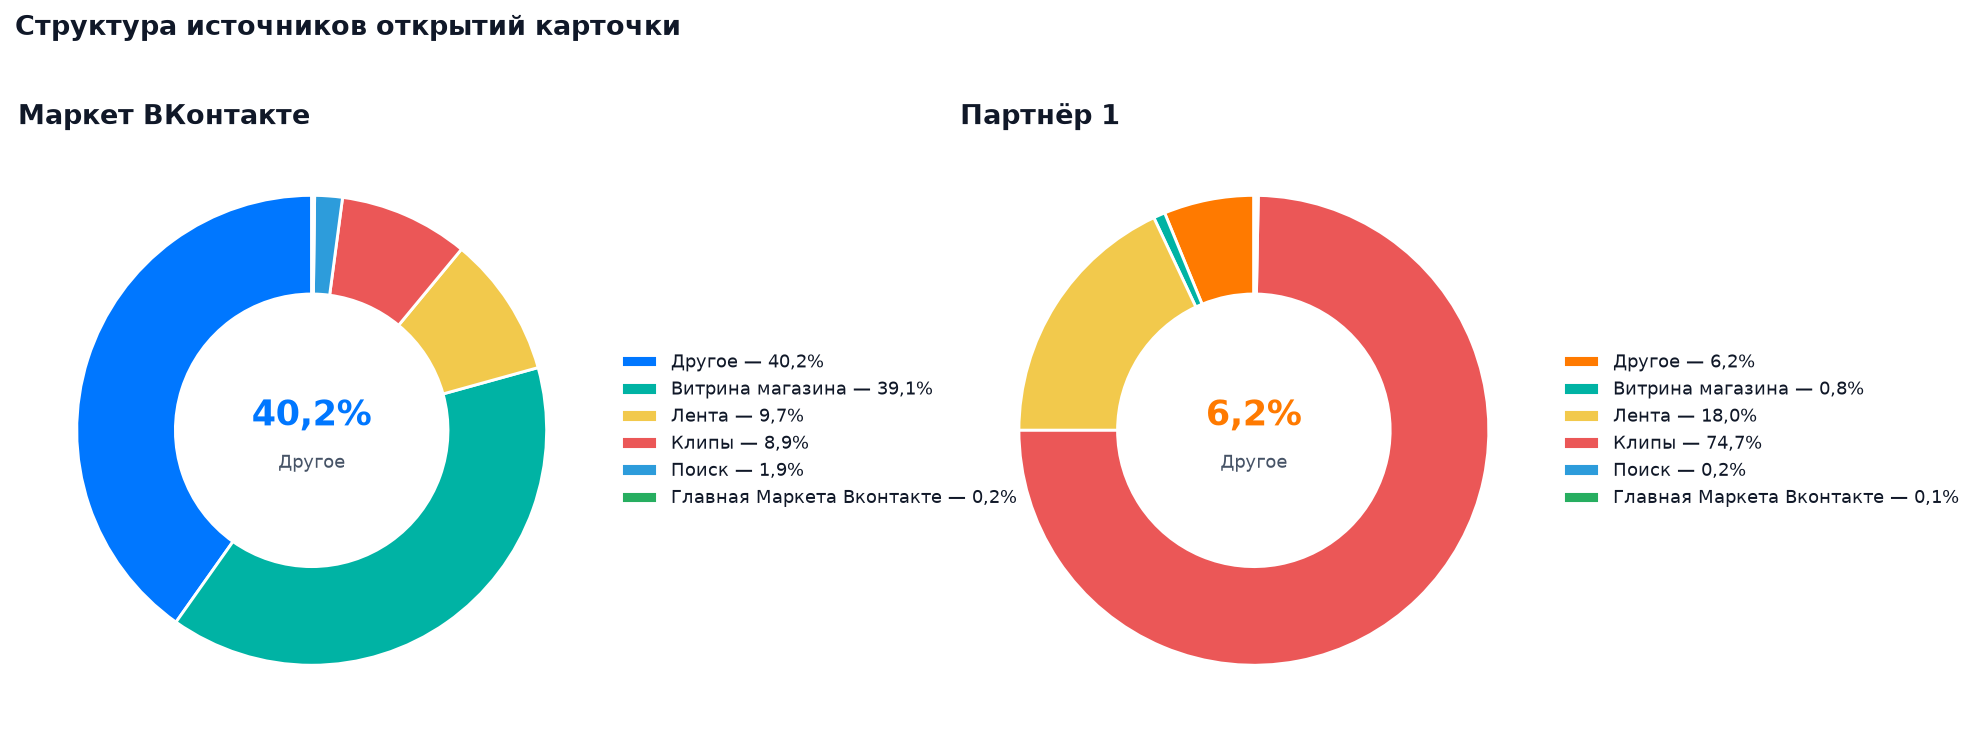

In [51]:
# --- Доли источников: две кольцевые диаграммы --------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, col, ttl, base in [
    (axes[0], 'Доля, %: Маркет Вконтакте', 'Маркет ВКонтакте', C_VK),
    (axes[1], 'Доля, %: Партнёр 1', 'Партнёр 1', C_PT)]:
    vals = SRC[col].values
    labs = SRC['Источник'].values
    cols = [base if i == 0 else PALETTE[(i+2) % len(PALETTE)] for i in range(len(vals))]
    wedges, _ = ax.pie(vals, colors=cols, startangle=90,
                       wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.4))
    ax.set_title(ttl)
    ax.text(0, 0.06, f'{vals[0]:.1f}%'.replace('.', ','), ha='center', va='center',
            fontsize=17, fontweight='bold', color=base)
    ax.text(0, -0.14, labs[0], ha='center', va='center', fontsize=8.5, color='#475467')
    ax.legend(wedges, [f'{l} — {v:.1f}%'.replace('.', ',') for l, v in zip(labs, vals)],
              loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8.5)
fig.suptitle('Структура источников открытий карточки', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

**Легенда к кольцевым диаграммам.** Слева — Маркет, справа — Партнёр; в центре — крупнейший канал, в легенде — все доли. У Маркета нет доминанты: два канала примерно равны (40,2% и 39,1%), остальные суммарно 20,7%. У Партнёра один канал определяет всё: клипы 74,7%, вместе с лентой — 92,7%. **Концентрация канала — риск**: изменения в алгоритме клипов или модерации способны резко сократить трафик Партнёра. У Маркета структура диверсифицирована, но слабо управляема: 40% приходится на нерасшифрованное «Другое».

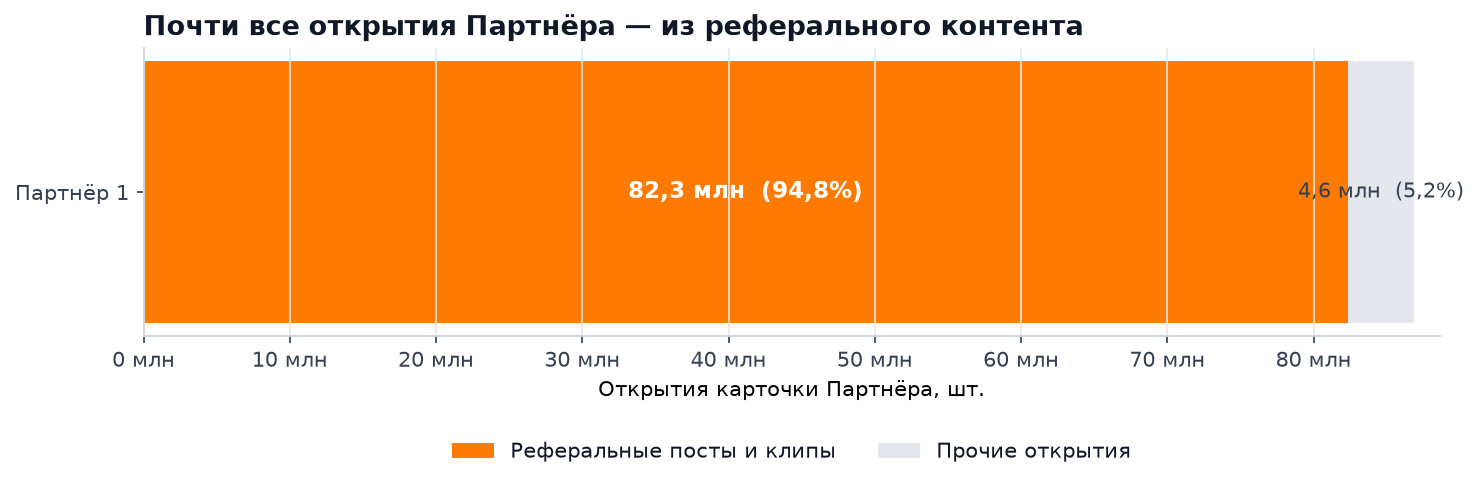

In [52]:
# --- Реферальная доля Партнёра ----------------------------------------------
vals = [REF_ROW['Партнёр 1'], OPEN_PT - REF_ROW['Партнёр 1']]
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.barh(['Партнёр 1'], [vals[0]], color=C_PT, height=0.45, label='Реферальные посты и клипы')
ax.barh(['Партнёр 1'], [vals[1]], left=[vals[0]], color='#E4E7EC', height=0.45, label='Прочие открытия')
ax.text(vals[0]/2, 0, f'{fnum(vals[0],1)}  ({REF_ROW["Доля, %: Партнёр 1"]:.1f}%)'.replace('.', ','),
        ha='center', va='center', color='white', fontsize=11, fontweight='bold')
ax.text(vals[0]+vals[1]/2, 0, f'{fnum(vals[1],1)}  ({100-REF_ROW["Доля, %: Партнёр 1"]:.1f}%)'.replace('.', ','),
        ha='center', va='center', color='#344054', fontsize=10)
ax.set_xlim(0, OPEN_PT*1.02)
ax.set_xlabel('Открытия карточки Партнёра, шт.')
ax.set_title('Почти все открытия Партнёра — из реферального контента')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{v/1e6:.0f} млн'))
ax.legend(ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.3))
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к реферальной доле.** Одна горизонтальная полоса, разделённая на две части: оранжевая — открытия из реферальных постов и клипов (82,3 млн; 94,8%), серая — все остальные (4,6 млн; 5,2%). Это самый сильный факт о Партнёре: **его трафик почти полностью создаётся авторами ВКонтакте**, а не собственной витриной. Роль платформы здесь — не магазин, а дистрибуция контента и социальный граф.

## 5. Таблица 5 «Категории»: что смотрят и что покупают

18 категорий, для каждой — открытия карточки и заказы в двух сегментах. Категории «Другое», «Все товары» и «Не определена» — служебные, они искажают конверсию и рассматриваются отдельно.

### 5.1. Открытия карточки по категориям

In [53]:
# --- Категории: подготовка ---------------------------------------------------
cat = cat.copy()
cat['Открытия всего'] = cat['Открытия карточки: Маркет Вконтакте'] + cat['Открытия карточки: Партнёр 1']
cat['Заказы всего'] = cat['Заказы: Маркет Вконтакте'] + cat['Заказы: Партнёр 1']
cat_sorted = cat.sort_values('Открытия всего', ascending=True)

SERVICE = ['Другое', 'Не определена', 'Все товары']
cat_real = cat[~cat['Категория'].isin(SERVICE)].copy()
cat_real['CR_VK_1000'] = cat_real['Заказы: Маркет Вконтакте'] / cat_real['Открытия карточки: Маркет Вконтакте'] * 1000
cat_real['CR_PT_1000'] = cat_real['Заказы: Партнёр 1'] / cat_real['Открытия карточки: Партнёр 1'] * 1000

print('Служебные категории:')
display(cat[cat['Категория'].isin(SERVICE)][['Категория','Открытия карточки: Маркет Вконтакте',
        'Заказы: Маркет Вконтакте','Открытия карточки: Партнёр 1','Заказы: Партнёр 1']].style.hide(axis='index'))

Служебные категории:


Категория,Открытия карточки: Маркет Вконтакте,Заказы: Маркет Вконтакте,Открытия карточки: Партнёр 1,Заказы: Партнёр 1
Другое,29082926,41,160,0
Все товары,1441409,205,3098084,138949
Не определена,193354,159,0,117818


**Легенда к служебным категориям.** Три строки, которые нельзя считать товарными. «Другое» у Маркета: 29,1 млн открытий и 41 заказ — очевидно, карточки не определены. «Не определена» у Партнёра: 0 открытий и 117 818 заказов — обратная аномалия. «Все товары» — агрегированная витрина. Эти строки исключены из расчёта конверсий, но сохранены в общих суммах, чтобы не искажать общий объём.

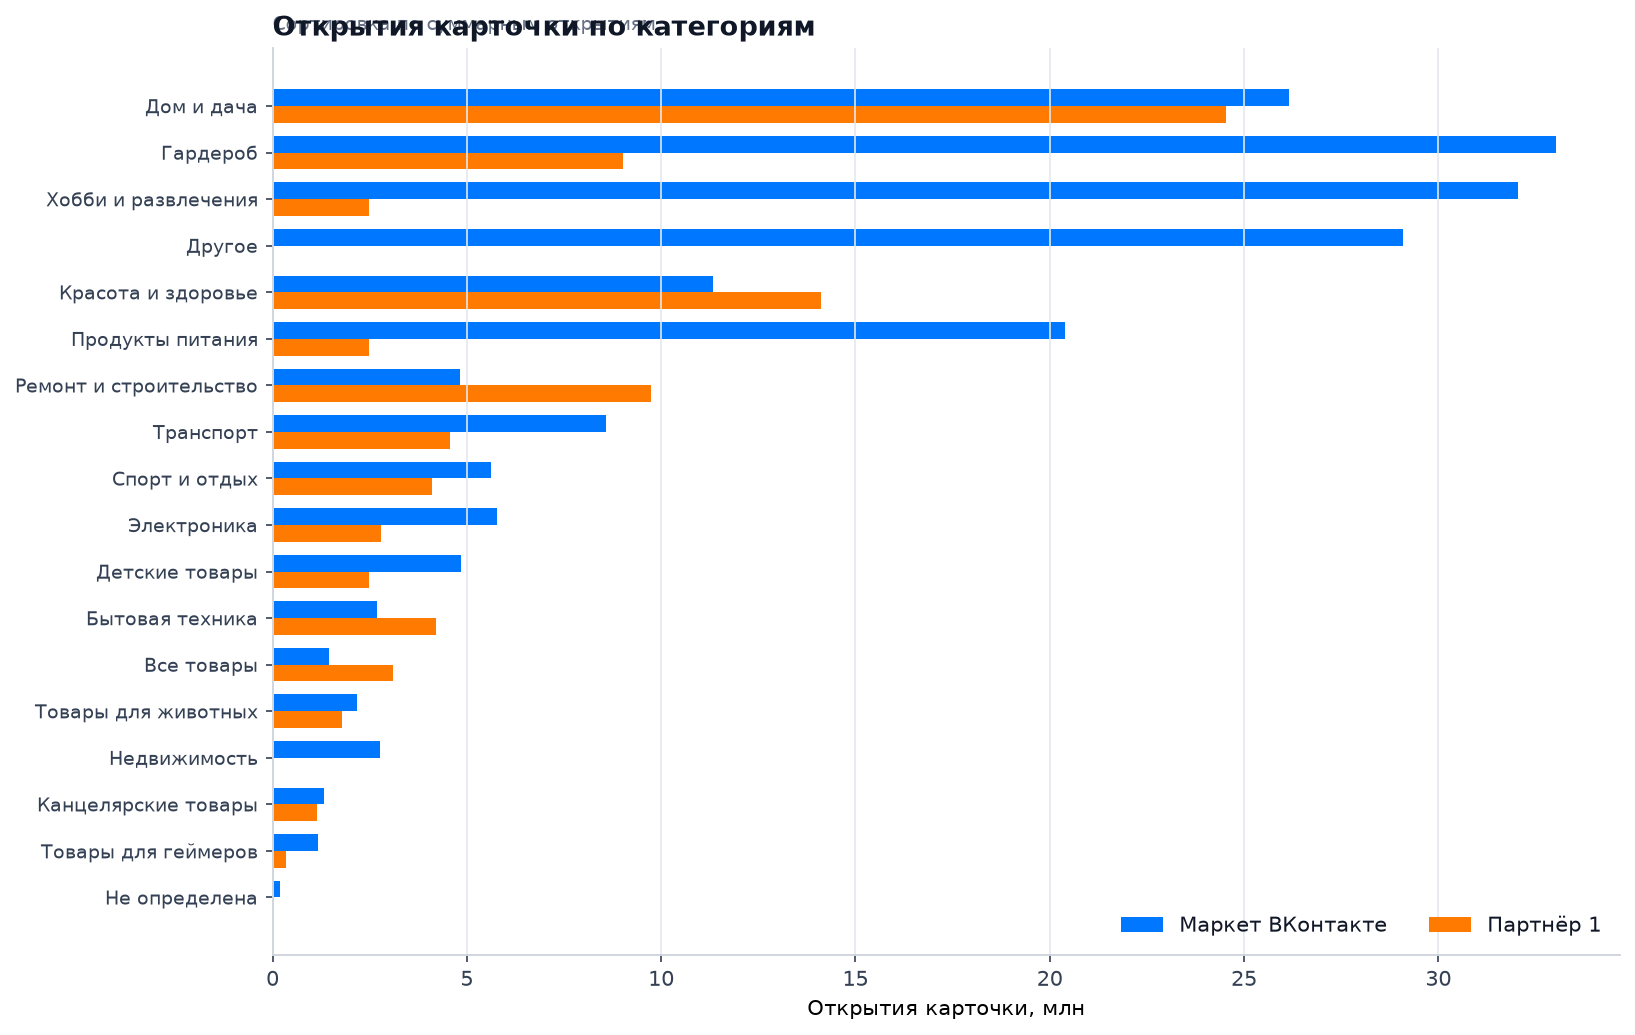

Категория,Открытия карточки: Маркет Вконтакте,Открытия карточки: Партнёр 1,Открытия всего
Дом и дача,"26,162,824","24,528,887","50,691,711"
Гардероб,"33,022,954","9,023,244","42,046,198"
Хобби и развлечения,"32,048,705","2,474,633","34,523,338"
Другое,"29,082,926",160,"29,083,086"
Красота и здоровье,"11,345,073","14,113,274","25,458,347"
Продукты питания,"20,393,319","2,488,477","22,881,796"
Ремонт и строительство,"4,823,519","9,737,416","14,560,935"
Транспорт,"8,590,002","4,569,160","13,159,162"


In [54]:
# --- Открытия по категориям --------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(cat_sorted)); h = 0.36
ax.barh(y+h/2, cat_sorted['Открытия карточки: Маркет Вконтакте']/1e6, h, color=C_VK, label='Маркет ВКонтакте')
ax.barh(y-h/2, cat_sorted['Открытия карточки: Партнёр 1']/1e6, h, color=C_PT, label='Партнёр 1')
ax.set_yticks(y); ax.set_yticklabels(cat_sorted['Категория'], fontsize=9)
ax.set_xlabel('Открытия карточки, млн')
ax.set_title('Открытия карточки по категориям')
subtitle(ax, 'Сортировка по суммарным открытиям')
ax.legend(ncol=2, loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

display(cat.sort_values('Открытия всего', ascending=False).head(8)[
    ['Категория','Открытия карточки: Маркет Вконтакте','Открытия карточки: Партнёр 1','Открытия всего']]
    .style.hide(axis='index').format('{:,.0f}', subset=['Открытия карточки: Маркет Вконтакте',
                                                       'Открытия карточки: Партнёр 1','Открытия всего']))

**Легенда к открытиям по категориям.** Горизонтальные столбцы, млн открытий, сортировка по сумме двух сегментов. Топ Маркета: «Гардероб» 33,0 млн, «Хобби и развлечения» 32,0 млн, «Другое» 29,1 млн, «Дом и дача» 26,2 млн, «Продукты питания» 20,4 млн. Топ Партнёра: «Дом и дача» 24,5 млн, «Красота и здоровье» 14,1 млн, «Ремонт и строительство» 9,7 млн, «Гардероб» 9,0 млн. Совпадение только в «Доме и даче» и «Гардеробе»; в остальном **Маркет тяготеет к хобби и контенту, Партнёр — к бытовым и ремонтным товарам**.

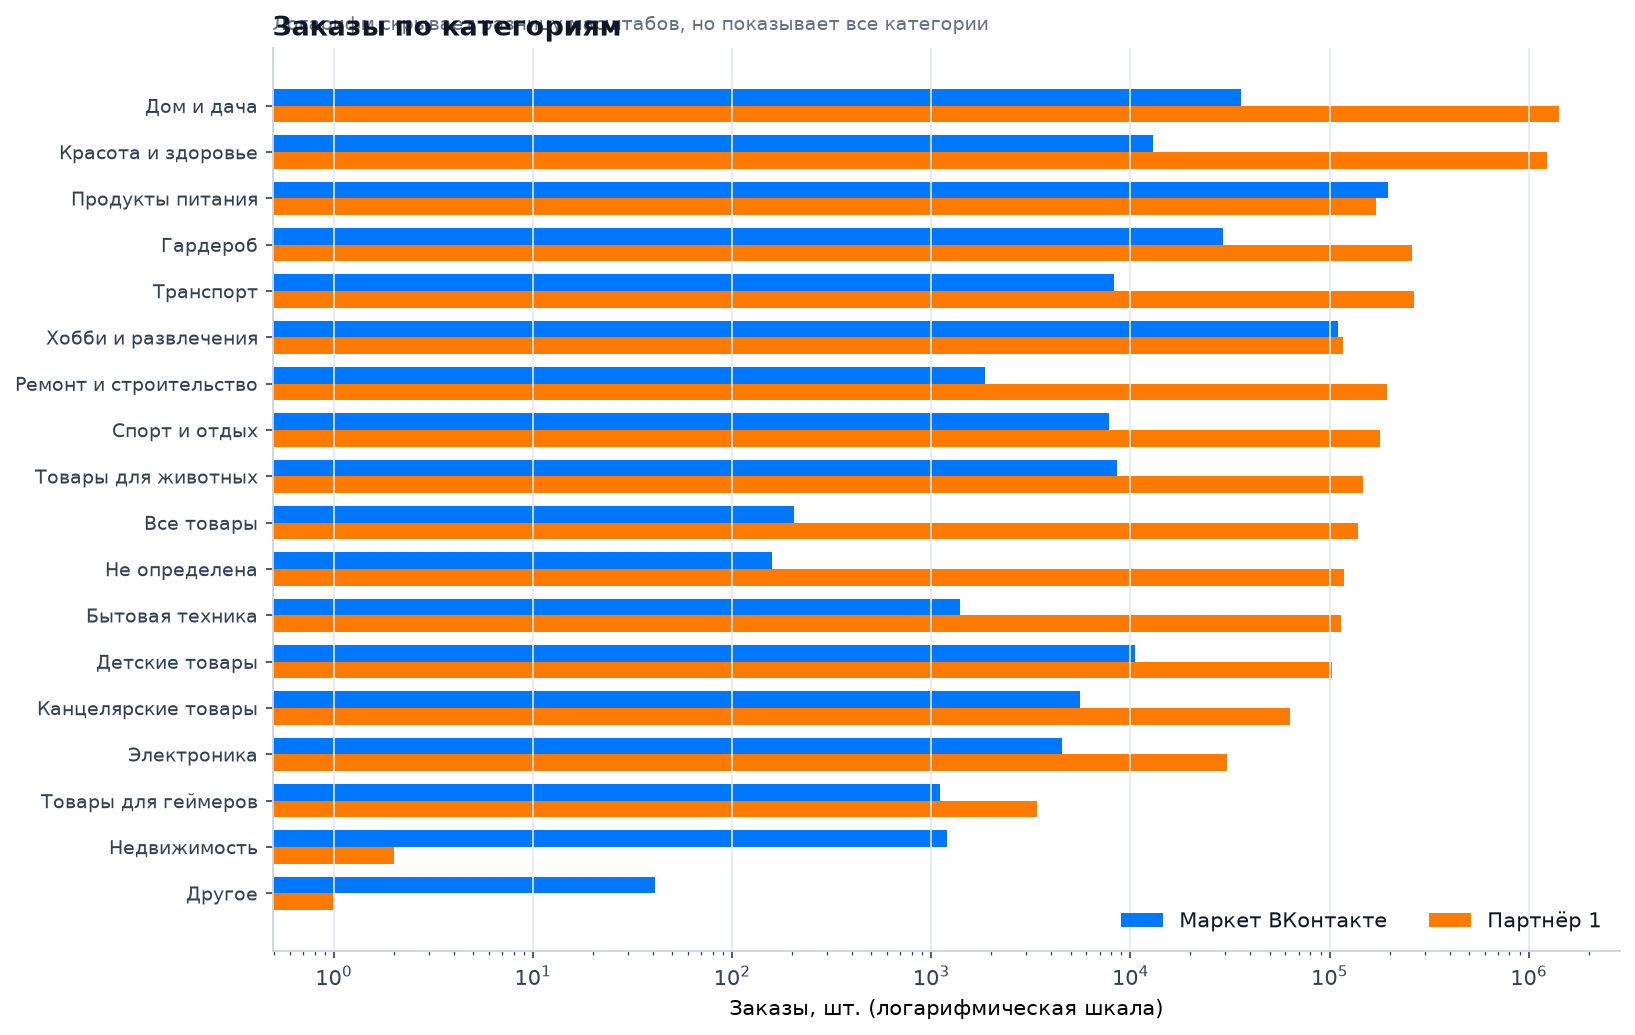

Заказы Маркета: топ-3
          Категория  Заказы: Маркет Вконтакте
   Продукты питания                    195355
Хобби и развлечения                    110703
         Дом и дача                     35976

Заказы Партнёра: топ-3
         Категория  Заказы: Партнёр 1
        Дом и дача            1413965
Красота и здоровье            1240324
         Транспорт             264510


In [55]:
# --- Заказы по категориям ----------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 7))
cs = cat.sort_values('Заказы всего', ascending=True)
y = np.arange(len(cs)); h = 0.36
ax.barh(y+h/2, cs['Заказы: Маркет Вконтакте'].clip(lower=1), h, color=C_VK, label='Маркет ВКонтакте')
ax.barh(y-h/2, cs['Заказы: Партнёр 1'].clip(lower=1), h, color=C_PT, label='Партнёр 1')
ax.set_xscale('log')
ax.set_yticks(y); ax.set_yticklabels(cs['Категория'], fontsize=9)
ax.set_xlabel('Заказы, шт. (логарифмическая шкала)')
ax.set_title('Заказы по категориям')
subtitle(ax, 'Логарифм скрывает разницу масштабов, но показывает все категории')
ax.legend(ncol=2, loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Заказы Маркета: топ-3')
print(cat.nlargest(3, 'Заказы: Маркет Вконтакте')[['Категория','Заказы: Маркет Вконтакте']].to_string(index=False))
print('\nЗаказы Партнёра: топ-3')
print(cat.nlargest(3, 'Заказы: Партнёр 1')[['Категория','Заказы: Партнёр 1']].to_string(index=False))

**Легенда к заказам по категориям.** Логарифмическая шкала X, чтобы вместить диапазон от 0 до 1,4 млн. У Маркета заказы концентрируются в «Продуктах питания» (195 355; 44,9% всех заказов по категориям) и «Хобби» (110 703; 25,4%). У Партнёра — «Дом и дача» (1 413 965; 31,0%) и «Красота» (1 240 324; 27,2%). Обратите внимание на несоответствие: «Гардероб» — лидер по открытиям у Маркета (33 млн), но лишь 29 тыс. заказов. **Смотрят одежду, покупают еду.**

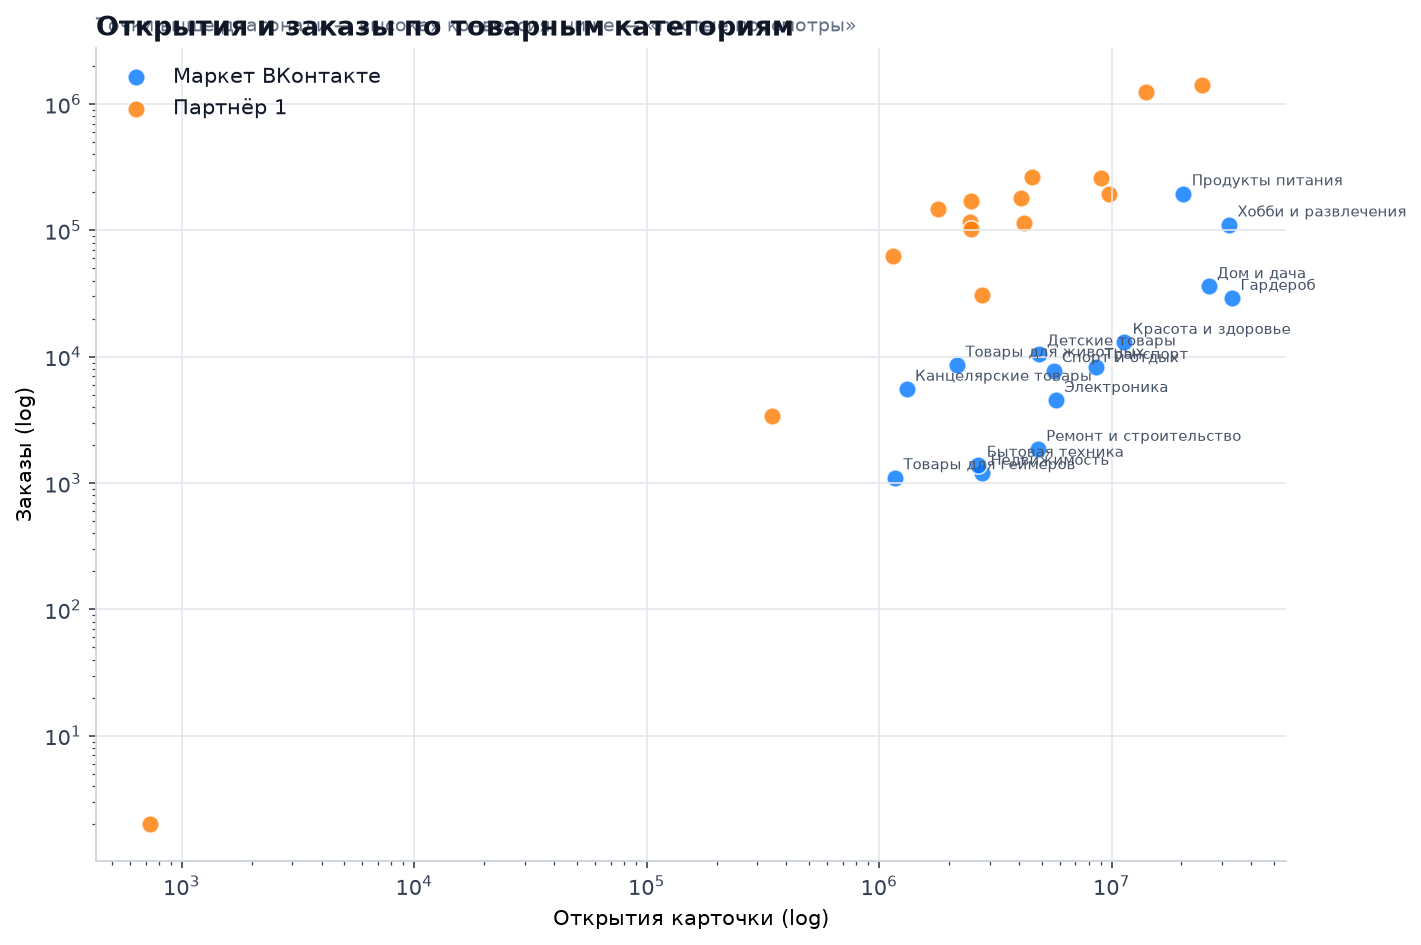

Категории с наибольшим числом открытий, но низкими заказами (Маркет):
             Категория  Открытия карточки: Маркет Вконтакте  Заказы: Маркет Вконтакте
Ремонт и строительство                              4823519                      1854
          Недвижимость                              2775277                      1199
       Бытовая техника                              2675368                      1388
           Электроника                              5768728                      4519


In [56]:
# --- Открытия vs заказы ------------------------------------------------------
fig, ax = plt.subplots(figsize=(9.6, 6.4))
ax.scatter(cat_real['Открытия карточки: Маркет Вконтакте'], cat_real['Заказы: Маркет Вконтакте'],
           s=70, color=C_VK, alpha=0.8, label='Маркет ВКонтакте', edgecolors='white', linewidths=0.8)
ax.scatter(cat_real['Открытия карточки: Партнёр 1'], cat_real['Заказы: Партнёр 1'],
           s=70, color=C_PT, alpha=0.8, label='Партнёр 1', edgecolors='white', linewidths=0.8)
for _, r in cat_real.iterrows():
    ax.annotate(r['Категория'], (r['Открытия карточки: Маркет Вконтакте'], r['Заказы: Маркет Вконтакте']),
                fontsize=7, color='#475467', xytext=(4, 4), textcoords='offset points')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Открытия карточки (log)')
ax.set_ylabel('Заказы (log)')
ax.set_title('Открытия и заказы по товарным категориям')
subtitle(ax, 'Точки выше диагонали — высокая конверсия, ниже — «пустые просмотры»')
ax.legend()
plt.tight_layout()
plt.show()

print('Категории с наибольшим числом открытий, но низкими заказами (Маркет):')
tmp = cat_real.assign(ratio=cat_real['Заказы: Маркет Вконтакте']/cat_real['Открытия карточки: Маркет Вконтакте'])
print(tmp.nsmallest(4,'ratio')[['Категория','Открытия карточки: Маркет Вконтакте','Заказы: Маркет Вконтакте']].to_string(index=False))

**Легенда к scatter «открытия vs заказы».** Каждая точка — товарная категория, синие — Маркет, оранжевые — Партнёр; обе оси логарифмические, подписи — названия категорий. Положение по вертикали относительно облака показывает конверсию: «Продукты питания» у Маркета — высоко (много заказов при умеренных открытиях), «Гардероб» — низко (много открытий, мало заказов). У Партнёра «Дом и дача» и «Красота» — в верхней части. Это карта спроса: **открытие карточки и покупка — разные решения**, и категория определяет разрыв.

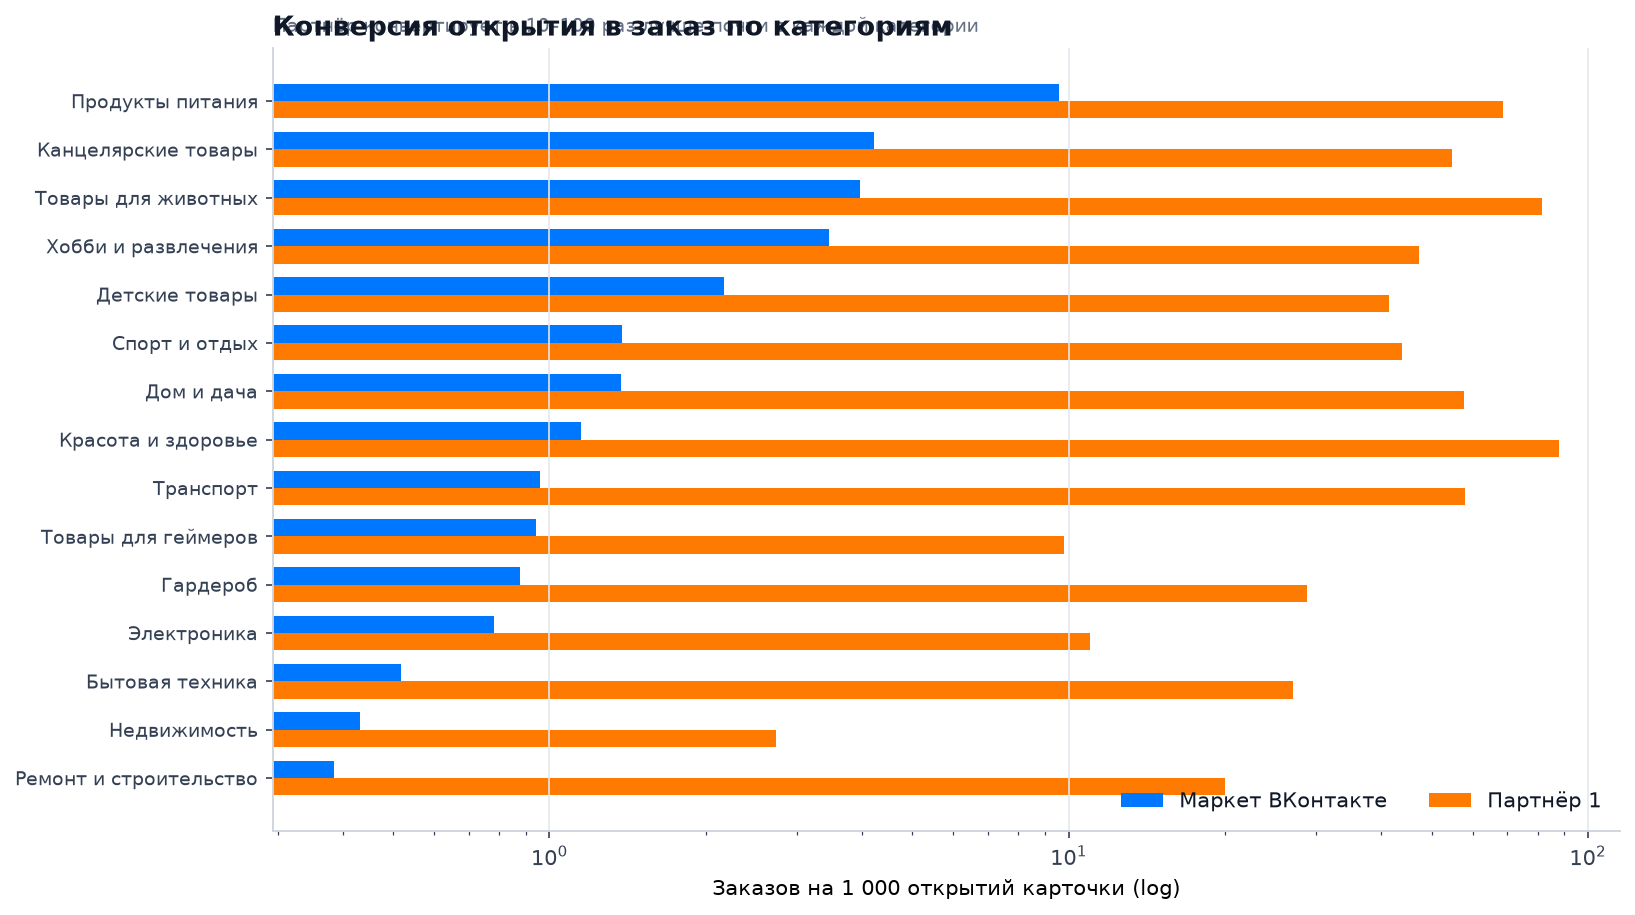

Во сколько раз Партнёр конвертирует лучше (топ-5):
             Категория  CR_VK_1000  CR_PT_1000  ratio
    Красота и здоровье         1.1        87.9   76.6
             Транспорт         1.0        57.9   60.2
       Бытовая техника         0.5        27.1   52.2
Ремонт и строительство         0.4        20.0   52.1
            Дом и дача         1.4        57.6   41.9


In [57]:
# --- Конверсия по категориям -------------------------------------------------
crc = cat_real.sort_values('CR_VK_1000', ascending=True)
fig, ax = plt.subplots(figsize=(11, 6.2))
y = np.arange(len(crc)); h = 0.36
ax.barh(y+h/2, crc['CR_VK_1000'], h, color=C_VK, label='Маркет ВКонтакте')
ax.barh(y-h/2, crc['CR_PT_1000'], h, color=C_PT, label='Партнёр 1')
ax.set_xscale('log')
ax.set_yticks(y); ax.set_yticklabels(crc['Категория'], fontsize=9)
ax.set_xlabel('Заказов на 1 000 открытий карточки (log)')
ax.set_title('Конверсия открытия в заказ по категориям')
subtitle(ax, 'Партнёр конвертирует в 10–100 раз лучше почти в каждой категории')
ax.legend(ncol=2, loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

cv = cat_real.assign(ratio=cat_real['CR_PT_1000']/cat_real['CR_VK_1000']).sort_values('ratio', ascending=False)
print('Во сколько раз Партнёр конвертирует лучше (топ-5):')
print(cv.head(5)[['Категория','CR_VK_1000','CR_PT_1000','ratio']].round(1).to_string(index=False))

**Легенда к конверсии по категориям.** Столбцы — заказов на 1 000 открытий карточки, логарифмическая шкала; синий — Маркет, оранжевый — Партнёр. У Маркета лучшие категории — «Продукты питания» (9,6 заказа на 1 000 открытий), «Канцелярские товары» (4,2), «Товары для животных» (4,0) и «Хобби» (3,5), худшие — «Ремонт и строительство» (0,4), «Недвижимость» (0,4) и «Бытовая техника» (0,5). У Партнёра лидеры — «Красота и здоровье» (87,9), «Товары для животных» (81,7), «Продукты питания» (68,5), «Дом и дача» (57,6). Разрыв по категориям — от 6 до 77 раз. Вывод: **проблема Маркета не в ассортименте, а в транзакционном слое** — те же категории у Партнёра продаются на порядок лучше.

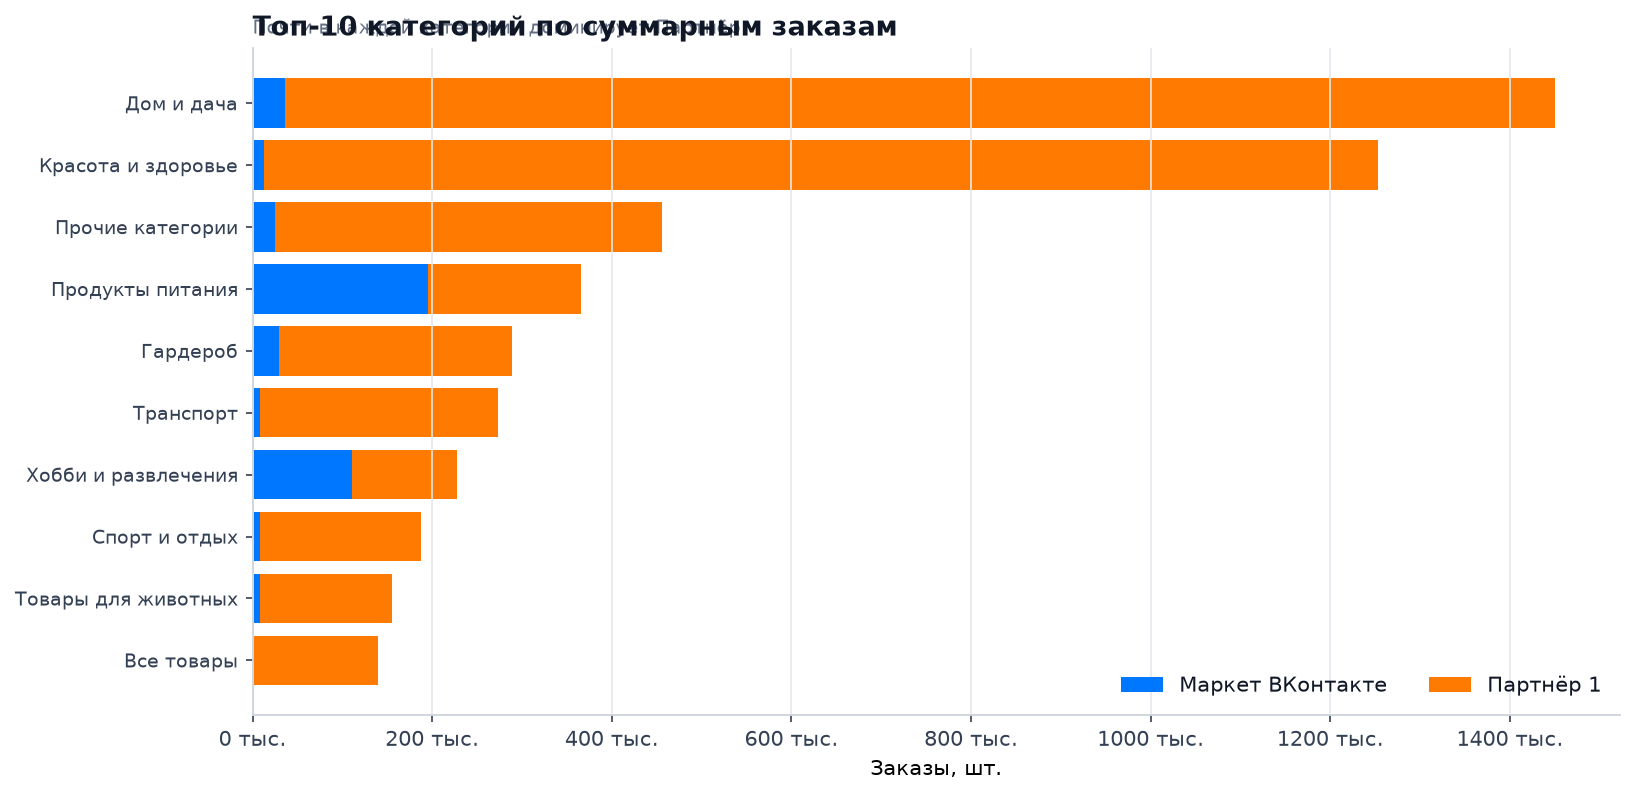

In [58]:
# --- Структура заказов по категориям ----------------------------------------
top_cat = cat.nlargest(10, 'Заказы всего')[['Категория','Заказы: Маркет Вконтакте','Заказы: Партнёр 1']].copy()
other = cat[~cat['Категория'].isin(top_cat['Категория'])][['Заказы: Маркет Вконтакте','Заказы: Партнёр 1']].sum()
top_cat.loc[len(top_cat)] = ['Прочие категории', other['Заказы: Маркет Вконтакте'], other['Заказы: Партнёр 1']]
top_cat['Всего'] = top_cat['Заказы: Маркет Вконтакте'] + top_cat['Заказы: Партнёр 1']
top_cat = top_cat.sort_values('Всего')

fig, ax = plt.subplots(figsize=(11, 5.4))
y = np.arange(len(top_cat))
ax.barh(y, top_cat['Заказы: Маркет Вконтакте'], color=C_VK, label='Маркет ВКонтакте')
ax.barh(y, top_cat['Заказы: Партнёр 1'], left=top_cat['Заказы: Маркет Вконтакте'], color=C_PT, label='Партнёр 1')
ax.set_yticks(y); ax.set_yticklabels(top_cat['Категория'], fontsize=9)
ax.set_xlabel('Заказы, шт.')
ax.set_title('Топ-10 категорий по суммарным заказам')
subtitle(ax, 'Почти в каждой категории доминирует Партнёр')
ax.legend(ncol=2, loc='lower right')
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{v/1e3:.0f} тыс.'))
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к структуре заказов.** Горизонтальные стопки: синяя часть — заказы Маркета, оранжевая — Партнёра, длина — суммарные заказы категории. Визуально оранжевый доминирует везде, кроме «Продуктов питания» и «Хобби», где вклад Маркета заметен. В «Доме и даче» доля Маркета менее 3%, в «Красоте» — около 1%. Это ещё один разрез той же закономерности: **Маркет удерживает лишь несколько ниш, Партнёр забирает массовый спрос**.

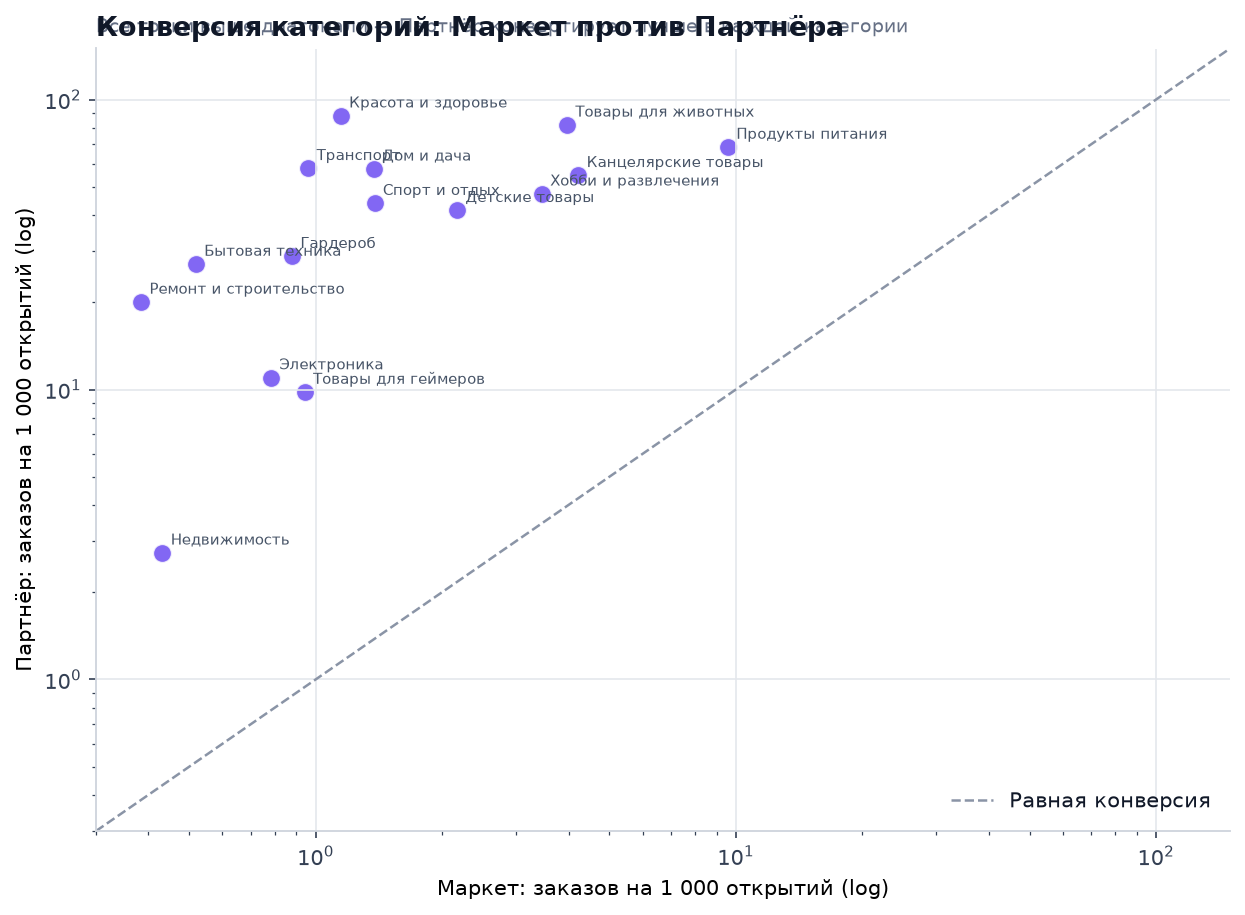

In [59]:
# --- Конверсия: Маркет vs Партнёр, scatter ----------------------------------
fig, ax = plt.subplots(figsize=(8.4, 6.2))
ax.scatter(cat_real['CR_VK_1000'], cat_real['CR_PT_1000'], s=80, color=C_ACC,
           alpha=0.85, edgecolors='white', linewidths=0.9)
lim = [0.3, 150]
ax.plot(lim, lim, color=C_GRAY, ls='--', lw=1.2, label='Равная конверсия')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlim(*lim); ax.set_ylim(*lim)
for _, r in cat_real.iterrows():
    ax.annotate(r['Категория'], (r['CR_VK_1000'], r['CR_PT_1000']), fontsize=7,
                color='#475467', xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('Маркет: заказов на 1 000 открытий (log)')
ax.set_ylabel('Партнёр: заказов на 1 000 открытий (log)')
ax.set_title('Конверсия категорий: Маркет против Партнёра')
subtitle(ax, 'Все точки выше диагонали — Партнёр конвертирует лучше в каждой категории')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

**Легенда к scatter конверсий.** Оси — конверсия в заказах на 1 000 открытий, обе логарифмические; пунктир — линия равной конверсии. **Все 15 товарных категорий лежат выше диагонали** — ни в одной Маркет не конвертирует лучше Партнёра. Ближе всего к диагонали «Недвижимость» (отношение 6,3) и «Продукты питания» (Маркет 9,6 против Партнёра 68,5; отношение 7,2); дальше всего «Красота и здоровье» (отношение 76,6). Это самое сильное доказательство того, что разрыв носит системный, а не категорийный характер.

## 6. Таблица 6 «Покупатели»: пол и возраст

15 сегментов: 2 пола × 7 возрастных групп, включая «н/д». Для каждого — покупатели и заказы в двух сегментах. Суммы по таблице совпадают с листом регионов (295 850 покупателей Маркета и 2 901 162 Партнёра), но меньше итоговых 296 148 и 2 901 334 — разница приходится на группы менее 100 человек, отсечённые при выгрузке.

In [60]:
# --- Демография: подготовка --------------------------------------------------
AGE_ORDER = ['до 18', '18–24', '25–34', '35–44', '45–54', '55+']
dem = dem.copy()
dem_clean = dem[dem['Возраст'].isin(AGE_ORDER)].copy()
dem_clean['Пол'] = dem_clean['Пол'].map({'Ж':'Женщины', 'М':'Мужчины'}).fillna(dem_clean['Пол'])

dem_age = (dem_clean.groupby('Возраст')
           .agg(Покупатели_Маркет=('Покупатели: Маркет Вконтакте','sum'),
                Заказы_Маркет=('Заказы: Маркет Вконтакте','sum'),
                Покупатели_Партнёр=('Покупатели: Партнёр 1','sum'),
                Заказы_Партнёр=('Заказы: Партнёр 1','sum'))
           .reindex(AGE_ORDER))

print('Покупатели по полу:')
display(dem_clean.groupby('Пол')[['Покупатели: Маркет Вконтакте','Покупатели: Партнёр 1']].sum().style.format('{:,.0f}'))
print('Отсечено как «н/д» или <100:',
      int(dem['Покупатели: Маркет Вконтакте'].sum() - dem_clean['Покупатели: Маркет Вконтакте'].sum()), 'покупателей Маркета')

Покупатели по полу:


,Покупатели: Маркет Вконтакте,Покупатели: Партнёр 1
Пол,,
Женщины,"215,262","2,157,612"
Мужчины,"80,454","739,863"


Отсечено как «н/д» или <100: 134 покупателей Маркета


**Легенда к подготовке демографии.** Из 15 строк оставлены 12: два пола × шесть возрастных групп. Строки «н/д» исключены из графиков, но их вклад мал (менее 0,1%). Женщины — 215 396 покупателей Маркета (72,8%) и 2 160 494 Партнёра (74,5%). Мужчины — 80 454 (27,2%) и 740 511 (25,5%). Гендерный баланс у сегментов почти одинаковый, а вот возрастной — сильно разный, и это следующий график.

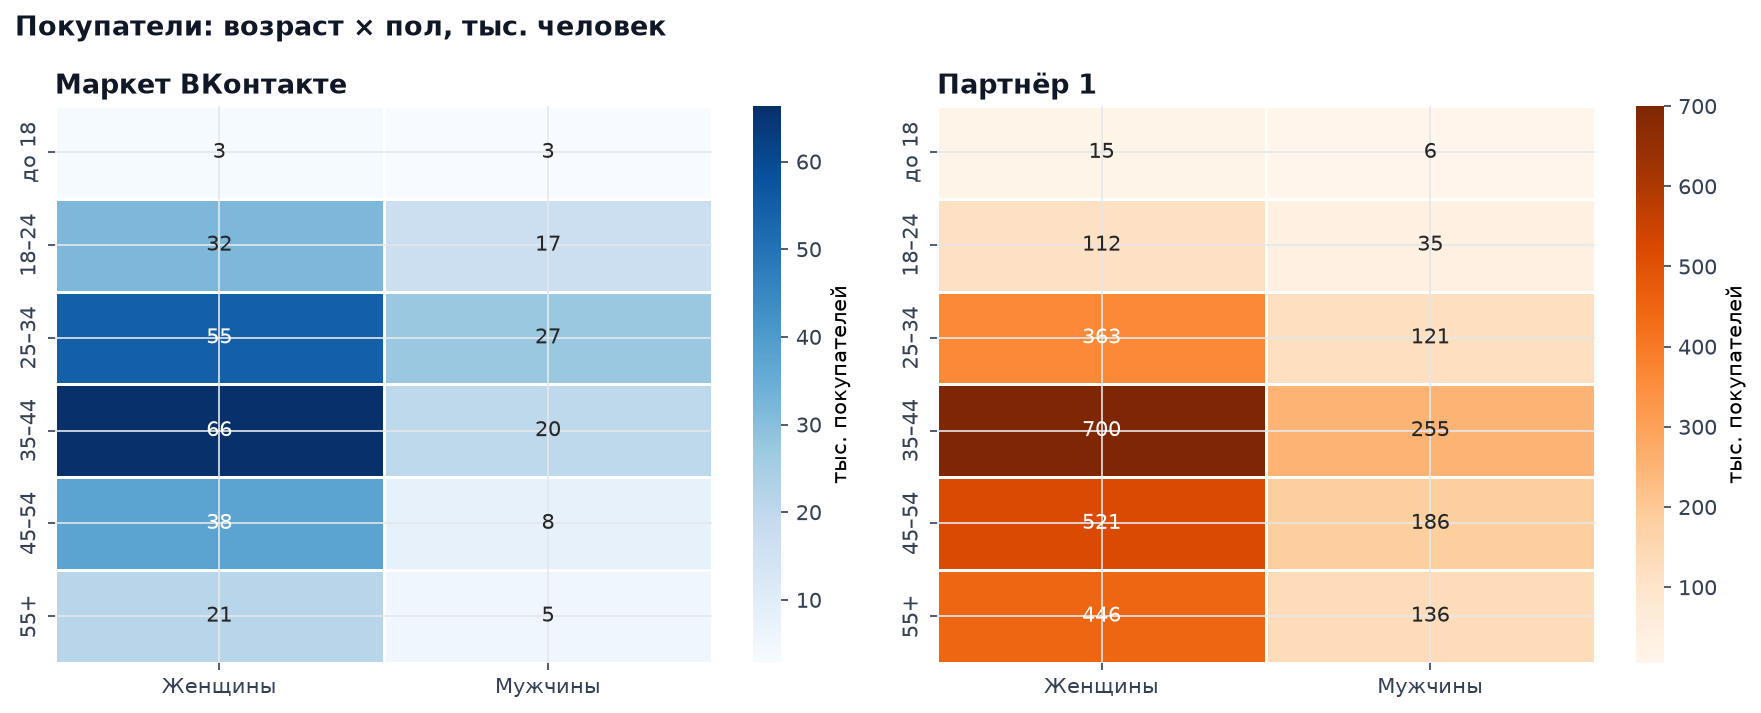

Доля 35–44 лет — Маркет: 29,3% | Партнёр: 33,0%
Доля 55+ — Маркет: 9,0% | Партнёр: 20,1%


In [61]:
# --- Теплокарта: покупатели Маркета, возраст × пол --------------------------
piv_vk = dem_clean.pivot_table(index='Возраст', columns='Пол',
                               values='Покупатели: Маркет Вконтакте', aggfunc='sum').reindex(AGE_ORDER)
piv_pt = dem_clean.pivot_table(index='Возраст', columns='Пол',
                               values='Покупатели: Партнёр 1', aggfunc='sum').reindex(AGE_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, piv, ttl, cmap in [(axes[0], piv_vk, 'Маркет ВКонтакте', 'Blues'),
                           (axes[1], piv_pt, 'Партнёр 1', 'Oranges')]:
    sns.heatmap(piv/1e3, annot=True, fmt='.0f', cmap=cmap, ax=ax, linewidths=1.2, linecolor='white',
                cbar_kws={'label':'тыс. покупателей'}, annot_kws={'fontsize':10})
    ax.set_title(ttl)
    ax.set_xlabel('')
    ax.set_ylabel('')
fig.suptitle('Покупатели: возраст × пол, тыс. человек', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

print('Доля 35–44 лет — Маркет:',
      fpct(dem_age.loc['35–44','Покупатели_Маркет']/dem_age['Покупатели_Маркет'].sum()*100),
      '| Партнёр:', fpct(dem_age.loc['35–44','Покупатели_Партнёр']/dem_age['Покупатели_Партнёр'].sum()*100))
print('Доля 55+ — Маркет:',
      fpct(dem_age.loc['55+','Покупатели_Маркет']/dem_age['Покупатели_Маркет'].sum()*100),
      '| Партнёр:', fpct(dem_age.loc['55+','Покупатели_Партнёр']/dem_age['Покупатели_Партнёр'].sum()*100))

**Легенда к теплокартам демографии.** Строки — возрастные группы, столбцы — пол, цвет и число — тысячи покупателей. Левая карта — Маркет, правая — Партнёр. У Маркета максимум — женщины 35–44 (66,3 тыс.), затем женщины 25–34 (54,6 тыс.) и 45–54 (37,8 тыс.). У Партнёра тот же лидер — женщины 35–44 (700,0 тыс.), но заметно выше группа 55+ (446,2 тыс. женщин). Мужчины 45–54 у Партнёра (186,3 тыс.) в 23 раза многочисленнее, чем у Маркета (8,0 тыс.). **Аудитория Партнёра старше и шире; Маркет — моложе и уже.**

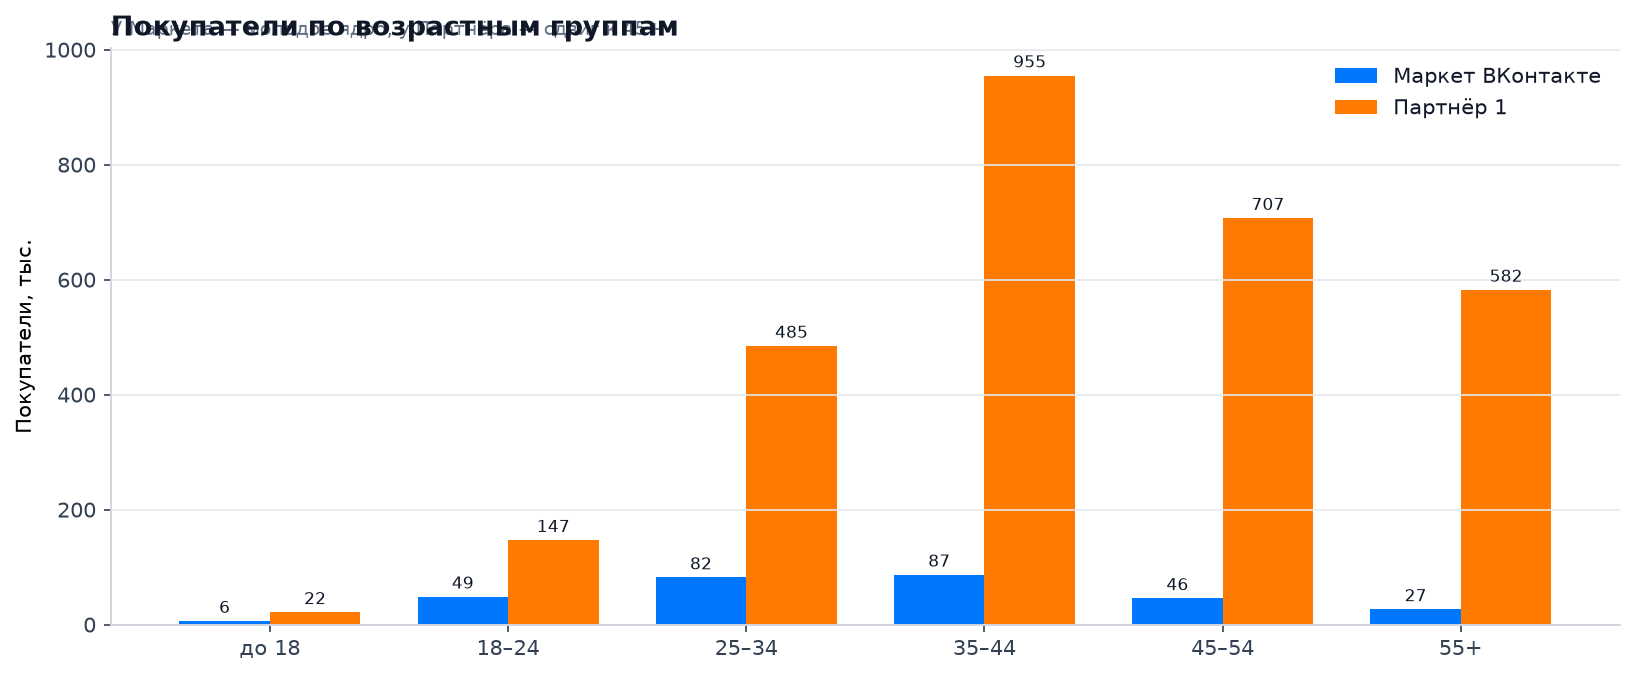

,"Маркет, %","Партнёр, %"
Возраст,,
до 18,2.1,0.7
18–24,16.4,5.1
25–34,27.7,16.7
35–44,29.3,33.0
45–54,15.5,24.4
55+,9.0,20.1


In [62]:
# --- Покупатели по возрастным группам ---------------------------------------
fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(AGE_ORDER)); w = 0.38
b1 = ax.bar(x-w/2, dem_age['Покупатели_Маркет']/1e3, w, color=C_VK, label='Маркет ВКонтакте')
b2 = ax.bar(x+w/2, dem_age['Покупатели_Партнёр']/1e3, w, color=C_PT, label='Партнёр 1')
ax.set_xticks(x); ax.set_xticklabels(AGE_ORDER)
ax.set_ylabel('Покупатели, тыс.')
ax.set_title('Покупатели по возрастным группам')
subtitle(ax, 'У Маркета — молодое ядро, у Партнёра — сдвиг к 45+')
for bars in (b1, b2):
    ax.bar_label(bars, fmt='%.0f', fontsize=8, padding=2)
ax.legend()
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

share_age = pd.DataFrame({
    'Маркет, %': dem_age['Покупатели_Маркет']/dem_age['Покупатели_Маркет'].sum()*100,
    'Партнёр, %': dem_age['Покупатели_Партнёр']/dem_age['Покупатели_Партнёр'].sum()*100,
}).round(1)
display(share_age)

**Легенда к возрастным группам.** Сгруппированные столбцы: синий — Маркет, оранжевый — Партнёр, в тысячах покупателей. У Маркета пик — 35–44 (86,7 тыс.; 29,3%), затем 25–34 (82,0 тыс.; 27,7%) и 18–24 (48,5 тыс.; 16,4%). У Партнёра пик тоже 35–44 (955,0 тыс.; 33,0%), но дальше 55+ (582,3 тыс.; 20,1%) и 45–54 (707,1 тыс.; 24,4%). Доля 18–24 у Партнёра всего 5,1% против 16,4% у Маркета. **Маркет привлекает молодёжь, Партнёр — платёжеспособную аудиторию 35+.**

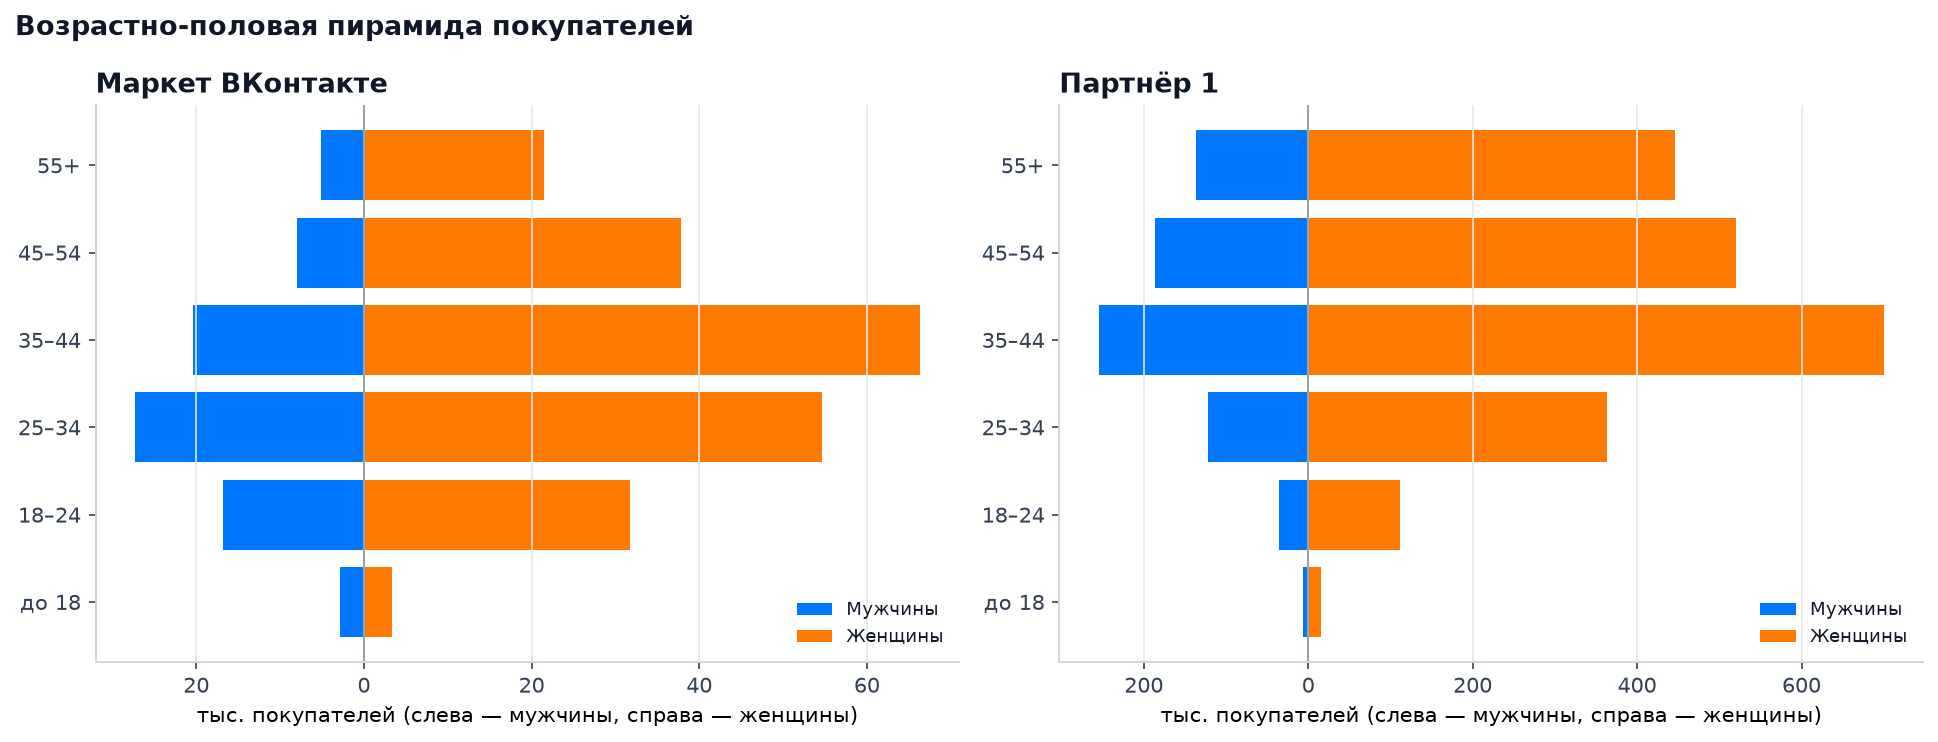

In [63]:
# --- Возрастная пирамида покупателей ----------------------------------------
male_vk = dem_clean[dem_clean['Пол']=='Мужчины'].set_index('Возраст')['Покупатели: Маркет Вконтакте'].reindex(AGE_ORDER).fillna(0)
female_vk = dem_clean[dem_clean['Пол']=='Женщины'].set_index('Возраст')['Покупатели: Маркет Вконтакте'].reindex(AGE_ORDER).fillna(0)
male_pt = dem_clean[dem_clean['Пол']=='Мужчины'].set_index('Возраст')['Покупатели: Партнёр 1'].reindex(AGE_ORDER).fillna(0)
female_pt = dem_clean[dem_clean['Пол']=='Женщины'].set_index('Возраст')['Покупатели: Партнёр 1'].reindex(AGE_ORDER).fillna(0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, male, female, ttl in [(axes[0], male_vk, female_vk, 'Маркет ВКонтакте'),
                              (axes[1], male_pt, female_pt, 'Партнёр 1')]:
    y = np.arange(len(AGE_ORDER))
    ax.barh(y, -male/1e3, color=C_VK, label='Мужчины')
    ax.barh(y, female/1e3, color=C_PT, label='Женщины')
    ax.set_yticks(y); ax.set_yticklabels(AGE_ORDER)
    ax.axvline(0, color='#98A2B3', lw=1)
    ax.set_title(ttl)
    ax.set_xlabel('тыс. покупателей (слева — мужчины, справа — женщины)')
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{abs(v):.0f}'))
    ax.grid(axis='y', visible=False)
    ax.legend(loc='lower right', fontsize=8.5)
fig.suptitle('Возрастно-половая пирамида покупателей', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

**Легенда к пирамиде.** Классическая пирамида: слева мужчины (синий), справа женщины (оранжевый), по вертикали — возраст. Левая панель — Маркет, правая — Партнёр. У Маркета пирамида «молодая» и узкая: основная масса сосредоточена в 25–44, к 55+ резко сужается. У Партнёра — «зрелая» и широкая: 35–54 и 55+ сопоставимы по массе. Женщины доминируют в обеих моделях, но у Партнёра разрыв между полами меньше в старших группах.

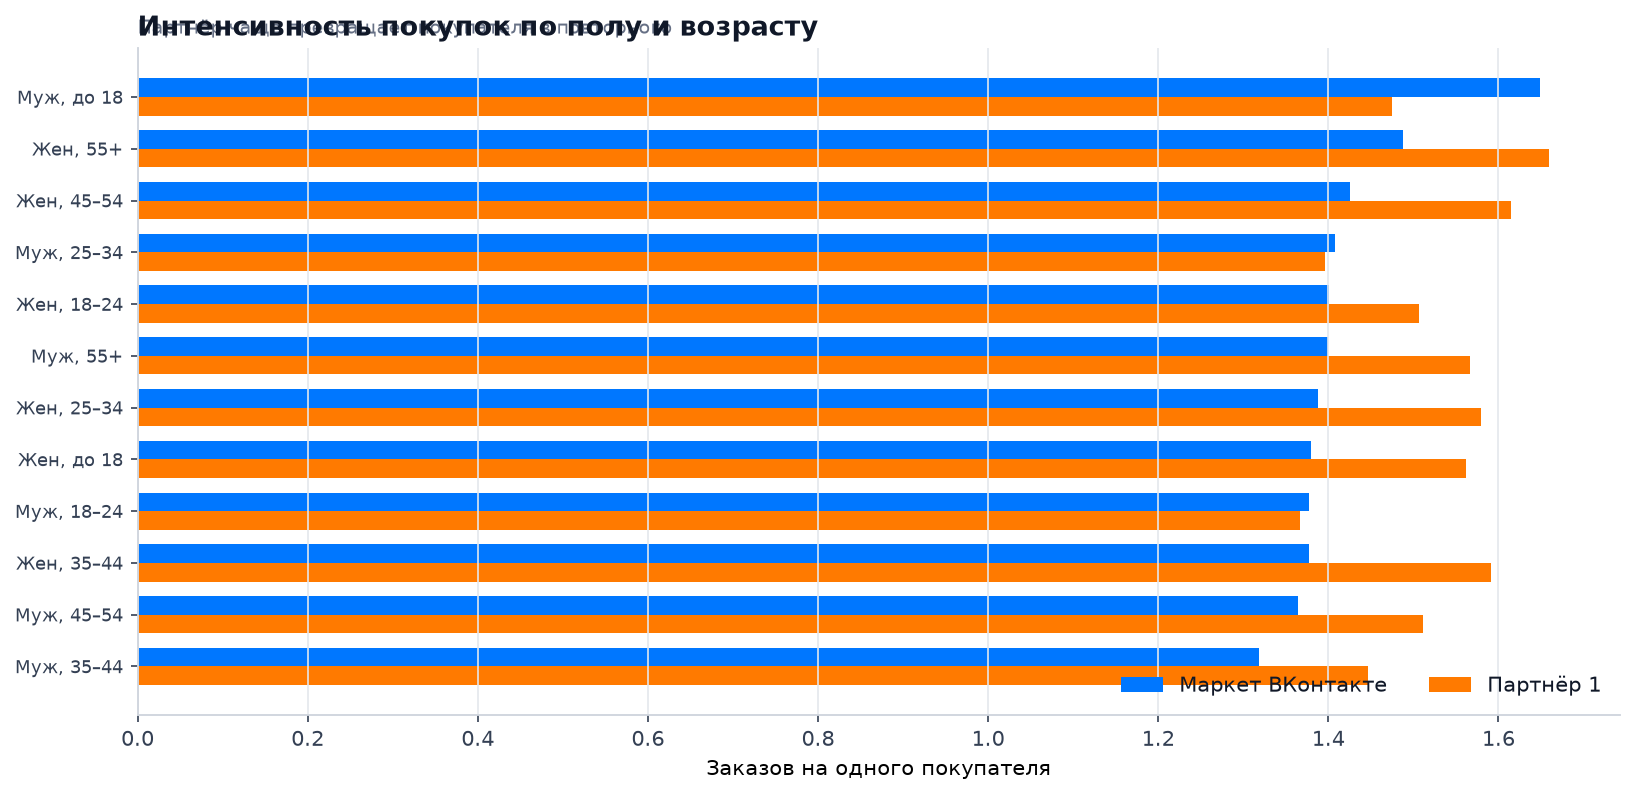

Среднее заказов на покупателя — Маркет: 1.4 | Партнёр: 1.57


In [64]:
# --- Заказы на покупателя по сегментам --------------------------------------
opb = dem_clean.copy()
opb['OPB_VK'] = opb['Заказы: Маркет Вконтакте'] / opb['Покупатели: Маркет Вконтакте']
opb['OPB_PT'] = opb['Заказы: Партнёр 1'] / opb['Покупатели: Партнёр 1']
opb['Сегмент'] = opb['Пол'].str[:3] + ', ' + opb['Возраст']
opb = opb.sort_values('OPB_VK')

fig, ax = plt.subplots(figsize=(11, 5.4))
y = np.arange(len(opb)); h = 0.36
ax.barh(y+h/2, opb['OPB_VK'], h, color=C_VK, label='Маркет ВКонтакте')
ax.barh(y-h/2, opb['OPB_PT'], h, color=C_PT, label='Партнёр 1')
ax.set_yticks(y); ax.set_yticklabels(opb['Сегмент'], fontsize=8.5)
ax.set_xlabel('Заказов на одного покупателя')
ax.set_title('Интенсивность покупок по полу и возрасту')
subtitle(ax, 'Партнёр чаще превращает покупателя в повторного')
ax.legend(ncol=2, loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Среднее заказов на покупателя — Маркет:',
      round(dem_clean['Заказы: Маркет Вконтакте'].sum()/dem_clean['Покупатели: Маркет Вконтакте'].sum(),2),
      '| Партнёр:', round(dem_clean['Заказы: Партнёр 1'].sum()/dem_clean['Покупатели: Партнёр 1'].sum(),2))

**Легенда к интенсивности покупок.** Горизонтальные пары: для каждого пола и возраста — сколько заказов приходится на одного покупателя. У Маркета почти все сегменты в коридоре 1,3–1,7; у Партнёра — 1,4–1,7. Максимум у Партнёра — женщины 55+ (1,66); у Маркета выделяются мужчины до 18 (1,65, но на очень малой базе) и женщины 55+ (1,49). Разница невелика, но устойчива: **Партнёр лучше удерживает и возвращает покупателя**, что согласуется с долей повторных покупок 26,6% против 19,0%.

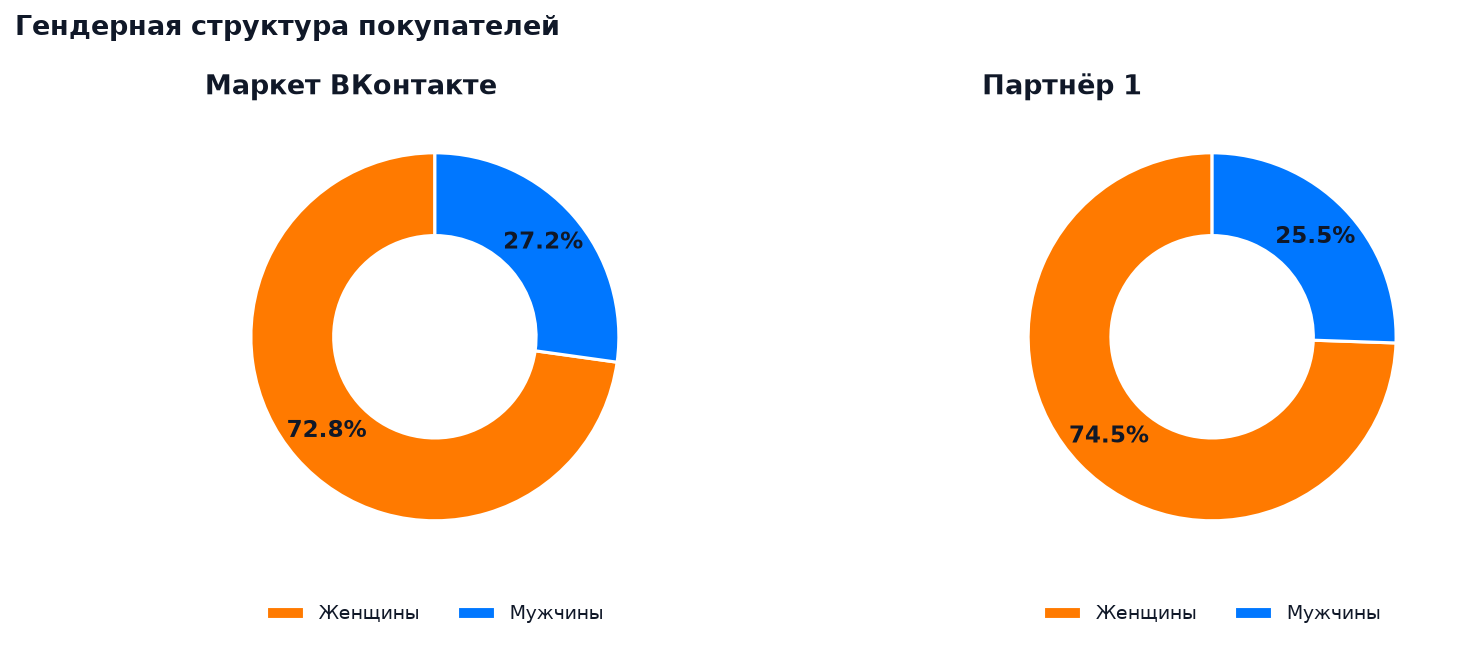

In [65]:
# --- Гендерная структура -----------------------------------------------------
gv_vk = dem_clean.groupby('Пол')[['Покупатели: Маркет Вконтакте','Заказы: Маркет Вконтакте']].sum()
gv_pt = dem_clean.groupby('Пол')[['Покупатели: Партнёр 1','Заказы: Партнёр 1']].sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, g, col, ttl in [(axes[0], gv_vk, 'Покупатели: Маркет Вконтакте', 'Маркет ВКонтакте'),
                        (axes[1], gv_pt, 'Покупатели: Партнёр 1', 'Партнёр 1')]:
    vals = g[col]
    ax.pie(vals, labels=None, colors=[C_PT, C_VK], startangle=90, autopct='%1.1f%%',
           wedgeprops=dict(width=0.45, edgecolor='white', linewidth=1.5), pctdistance=0.78,
           textprops=dict(fontsize=11, fontweight='bold'))
    ax.set_title(ttl)
    ax.legend(vals.index, loc='lower center', bbox_to_anchor=(0.5, -0.16), ncol=2, fontsize=9)
fig.suptitle('Гендерная структура покупателей', fontsize=13, fontweight='bold', x=0.01, ha='left')
plt.tight_layout()
plt.show()

**Легенда к гендерной структуре.** Две кольцевые диаграммы: слева Маркет, справа Партнёр; оранжевый — женщины, синий — мужчины. Женщины составляют 72,8% покупателей Маркета и 74,5% Партнёра. Разница 1,7 п.п. статистически незначима. **Пол не различает сегменты — различает возраст и модель покупки.** Это полезно для коммуникаций: гендерный таргетинг не даст прироста, возрастной — даст.

## 7. Таблица 7 «Покупатели по регионам»: география

89 строк: 88 регионов и «Не указан». Суммы совпадают с демографией: 295 850 покупателей Маркета и 2 901 162 Партнёра. Главная особенность — **36,7% покупателей Партнёра не имеют региона** (1 065 094 человека). Это ограничивает географический анализ, поэтому топ-регионы считаются без «Не указан», а его доля показывается отдельно.

In [66]:
# --- Регионы: подготовка -----------------------------------------------------
reg = reg.copy()
UNKNOWN = 'Не указан'
reg_known = reg[reg['Регион'] != UNKNOWN].copy()
reg_unknown = reg[reg['Регион'] == UNKNOWN].iloc[0]

print('Регионов (без «Не указан»):', len(reg_known))
print('Доля «Не указан» — Маркет:',
      fpct(reg_unknown['Покупатели: Маркет Вконтакте']/reg['Покупатели: Маркет Вконтакте'].sum()*100),
      '| Партнёр:',
      fpct(reg_unknown['Покупатели: Партнёр 1']/reg['Покупатели: Партнёр 1'].sum()*100))
print('Топ-5 регионов Маркета:')
print(reg_known.nlargest(5,'Покупатели: Маркет Вконтакте')[['Регион','Покупатели: Маркет Вконтакте','Заказы: Маркет Вконтакте']].to_string(index=False))

Регионов (без «Не указан»): 88
Доля «Не указан» — Маркет: 1,8% | Партнёр: 36,7%
Топ-5 регионов Маркета:
              Регион  Покупатели: Маркет Вконтакте  Заказы: Маркет Вконтакте
           г. Москва                       30488.0                   42652.0
  г. Санкт-Петербург                       24687.0                   36107.0
 Челябинская область                       20465.0                   28558.0
       Пермский край                       13366.0                   19489.0
Свердловская область                       11117.0                   15626.0


**Легенда к подготовке регионов.** 88 регионов после исключения «Не указан». Доля неизвестных: 1,8% у Маркета (5 189 человек) и 36,7% у Партнёра (1 065 094). Это не случайные пропуски: скорее всего, часть заказов Партнёра оформляется без передачи геоданных. Топ-5 Маркета: Москва (30 488), Санкт-Петербург (24 687), Челябинская область (20 465), Пермский край (13 366), Свердловская область (11 117). Обратите внимание на Челябинскую область — она выше многих миллионников, что требует проверки.

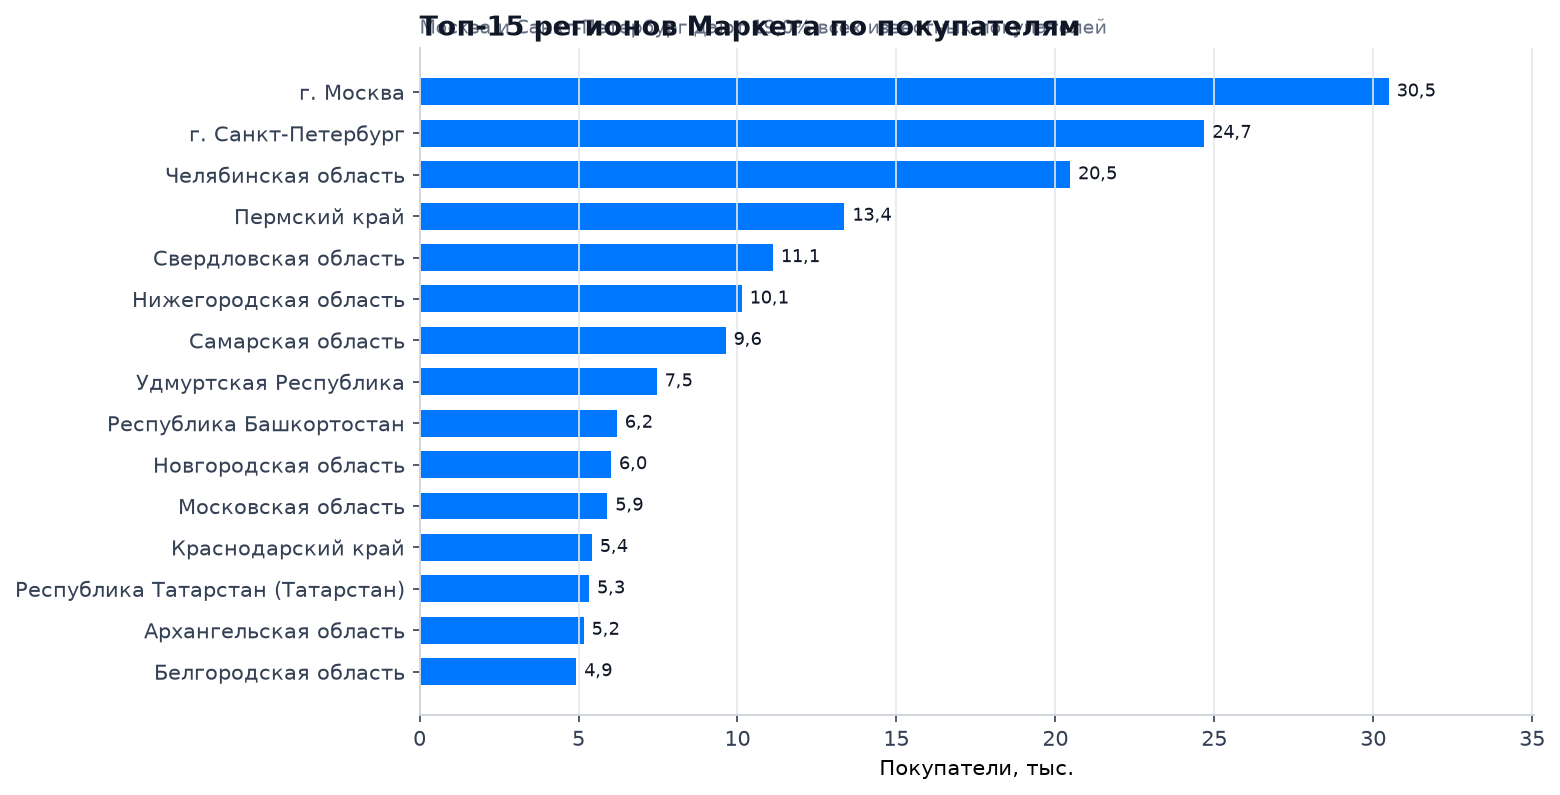

Доля топ-10 регионов в покупателях Маркета: 47,2%


In [67]:
# --- Топ-15 регионов Маркета -------------------------------------------------
top_vk = reg_known.nlargest(15, 'Покупатели: Маркет Вконтакте').sort_values('Покупатели: Маркет Вконтакте')
fig, ax = plt.subplots(figsize=(10.5, 5.4))
bars = ax.barh(top_vk['Регион'], top_vk['Покупатели: Маркет Вконтакте']/1e3, color=C_VK, height=0.65)
ax.set_xlabel('Покупатели, тыс.')
ax.set_title('Топ-15 регионов Маркета по покупателям')
subtitle(ax, 'Москва и Санкт-Петербург дают 19,0% всех известных покупателей')
for b, v in zip(bars, top_vk['Покупатели: Маркет Вконтакте']/1e3):
    ax.text(v+0.25, b.get_y()+b.get_height()/2, f'{v:.1f}'.replace('.', ','), va='center', fontsize=8.5)
ax.set_xlim(0, (top_vk['Покупатели: Маркет Вконтакте']/1e3).max()*1.15)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Доля топ-10 регионов в покупателях Маркета:',
      fpct(reg_known.nlargest(10,'Покупатели: Маркет Вконтакте')['Покупатели: Маркет Вконтакте'].sum()/reg['Покупатели: Маркет Вконтакте'].sum()*100))

**Легенда к топ-15 регионов Маркета.** Горизонтальные столбцы, тыс. покупателей. Лидеры: Москва 30,5 тыс., Санкт-Петербург 24,7 тыс., Челябинская область 20,5 тыс., Пермский край 13,4 тыс., Свердловская область 11,1 тыс. Топ-10 дают 47,2% всех покупателей Маркета. Распределение похоже на население, но с аномалиями: Челябинская и Пермская области выше своих долей населения, Московская область — ниже (5,9 тыс., 11-е место). Это может отражать как реальный спрос, так и особенности выгрузки.

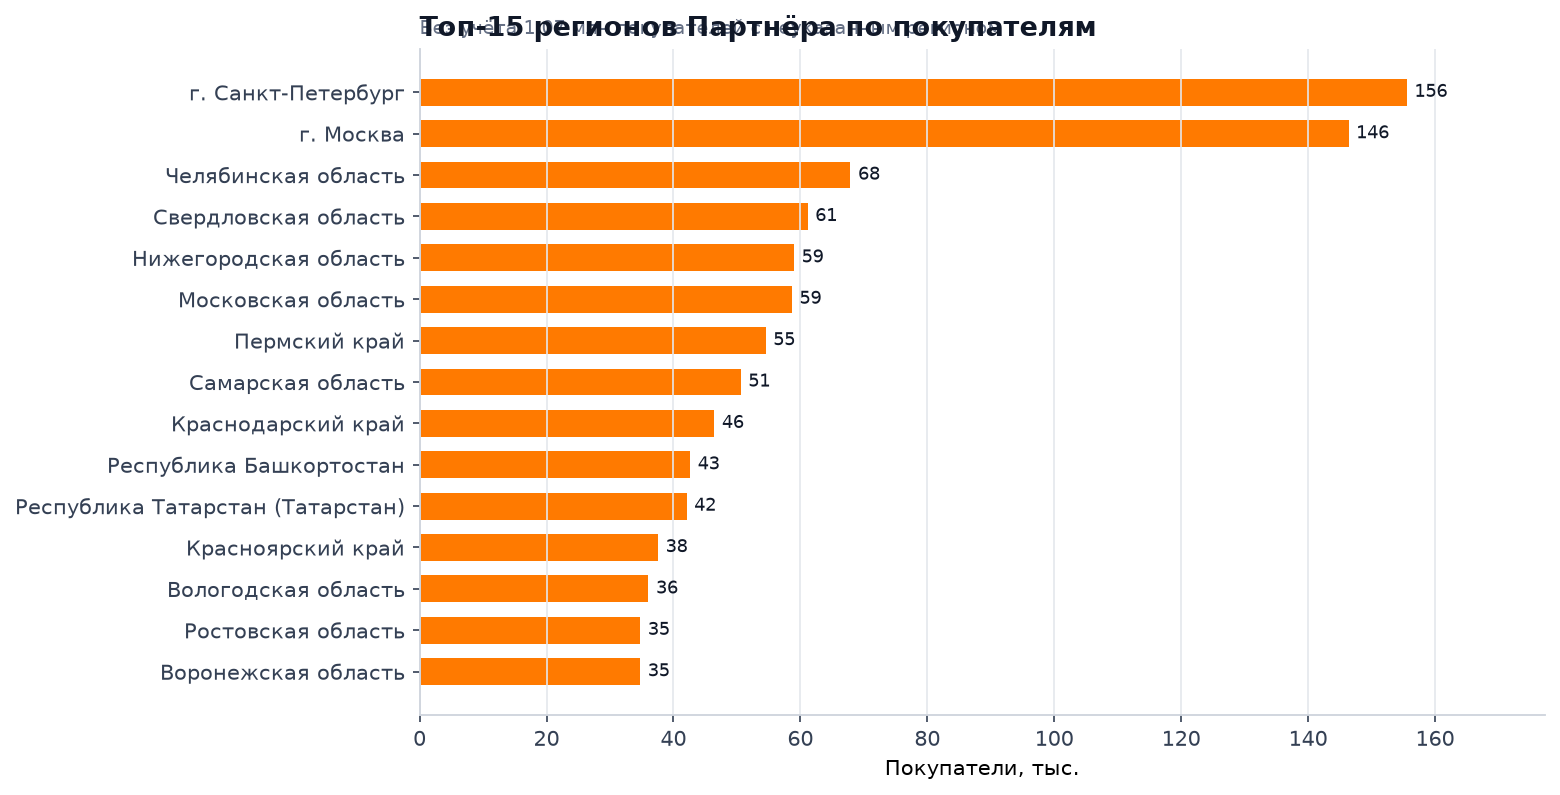

Доля топ-10 регионов в покупателях Партнёра (без «Не указан»): 40,5%


In [68]:
# --- Топ-15 регионов Партнёра -----------------------------------------------
top_pt = reg_known.nlargest(15, 'Покупатели: Партнёр 1').sort_values('Покупатели: Партнёр 1')
fig, ax = plt.subplots(figsize=(10.5, 5.4))
bars = ax.barh(top_pt['Регион'], top_pt['Покупатели: Партнёр 1']/1e3, color=C_PT, height=0.65)
ax.set_xlabel('Покупатели, тыс.')
ax.set_title('Топ-15 регионов Партнёра по покупателям')
subtitle(ax, 'Без учёта 1,07 млн покупателей с неуказанным регионом')
for b, v in zip(bars, top_pt['Покупатели: Партнёр 1']/1e3):
    ax.text(v+1.2, b.get_y()+b.get_height()/2, f'{v:.0f}', va='center', fontsize=8.5)
ax.set_xlim(0, (top_pt['Покупатели: Партнёр 1']/1e3).max()*1.14)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Доля топ-10 регионов в покупателях Партнёра (без «Не указан»):',
      fpct(reg_known.nlargest(10,'Покупатели: Партнёр 1')['Покупатели: Партнёр 1'].sum()/reg_known['Покупатели: Партнёр 1'].sum()*100))

**Легенда к топ-15 регионов Партнёра.** Те же оси, оранжевые столбцы. Лидеры: Санкт-Петербург 155,5 тыс., Москва 146,4 тыс., Челябинская 67,9 тыс., Свердловская 61,1 тыс., Нижегородская 59,0 тыс. Топ-10 дают 40,5% известных покупателей. Структура заметно ровнее, чем у Маркета: нет столичной доминанты, сильны промышленные регионы Урала и Поволжья. Челябинская область снова третья — совпадение с Маркетом, которое сложно объяснить только населением.

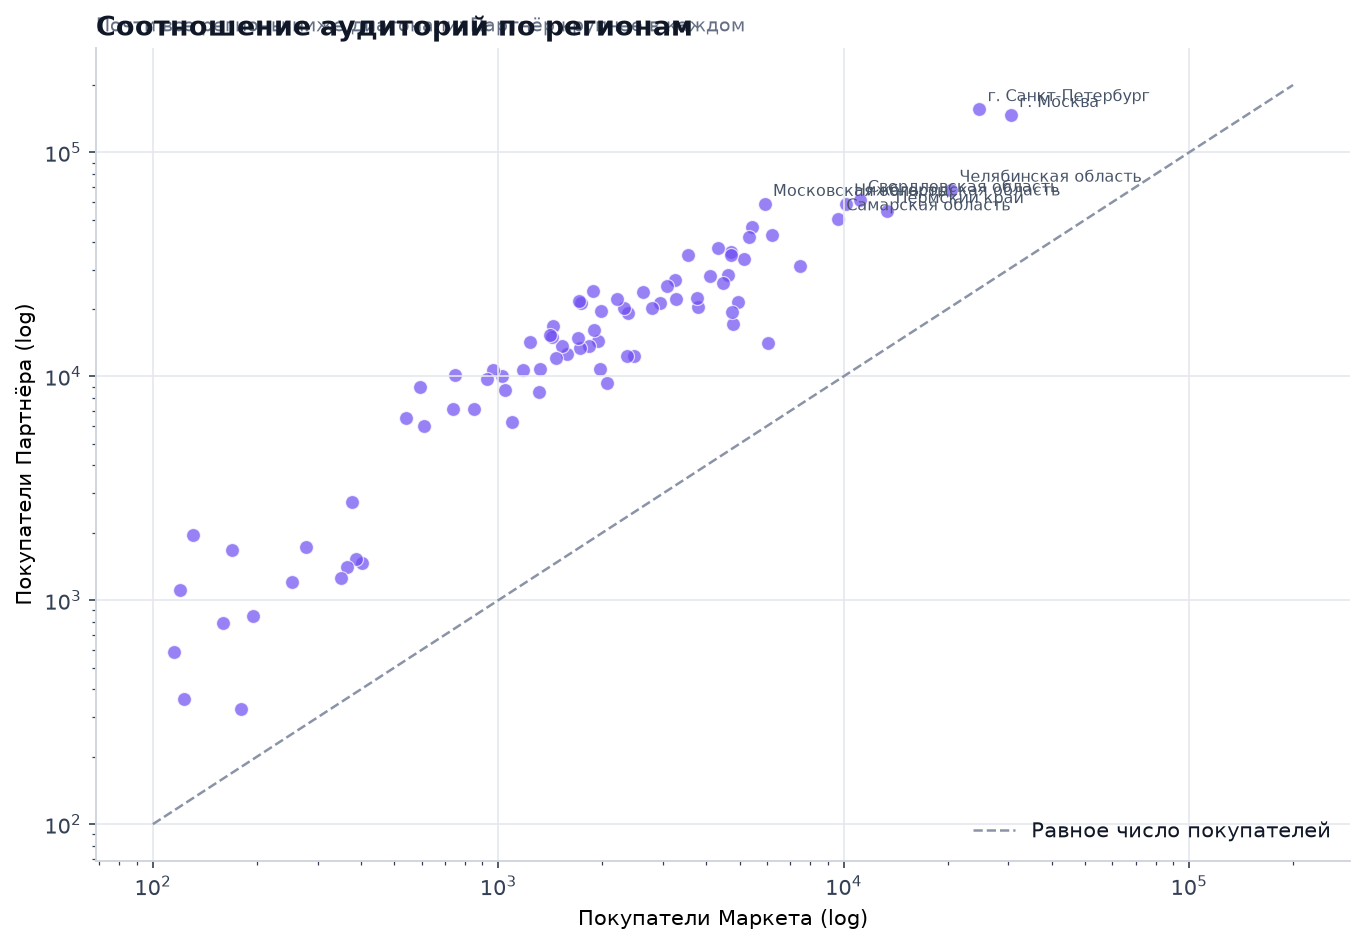

Медианное отношение Партнёр/Маркет по регионам: 7.43
Регионы с наименьшим отношением:
              Регион  ratio
Чеченская Республика   1.81
Новгородская область   2.33
 Запорожская область   2.95
 Челябинская область   3.32


In [69]:
# --- Маркет vs Партнёр по регионам ------------------------------------------
fig, ax = plt.subplots(figsize=(9.2, 6.4))
ax.scatter(reg_known['Покупатели: Маркет Вконтакте'], reg_known['Покупатели: Партнёр 1'],
           s=45, color=C_ACC, alpha=0.7, edgecolors='white', linewidths=0.6)
ax.plot([100, 2e5], [100, 2e5], color=C_GRAY, ls='--', lw=1.2, label='Равное число покупателей')
for _, r in reg_known.nlargest(8, 'Покупатели: Партнёр 1').iterrows():
    ax.annotate(r['Регион'], (r['Покупатели: Маркет Вконтакте'], r['Покупатели: Партнёр 1']),
                fontsize=7.5, color='#475467', xytext=(4, 4), textcoords='offset points')
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Покупатели Маркета (log)')
ax.set_ylabel('Покупатели Партнёра (log)')
ax.set_title('Соотношение аудиторий по регионам')
subtitle(ax, 'Почти все регионы ниже диагонали: Партнёр крупнее в каждом')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

ratio = (reg_known['Покупатели: Партнёр 1'] / reg_known['Покупатели: Маркет Вконтакте'])
ratio_df = reg_known[['Регион']].assign(ratio=ratio).dropna().sort_values('ratio')
print('Медианное отношение Партнёр/Маркет по регионам:', round(ratio_df['ratio'].median(),2))
print('Регионы с наименьшим отношением:')
print(ratio_df.head(4).round(2).to_string(index=False))

**Легенда к регионам-сравнению.** Каждая точка — регион: по X покупатели Маркета, по Y Партнёра, обе оси логарифмические; пунктир — равенство. Почти все точки ниже диагонали: Партнёр крупнее в каждом регионе. Медианное отношение — 7,43. Ближе всего к паритету Чеченская Республика (1,81), Новгородская область (2,33) и Запорожская область (2,95); дальше всего — малые регионы, где Маркет почти не представлен. География повторяет общую закономерность: **Маркет — нишевый канал, Партнёр — массовый**.

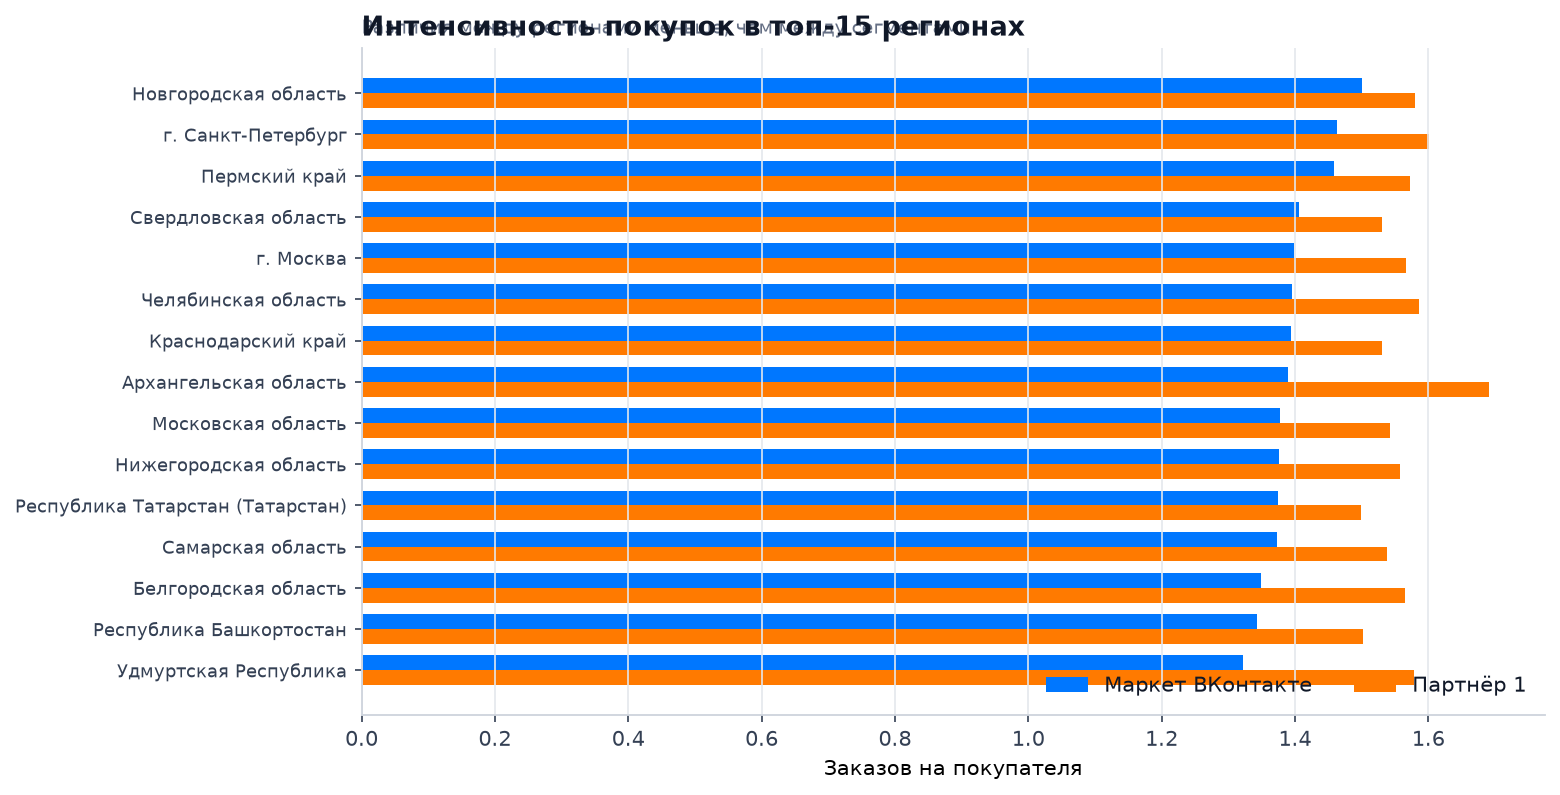

In [70]:
# --- Заказы на покупателя по регионам ---------------------------------------
top_r = reg_known.nlargest(15, 'Покупатели: Маркет Вконтакте').copy()
top_r['OPB_VK'] = top_r['Заказы: Маркет Вконтакте']/top_r['Покупатели: Маркет Вконтакте']
top_r['OPB_PT'] = top_r['Заказы: Партнёр 1']/top_r['Покупатели: Партнёр 1']
top_r = top_r.sort_values('OPB_VK')

fig, ax = plt.subplots(figsize=(10.5, 5.4))
y = np.arange(len(top_r)); h = 0.36
ax.barh(y+h/2, top_r['OPB_VK'], h, color=C_VK, label='Маркет ВКонтакте')
ax.barh(y-h/2, top_r['OPB_PT'], h, color=C_PT, label='Партнёр 1')
ax.set_yticks(y); ax.set_yticklabels(top_r['Регион'], fontsize=8.5)
ax.set_xlabel('Заказов на покупателя')
ax.set_title('Интенсивность покупок в топ-15 регионах')
subtitle(ax, 'Различия между регионами меньше, чем между сегментами')
ax.legend(ncol=2, loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

**Легенда к интенсивности по регионам.** Для топ-15 регионов Маркета — сколько заказов на покупателя в каждом сегменте. У Маркета разброс 1,32–1,50, у Партнёра 1,50–1,69. Межрегиональные различия малы по сравнению с межсегментными. Вывод: **география почти не влияет на интенсивность покупок** — влияет модель (Маркет vs Партнёр). Это упрощает планирование: не нужно строить отдельные стратегии под каждый регион, достаточно двух сегментных.

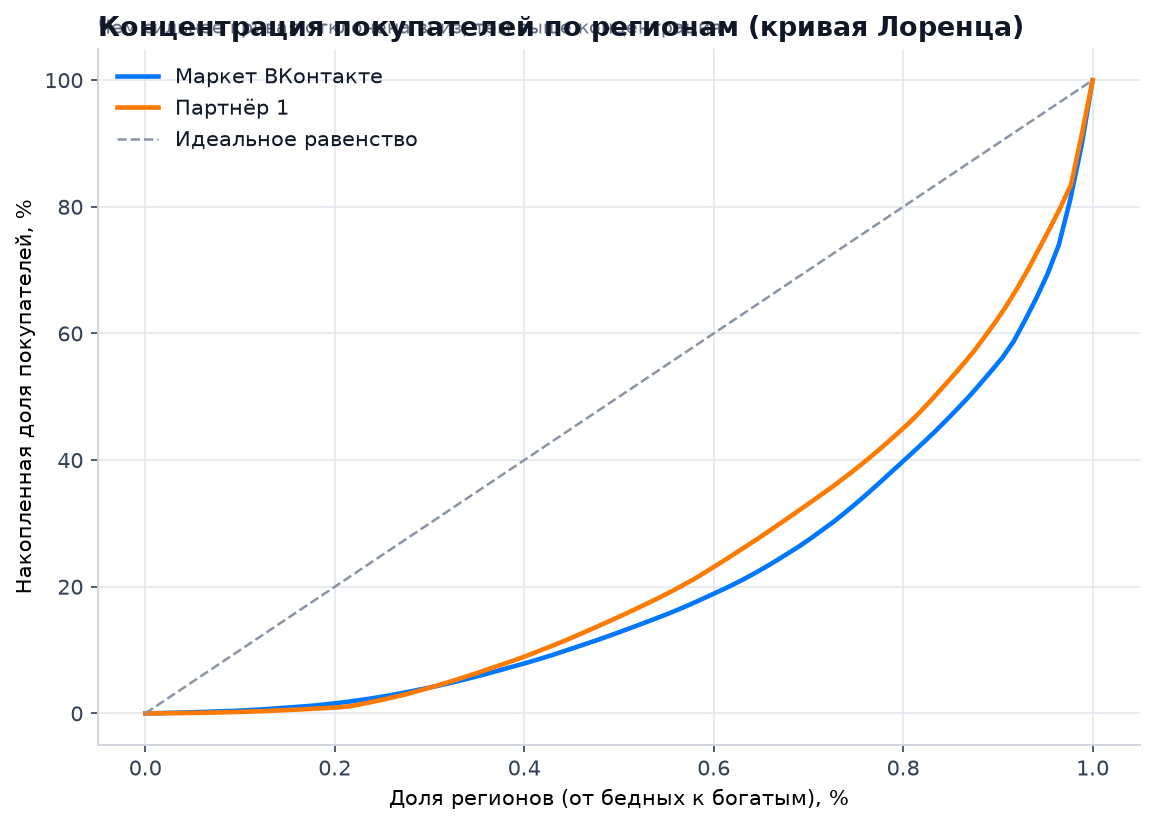

Коэффициент Джини — Маркет: 0.579 | Партнёр: 0.526


In [71]:
# --- Концентрация регионов: кривая Лоренца ----------------------------------
def lorenz(vals):
    v = np.sort(np.asarray(vals, dtype=float))
    cum = np.cumsum(v) / v.sum()
    return np.linspace(0, 1, len(v)+1), np.concatenate([[0], cum])

xv, yv = lorenz(reg_known['Покупатели: Маркет Вконтакте'].dropna())
xp, yp = lorenz(reg_known['Покупатели: Партнёр 1'].dropna())

fig, ax = plt.subplots(figsize=(7.8, 5.6))
ax.plot(xv, yv*100, color=C_VK, lw=2.2, label='Маркет ВКонтакте')
ax.plot(xp, yp*100, color=C_PT, lw=2.2, label='Партнёр 1')
ax.plot([0,1], [0,100], color=C_GRAY, ls='--', lw=1.2, label='Идеальное равенство')
ax.set_xlabel('Доля регионов (от бедных к богатым), %')
ax.set_ylabel('Накопленная доля покупателей, %')
ax.set_title('Концентрация покупателей по регионам (кривая Лоренца)')
subtitle(ax, 'Чем сильнее кривая отклонена вниз, тем выше концентрация')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

def gini(v):
    v = np.sort(np.asarray(v, dtype=float)); n = len(v)
    return (2*np.sum((np.arange(1,n+1))*v)/(n*v.sum())) - (n+1)/n
print('Коэффициент Джини — Маркет:', round(gini(reg_known['Покупатели: Маркет Вконтакте'].dropna()),3),
      '| Партнёр:', round(gini(reg_known['Покупатели: Партнёр 1'].dropna()),3))

**Легенда к кривой Лоренца.** По X — регионы, отсортированные от малых к крупным (накопленная доля), по Y — накопленная доля покупателей. Прямая — полное равенство; чем ниже кривая, тем выше концентрация. Обе кривые сильно отклонены вниз: нижние 20% регионов дают лишь 1–2% покупателей, а основная масса сосредоточена в нескольких крупных. Коэффициент Джини — 0,579 у Маркета и 0,526 у Партнёра. **Маркет сконцентрирован сильнее**: он живёт в крупных городах, тогда как Партнёр глубже проникает в регионы.

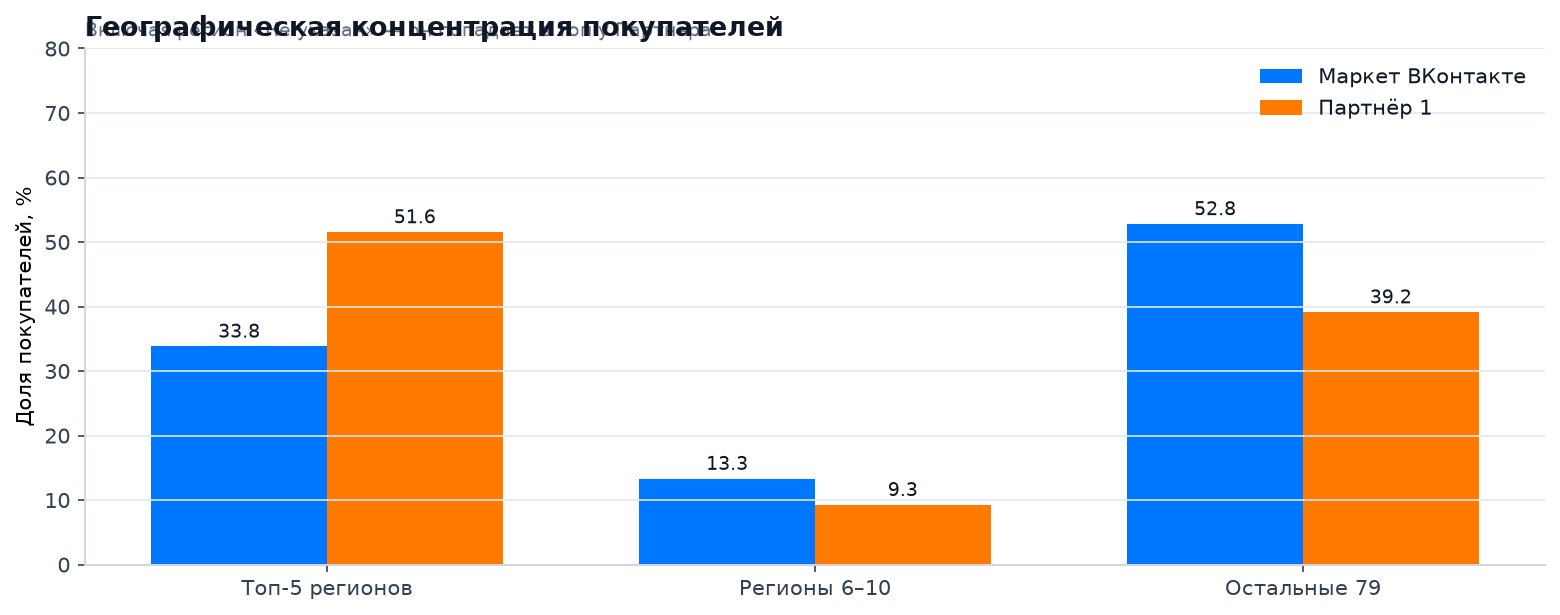

In [72]:
# --- Концентрация: топ-5, топ-10, остальные ---------------------------------
def conc(vals, total):
    s = np.sort(pd.Series(vals).dropna().astype(float).values)[::-1]
    return [s[:5].sum()/total*100, s[5:10].sum()/total*100, s[10:].sum()/total*100]

vk_c = conc(reg['Покупатели: Маркет Вконтакте'], reg['Покупатели: Маркет Вконтакте'].sum())
pt_c = conc(reg['Покупатели: Партнёр 1'], reg['Покупатели: Партнёр 1'].sum())

fig, ax = plt.subplots(figsize=(10.5, 4.2))
labels = ['Топ-5 регионов', 'Регионы 6–10', 'Остальные 79']
x = np.arange(3); w = 0.36
b1 = ax.bar(x-w/2, vk_c, w, color=C_VK, label='Маркет ВКонтакте')
b2 = ax.bar(x+w/2, pt_c, w, color=C_PT, label='Партнёр 1')
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylabel('Доля покупателей, %')
ax.set_title('Географическая концентрация покупателей')
subtitle(ax, 'Включая регион «Не указан» — он попадает в топ у Партнёра')
for bars in (b1, b2):
    ax.bar_label(bars, fmt='%.1f', fontsize=9, padding=2)
ax.legend()
ax.set_ylim(0, 80)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

**Легенда к концентрации.** Три группы регионов: топ-5, следующие пять, остальные 79; синий — Маркет, оранжевый — Партнёр. У Маркета топ-5 дают 33,8%, у Партнёра — 51,6%, но львиная доля этого — «Не указан» (36,7%). Если исключить неизвестные, концентрация Партнёра ниже. **Сравнивать концентрацию корректно только по известным регионам**: тогда Маркет концентрированнее, а Партнёр распределён ровнее. Это ещё одна иллюстрация того, как качество данных меняет вывод.

In [73]:
# --- Полная таблица регионов (топ-20) ---------------------------------------
reg_view = reg_known.nlargest(20, 'Покупатели: Маркет Вконтакте').copy()
reg_view['Заказов на покупателя VK'] = (reg_view['Заказы: Маркет Вконтакте']/reg_view['Покупатели: Маркет Вконтакте']).round(2)
reg_view['Заказов на покупателя PT'] = (reg_view['Заказы: Партнёр 1']/reg_view['Покупатели: Партнёр 1']).round(2)
reg_view['Доля VK, %'] = (reg_view['Покупатели: Маркет Вконтакте']/reg_view['Покупатели: Маркет Вконтакте'].sum()*100).round(2)
display(reg_view.style.hide(axis='index').format({
    'Покупатели: Маркет Вконтакте':'{:,.0f}','Заказы: Маркет Вконтакте':'{:,.0f}',
    'Покупатели: Партнёр 1':'{:,.0f}','Заказы: Партнёр 1':'{:,.0f}'}))

Регион,Покупатели: Маркет Вконтакте,Заказы: Маркет Вконтакте,Покупатели: Партнёр 1,Заказы: Партнёр 1,Заказов на покупателя VK,Заказов на покупателя PT,"Доля VK, %"
г. Москва,"30,488","42,652","146,366","229,256",1.400000,1.570000,16.050000
г. Санкт-Петербург,"24,687","36,107","155,546","248,956",1.460000,1.600000,13.000000
Челябинская область,"20,465","28,558","67,879","107,682",1.400000,1.590000,10.780000
Пермский край,"13,366","19,489","54,523","85,703",1.460000,1.570000,7.040000
Свердловская область,"11,117","15,626","61,132","93,602",1.410000,1.530000,5.850000
Нижегородская область,"10,136","13,948","58,993","91,907",1.380000,1.560000,5.340000
Самарская область,"9,627","13,214","50,590","77,845",1.370000,1.540000,5.070000
Удмуртская Республика,"7,458","9,862","31,199","49,233",1.320000,1.580000,3.930000
Республика Башкортостан,"6,205","8,330","42,619","64,042",1.340000,1.500000,3.270000
Новгородская область,"6,021","9,033","14,036","22,170",1.500000,1.580000,3.170000


**Легенда к таблице регионов.** Топ-20 по покупателям Маркета с производными: заказы на покупателя в каждом сегменте и доля региона в покупателях Маркета. Таблица нужна для точечных решений: например, в Москве у Маркета 30,5 тыс. покупателей и 42,7 тыс. заказов (1,40 на покупателя), а в Санкт-Петербурге — 24,7 тыс. и 36,1 тыс. (1,46). Регионы с высокой интенсивностью — кандидаты на локальные промо.

## 8. Синтез: две модели внутри одного Маркета

До этого момента таблицы анализировались по отдельности. Теперь соберём всё вместе и ответим на главный вопрос кейса: **какую роль играет Маркет ВКонтакте**.

### 8.1. Один график, который объясняет всё

Отношение показателя Маркета к показателю Партнёра: меньше единицы — Маркет отстаёт, больше — опережает. Логарифмическая шкала, чтобы 0,08 и 3,64 были видны на одном графике.

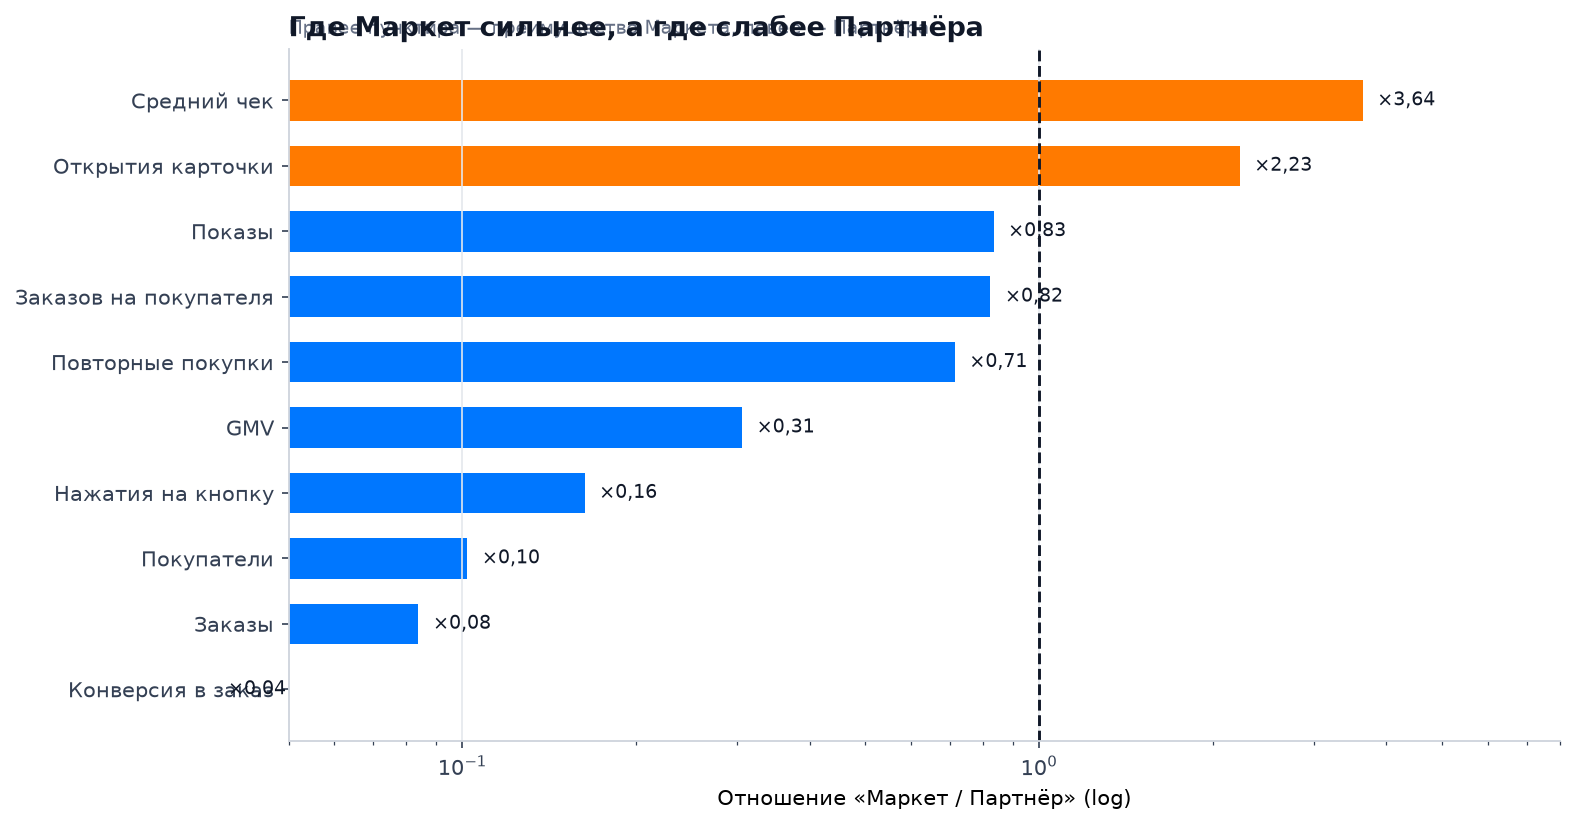

Маркет опережает по 2 из 10 показателей
Сильнее всего: Средний чек, Открытия карточки
Слабее всего: Конверсия в заказ, Заказы, Покупатели


In [74]:
# --- Индекс преимущества Маркета --------------------------------------------
metrics = pd.Series({
    'Показы': IMP_VK/IMP_PT,
    'Открытия карточки': OPEN_VK/OPEN_PT,
    'Нажатия на кнопку': CLICK_VK/CLICK_PT,
    'Заказы': ORD_VK/ORD_PT,
    'GMV': GMV_VK/GMV_PT,
    'Покупатели': BUY_VK/BUY_PT,
    'Средний чек': AOV_VK/AOV_PT,
    'Заказов на покупателя': OPB_VK/OPB_PT,
    'Повторные покупки': REP_VK/REP_PT,
    'Конверсия в заказ': CR2_VK/CR2_PT,
}).sort_values()

fig, ax = plt.subplots(figsize=(10.6, 5.6))
colors = [C_PT if v >= 1 else C_VK for v in metrics.values]
bars = ax.barh(metrics.index, metrics.values, color=colors, height=0.62)
ax.axvline(1, color='#101828', lw=1.4, ls='--')
ax.set_xscale('log')
ax.set_xlabel('Отношение «Маркет / Партнёр» (log)')
ax.set_title('Где Маркет сильнее, а где слабее Партнёра')
subtitle(ax, 'Правее пунктира — преимущество Маркета, левее — Партнёра')
for b, v in zip(bars, metrics.values):
    ax.text(v*1.06, b.get_y()+b.get_height()/2, f'×{v:.2f}'.replace('.', ','), va='center', fontsize=9)
ax.set_xlim(0.05, 8)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print('Маркет опережает по', int((metrics>1).sum()), 'из', len(metrics), 'показателей')
print('Сильнее всего:', ', '.join(metrics[metrics>1].sort_values(ascending=False).head(3).index))
print('Слабее всего:', ', '.join(metrics.sort_values().head(3).index))

**Легенда к индексу преимущества.** Горизонтальные столбцы — отношение показателя Маркета к Партнёру; пунктир на 1 — паритет; синие столбцы — отставание, оранжевые — преимущество. Маркет опережает только по двум показателям: **средний чек (×3,64) и открытия карточки (×2,23)**. По показам он уже отстаёт (×0,83). Отставание катастрофическое в заказах (×0,08), покупателях (×0,10), конверсии (×0,04) и нажатиях (×0,16). Один график показывает: **Маркет — машина внимания, Партнёр — машина сделок**.

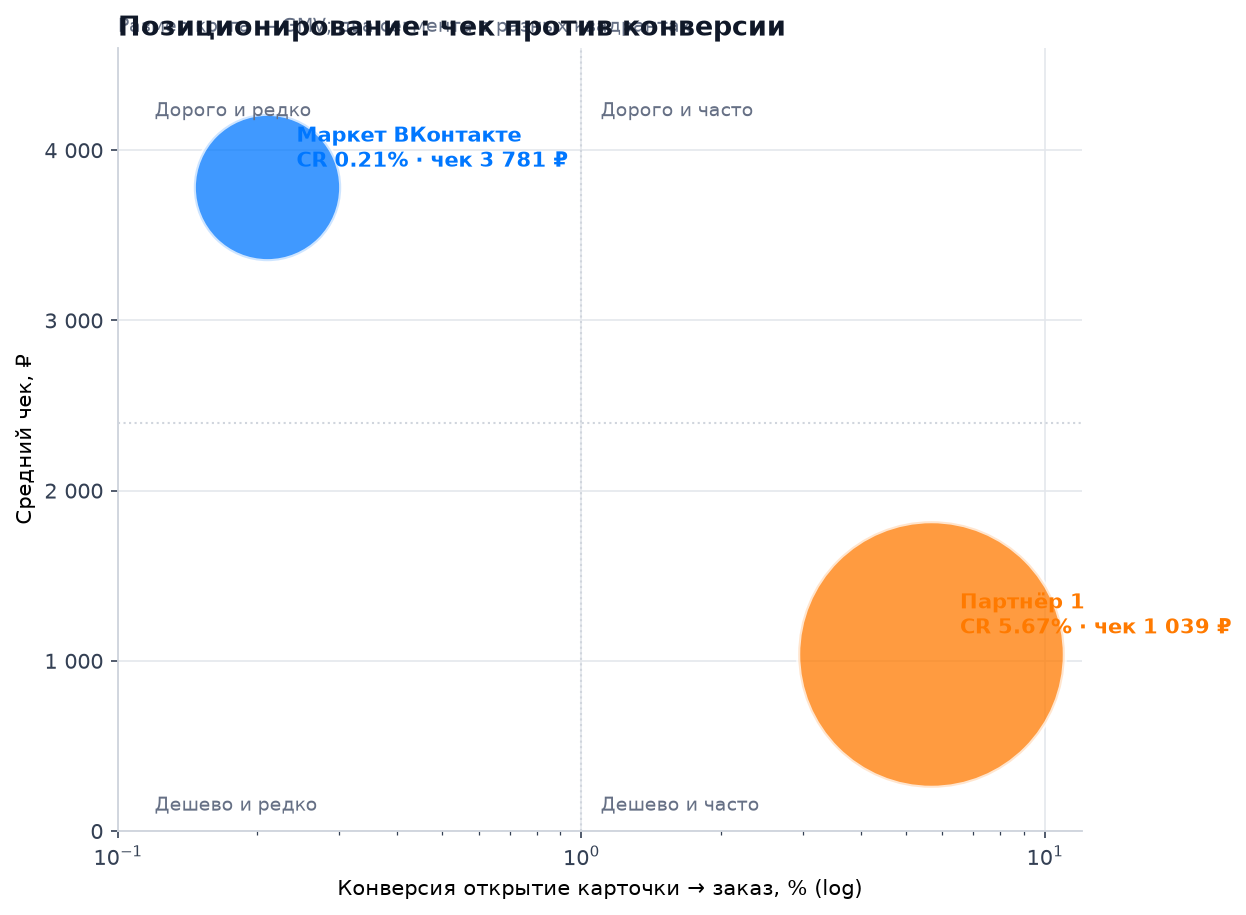

In [75]:
# --- Позиционирование: чек vs конверсия -------------------------------------
fig, ax = plt.subplots(figsize=(8.4, 6.2))
points = [('Маркет ВКонтакте', CR2_VK, AOV_VK, GMV_VK, C_VK),
          ('Партнёр 1', CR2_PT, AOV_PT, GMV_PT, C_PT)]
for name, cr, aov, gmv, c in points:
    ax.scatter(cr, aov, s=gmv/1e6*3.2, color=c, alpha=0.75, edgecolors='white', linewidths=2, zorder=3)
    ax.annotate(f'{name}\nCR {cr:.2f}% · чек {aov:,.0f} ₽'.replace(',', ' '),
                (cr, aov), xytext=(14, 10), textcoords='offset points', fontsize=10, fontweight='bold', color=c)
ax.set_xscale('log')
ax.set_xlabel('Конверсия открытие карточки → заказ, % (log)')
ax.set_ylabel('Средний чек, ₽')
ax.set_title('Позиционирование: чек против конверсии')
subtitle(ax, 'Размер круга — GMV; два сегмента в разных квадрантах')
ax.set_xlim(0.1, 12)
ax.set_ylim(0, 4600)
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v,p: f'{v:,.0f}'.replace(',', ' ')))
ax.axvline(1, color='#D0D5DD', lw=1, ls=':')
ax.axhline(2400, color='#D0D5DD', lw=1, ls=':')
ax.text(0.12, 4200, 'Дорого и редко', fontsize=9, color='#667085')
ax.text(1.1, 4200, 'Дорого и часто', fontsize=9, color='#667085')
ax.text(0.12, 120, 'Дешево и редко', fontsize=9, color='#667085')
ax.text(1.1, 120, 'Дешево и часто', fontsize=9, color='#667085')
plt.tight_layout()
plt.show()

**Легенда к позиционированию.** Оси: X — конверсия из открытия карточки в заказ (лог), Y — средний чек; размер круга — GMV. Маркет в левом верхнем углу: **дорого и редко** (3 781 ₽, 0,21%). Партнёр — в правом нижнем: **дешево и часто** (1 039 ₽, 5,67%). Это не конкуренты за одного покупателя, а два разных рынка: Маркет обслуживает редкие крупные покупки, Партнёр — повседневные. Отсюда стратегический вывод: не пытаться копировать Партнёра, а усиливать свою нишу и одновременно использовать партнёрский слой для массового спроса.

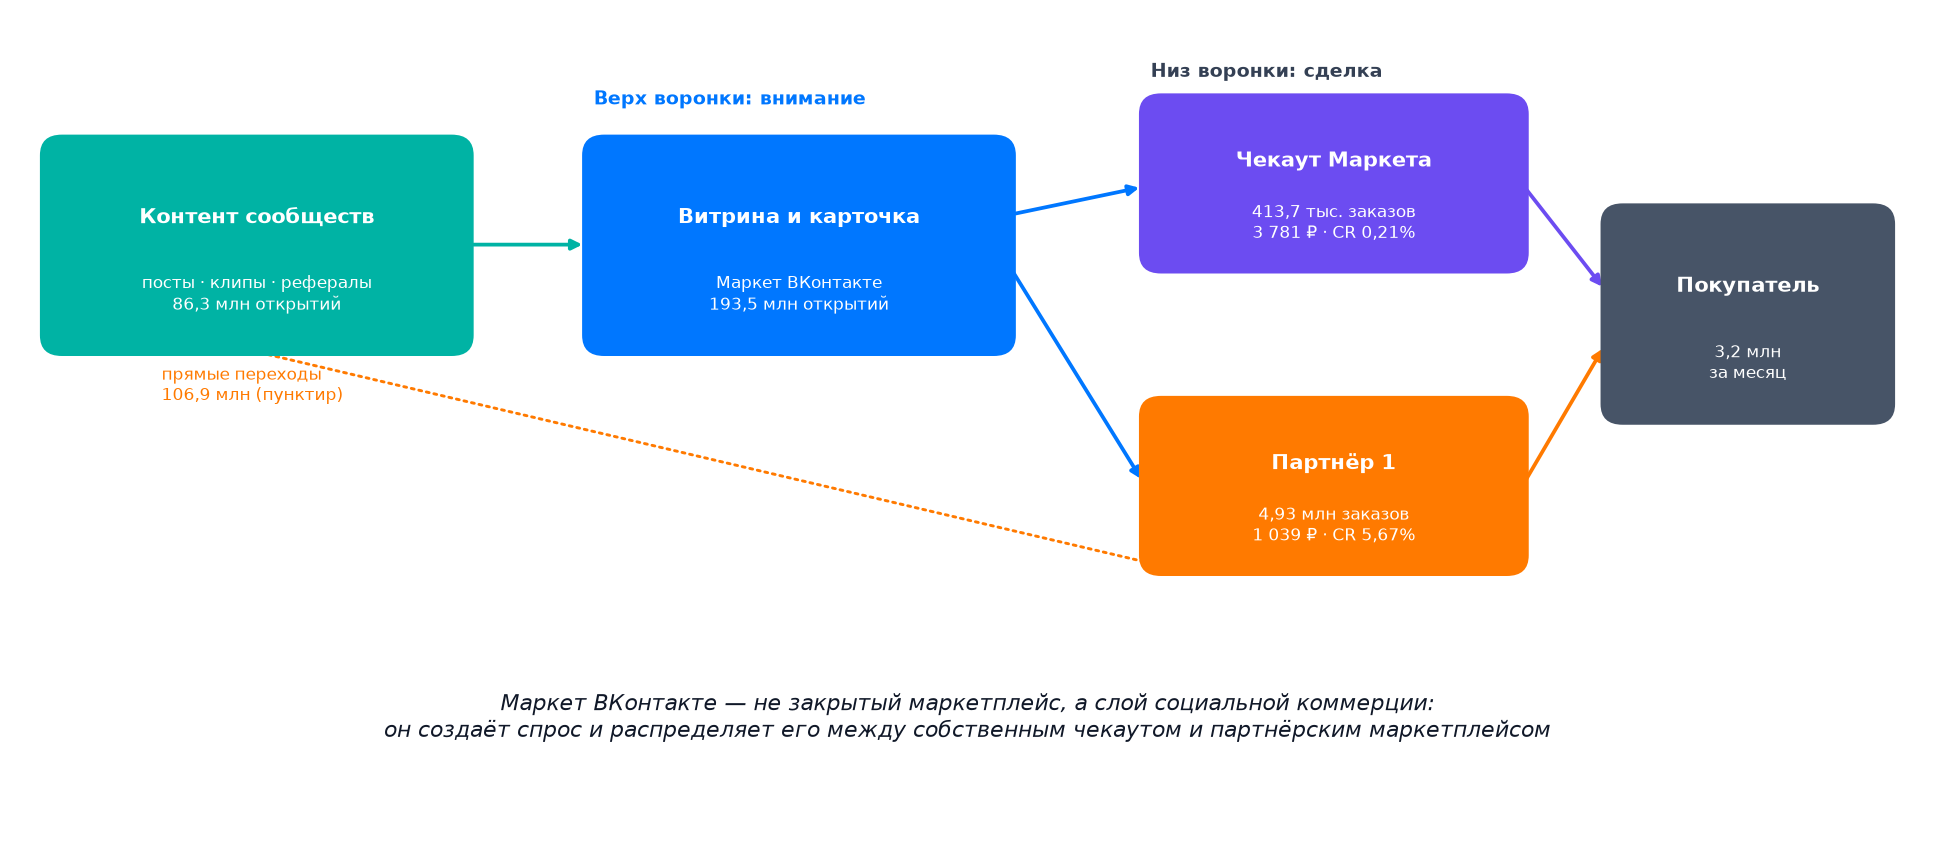

In [76]:
# --- Схема: как устроен Маркет ВКонтакте ------------------------------------
fig, ax = plt.subplots(figsize=(13, 5.8))
ax.set_xlim(0, 13); ax.set_ylim(0, 6); ax.axis('off')

def box(x, y, w, h, title, sub, color, tc='white', fs=10):
    p = FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.03,rounding_size=0.15',
                       linewidth=0, facecolor=color, zorder=2)
    ax.add_patch(p)
    ax.text(x+w/2, y+h*0.63, title, ha='center', va='center', color=tc,
            fontsize=fs, fontweight='bold', zorder=3)
    ax.text(x+w/2, y+h*0.27, sub, ha='center', va='center', color=tc,
            fontsize=8.3, zorder=3)

def arrow(x1, y1, x2, y2, color='#667085', style='-|>', lw=1.8, ls='-'):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=color, lw=lw, linestyle=ls,
                                shrinkA=2, shrinkB=2), zorder=1)

box(0.2, 3.55, 2.9, 1.55, 'Контент сообществ', 'посты · клипы · рефералы\n86,3 млн открытий', C_TEAL)
box(3.9, 3.55, 2.9, 1.55, 'Витрина и карточка', 'Маркет ВКонтакте\n193,5 млн открытий', C_VK)
box(7.7, 4.15, 2.6, 1.25, 'Чекаут Маркета', '413,7 тыс. заказов\n3 781 ₽ · CR 0,21%', C_ACC)
box(7.7, 1.95, 2.6, 1.25, 'Партнёр 1', '4,93 млн заказов\n1 039 ₽ · CR 5,67%', C_PT)
box(10.85, 3.05, 1.95, 1.55, 'Покупатель', '3,2 млн\nза месяц', '#475467')

arrow(3.1, 4.33, 3.9, 4.33, C_TEAL)
arrow(6.8, 4.55, 7.7, 4.75, C_VK)
arrow(6.8, 4.15, 7.7, 2.6, C_VK)
arrow(10.3, 4.75, 10.85, 4.0, C_ACC)
arrow(10.3, 2.6, 10.85, 3.6, C_PT)
arrow(1.65, 3.55, 8.0, 1.95, C_PT, ls=':', lw=1.4)

ax.text(1.0, 3.2, 'прямые переходы\n106,9 млн (пунктир)', fontsize=8, color=C_PT)
ax.text(3.95, 5.35, 'Верх воронки: внимание', fontsize=9, color=C_VK, fontweight='bold')
ax.text(7.75, 5.55, 'Низ воронки: сделка', fontsize=9, color='#344054', fontweight='bold')
ax.text(6.5, 0.75, 'Маркет ВКонтакте — не закрытый маркетплейс, а слой социальной коммерции:\n'
                   'он создаёт спрос и распределяет его между собственным чекаутом и партнёрским маркетплейсом',
        ha='center', fontsize=10.5, color='#101828', style='italic')
plt.tight_layout()
plt.show()

**Легенда к схеме.** Пять блоков и стрелки — поток пользователя. Слева контент сообществ (посты, клипы, рефералы) создаёт 86,3 млн открытий. Он ведёт в витрину и карточку Маркета (193,5 млн открытий). Дальше поток расходится: в собственный чекаут Маркета (413,7 тыс. заказов со средним чеком 3 781 ₽) и в Партнёра (4,93 млн заказов со средним чеком 1 039 ₽). Пунктирная стрелка — прямые переходы к Партнёру без открытия карточки (106,9 млн). Оба потока сходятся к покупателю (3,2 млн человек). Схема фиксирует главное: **Маркет — верхняя часть воронки и точка распределения, а не конечный магазин**.

In [77]:
# --- Матрица ролей -----------------------------------------------------------
roles = pd.DataFrame([
    ('1. Витрина и discovery',
     '45,5% показов, 69,0% открытий карточки; 66,6 млн видящих товары',
     'Создаёт спрос и показывает товар внутри соцграфа'),
    ('2. Контент-драйвер',
     '86,3 млн открытий из постов и клипов, 82,3 млн — реферальные (95,4%)',
     'Превращает авторский контент в переход в карточку'),
    ('3. Инфраструктура для SMB',
     '9 754 сообщества, 5 737 с чекаутом, 3 961 с активным каталогом',
     'Даёт малому бизнесу витрину и инструменты без своего сайта'),
    ('4. Нишевый маркетплейс высокого чека',
     '3 781 ₽ средний чек (×3,64 к Партнёру), 1,56 млрд ₽ GMV',
     'Обслуживает редкие дорогие покупки, а не повседневный спрос'),
    ('5. Трафиковый шлюз для Партнёра',
     '5,73 млрд показов, 4,93 млн заказов, 5,12 млрд ₽ GMV, 106,9 млн прямых переходов',
     'Монетизирует массовый спрос через партнёрский маркетплейс'),
    ('6. Рекламно-медийный слой',
     '92,4 млн ₽ рекламных трат в выборке, 542 рекламодателя',
     'Продаёт доступ к аудитории и результаты, а не только показы'),
], columns=['Роль', 'Доказательство из данных', 'Что это означает'])

display(roles.style.hide(axis='index').set_properties(**{'text-align':'left'}).set_table_styles([
    {'selector':'th','props':[('text-align','left'),('background','#F2F4F7')]}]))

Роль,Доказательство из данных,Что это означает
1. Витрина и discovery,"45,5% показов, 69,0% открытий карточки; 66,6 млн видящих товары",Создаёт спрос и показывает товар внутри соцграфа
2. Контент-драйвер,"86,3 млн открытий из постов и клипов, 82,3 млн — реферальные (95,4%)",Превращает авторский контент в переход в карточку
3. Инфраструктура для SMB,"9 754 сообщества, 5 737 с чекаутом, 3 961 с активным каталогом",Даёт малому бизнесу витрину и инструменты без своего сайта
4. Нишевый маркетплейс высокого чека,"3 781 ₽ средний чек (×3,64 к Партнёру), 1,56 млрд ₽ GMV","Обслуживает редкие дорогие покупки, а не повседневный спрос"
5. Трафиковый шлюз для Партнёра,"5,73 млрд показов, 4,93 млн заказов, 5,12 млрд ₽ GMV, 106,9 млн прямых переходов",Монетизирует массовый спрос через партнёрский маркетплейс
6. Рекламно-медийный слой,"92,4 млн ₽ рекламных трат в выборке, 542 рекламодателя","Продаёт доступ к аудитории и результаты, а не только показы"


**Легенда к матрице ролей.** Шесть ролей, каждая подтверждена конкретными числами из датасета. Матрица отвечает на вопрос кейса не декларацией, а Evidence-based: «роль» → «чем доказано» → «что означает для стратегии». Роли не исключают друг друга: платформа одновременно является витриной, контентным драйвером, инфраструктурой для малого бизнеса, нишевым маркетплейсом, шлюзом для партнёра и рекламным слоем. Вместе они описывают **социальную коммерцию** как отдельную модель, отличную от классического маркетплейса.

### 8.2. Ответ на вопрос кейса: роль Маркета ВКонтакте

**Короткий ответ.** Маркет ВКонтакте — это не «ещё один маркетплейс», а **слой социальной коммерции внутри социальной сети**: инфраструктура, которая превращает внимание к контенту в интерес к товару и распределяет этот интерес между собственным чекаутом и внешним партнёрским маркетплейсом.

**Развёрнутый ответ — пять тезисов, каждый с доказательством.**

1. **Маркет владеет верхом воронки, но не низом.** 45,5% показов и 69,0% открытий карточки — за Маркетом; 92,3% заказов и 76,6% GMV — за Партнёром. Точка перелома — нажатие на кнопку: 14,0% против 86,0%. Значит, Маркет решает задачу **обнаружения и интереса**, а сделку отдаёт тому, кому доверяют.

2. **Маркет — это дистрибуция контента, а не каталог.** 95,4% открытий из постов и клипов — реферальные; у Партнёра 74,7% всех открытий приходят из клипов. Витрина магазина у Партнёра даёт лишь 0,8%. Вывод: ценность платформы — **социальный граф и авторы**, а не полка товаров. Именно поэтому ВКонтакте строит социальную коммерцию вокруг авторов, а не вокруг склада.

3. **Маркет — инфраструктура для малого бизнеса, но с низкой активацией.** 9 754 сообщества, 40,6% имеют активный каталог, 58,8% подключили чекаут, но только 3,1% получили хотя бы один заказ. Инструменты есть у многих, результат — у единиц. Роль платформы — **снижать порог входа**, а узкое место — не подключение, а спрос и умение его привести.

4. **Маркет — нишевый маркетплейс высокого чека.** Средний чек 3 781 ₽ в 3,64 раза выше партнёрского, но заказов в 11,9 раза меньше. Конверсия из открытия в заказ — 0,21% против 5,67%. Это осознанная позиция: **дорогие редкие покупки** (техника, мебель, крупные товары), где пользователь готов изучать карточку, но не готов платить внутри соцсети.

5. **Маркет — трафиковый и рекламный шлюз экосистемы.** 5,73 млрд показов, 4,93 млн заказов и 5,12 млрд ₽ GMV Партнёра — это монетизация того же трафика ВКонтакте. Плюс 106,9 млн прямых переходов без открытия карточки. Роль Маркета здесь — **быть входом в e-commerce**, даже если покупка происходит у партнёра.

**Формула роли.** Маркет ВКонтакте = *внимание (охват и контент)* × *интерес (карточка и витрина)* × *распределение (свой чекаут или партнёр)*. Платформа зарабатывает не только на своём обороте, но и на том, что направляет спрос туда, где он с большей вероятностью превратится в сделку.

### 8.3. Что это означает практически

| Уровень | Наблюдение | Действие |
|---------|-----------|----------|
| Продукт | CR открытие → заказ 0,21% | Упростить чекаут, показать доставку и возврат, добавить оплату при получении |
| Ассортимент | «Гардероб» — 33 млн открытий, 29 тыс. заказов | Разобраться с размерной сеткой, фото, ценой; это крупнейший нереализованный спрос |
| Трафик | 74,7% Партнёра — клипы | Диверсифицировать каналы, иначе алгоритм клипов = единая точка отказа |
| Продавцы | 3 961 с каталогом, 298 с заказами | Программа активации: трафик, обучение, промо-слоты для «спящих» |
| Удержание | 19,0% повторных против 26,6% | CRM-механики, подписки, персональные подборки |
| Данные | 36,7% регионов Партнёра — «Не указан» | Починить передачу геоданных: без этого нельзя считать локальный спрос |

**Легенда к таблице действий.** Слева — уровень решения, в центре — наблюдение из данных, справа — конкретное действие. Таблица переводит аналитику в план: каждое действие привязано к измеримому разрыву. Приоритет — первые две строки: конверсия и «Гардероб», потому что там сосредоточен наибольший нереализованный потенциал.

## 9. Выводы

### 9.1. Десять главных фактов

1. **Датасет описывает два разных бизнеса под одним брендом.** Маркет — 45,5% показов, 69,0% открытий, но 7,7% заказов и 23,4% GMV. Партнёр — обратная пропорция.
2. **Воронка Маркета ломается на кнопке.** Из 193,5 млн открытий только 3,1% доходят до нажатия, тогда как у Партнёра — 42,2%.
3. **Средний чек Маркета — 3 781 ₽, Партнёра — 1 039 ₽.** Это два разных потребительских сценария, а не один рынок с разной ценой.
4. **Повторные покупки: 19,0% против 26,6%.** Партнёр лучше удерживает, несмотря на меньший чек.
5. **Трафик Партнёра — это клипы.** 74,7% открытий из клипов, 94,8% — из реферальных постов и клипов. Платформа продаёт не полку, а контент.
6. **Маркет диверсифицирован, но непрозрачен.** «Другое» — 40,2% открытий; «Витрина» — 39,1%. У Партнёра концентрация выше, но канал понятен.
7. **9 754 сообщества — это «длинный хвост».** Медиана 490 подписчиков, 32,5% без каталога, 24,3% не публикуют контент, 3,1% имеют заказы.
8. **Каталог и трафик важнее подписчиков.** Корреляция заказов с активными товарами — 0,26, с открытиями карточки — 0,19, с подписчиками — 0,16. Связи умеренные, но направление устойчивое.
9. **Аудитории различаются возрастом, а не полом.** Женщины — 72,8% и 74,5%. Но 18–24 у Маркета — 16,4%, у Партнёра — 5,1%; 55+ — 9,0% против 20,1%.
10. **География концентрирована, но по-разному.** Топ-10 регионов дают 47,2% покупателей Маркета; у Партнёра картина ровнее, но 36,7% регионов неизвестны.

### 9.2. Что подтвердилось и что опровергнуто

| Гипотеза | Проверка | Вердикт |
|----------|----------|---------|
| «Маркет — маленький, но растущий» | Внутри месяца DAU стабилен, тренда нет; растёт Партнёр | **Опровергнуто**: Маркет стабилен, не растёт |
| «Маркет проигрывает из-за охвата» | Показы сопоставимы (4,8 против 5,7 млрд) | **Опровергнуто**: проблема не в охвате |
| «Маркет проигрывает из-за конверсии» | 0,21% против 5,67% на выходе из карточки | **Подтверждено** |
| «Клипы — главный драйвер» | 74,7% открытий Партнёра, 8,9% у Маркета | **Подтверждено для Партнёра**, не для Маркета |
| «Больше подписчиков — больше продаж» | ρ ≈ 0,2; у лидеров бывает малая аудитория | **Опровергнуто** |
| «Молодая аудитория — драйвер» | 18–24: 16,4% у Маркета, 5,1% у Партнёра | **Частично**: молодёжь у Маркета, деньги у Партнёра |

**Легенда к таблице гипотез.** Каждая строка — проверяемая гипотеза, способ проверки и вердикт. Такой формат защищает от «красивых» выводов: например, распространённое мнение «нужно больше охвата» данные не поддерживают — охват уже есть, а конверсии нет.

## 10. Ограничения анализа и как их читать

1. **Таблица 1 — выборка, а не вся база.** 9 754 сообщества дают 3 478 заказов и 9,97 млн ₽ GMV, тогда как весь Маркет — 413 740 заказов и 1,56 млрд ₽. Микроуровень показывает структуру и поведение, но не масштаб. Экстраполировать доли на всю базу можно только с оговоркой.
2. **Расхождения и вложенные строки.** Сумма по шести каналам источников совпадает с открытиями, но строка «в т.ч. реферальные» — вложенная; заказы по категориям больше итога на 5,2%; дневные уникальные не суммируются. Все расчёты выполнены на наиболее надёжном уровне для каждого показателя; расхождения зафиксированы, а не скрыты.
3. **Служебные категории.** «Другое», «Все товары», «Не определена» исключены из конверсий, но остаются в суммах. Иначе выводы были бы искажены (например, 29,1 млн открытий при 41 заказе дали бы CR 0,0001%).
4. **Регион «Не указан».** 36,7% покупателей Партнёра — это не случайные пропуски, а системная особенность выгрузки. Географические выводы по Партнёру условны.
5. **Корреляция не равна причинности.** Связь «каталог → заказы» может объясняться третьим фактором — например, размером бизнеса. Все причинные утверждения сформулированы как гипотезы.
6. **Один месяц наблюдений.** Сентябрь 2026 не позволяет отделить сезонность от тренда. Для устойчивых выводов нужен ряд минимум за 6–12 месяцев.
7. **Отсутствие внешних источников.** По условию практической работы анализ построен только на файле; публичные данные ВКонтакте не привлекались. Это ограничивает проверку абсолютных уровней, но не влияет на внутреннюю согласованность выводов.

**Легенда к ограничениям.** Список фиксирует, где заканчивается достоверность. Ключевое: выводы о **структуре и различиях** (Маркет vs Партнёр) устойчивы, потому что подтверждаются несколькими независимыми листами. Выводы об **абсолютных уровнях** (сколько всего продавцов, каков рынок) — ограничены выборкой и одним месяцем.

## 11. Воспроизводимость и словарь метрик

### 11.1. Как воспроизвести

1. Положить Excel-файл в ту же папку, что и `analytics.ipynb`.
2. Запустить все ячейки сверху вниз (Kernel → Restart & Run All).
3. Ноутбук сам найдёт файл, прочитает 7 листов, построит 40+ графиков и таблиц.

Зависимости: `pandas`, `numpy`, `matplotlib`, `seaborn`, `openpyxl`. Специальных библиотек для визуализации не требуется.

### 11.2. Словарь метрик

| Метрика | Формула | Смысл |
|---------|---------|-------|
| Показы | из источника | сколько раз товар показан |
| Открытия карточки | из источника | сколько раз открыта карточка товара |
| CR показ → открытие | открытия / показы | привлекательность карточки в ленте |
| CR открытие → заказ | заказы / открытия | способность карточки продавать |
| CR показ → заказ | заказы / показы | сквозная эффективность |
| Средний чек (AOV) | GMV / заказы | средняя стоимость заказа |
| GMV на покупателя | GMV / покупатели | ценность покупателя за период |
| Заказов на покупателя | заказы / покупатели | интенсивность покупок |
| Доля повторных | из источника | удержание |
| ER | (лайки + репосты) / просмотры | вовлечённость контента |
| Доля Маркета | VK / (VK + Партнёр) | вклад сегмента в показатель |

**Легенда к словарю.** Таблица нужна, чтобы любой читатель мог пересчитать метрику самостоятельно. Все производные показатели в ноутбуке считаются по этим формулам из абсолютных значений, а не берутся из округлённых ячеек.

---

### Итог

Маркет ВКонтакте в этом датасете — **не магазин, а слой социальной коммерции**. Он превращает контент и социальный граф в интерес к товару, удерживает верх воронки (45,5% показов, 69,0% открытий) и распределяет спрос между собственным нишевым чекаутом высокого чека и массовым партнёрским маркетплейсом. Его сильные стороны — охват, контентная дистрибуция и инфраструктура для малого бизнеса. Его слабые места — конверсия из карточки в заказ (0,21%), удержание (19,0% повторных) и зависимость от одного партнёра, который забирает 92,3% заказов и 76,6% GMV. Рост платформы в сентябре 2026 обеспечивал не Маркет, а Партнёр — и это главный стратегический сигнал датасета.